# Portfólio Consolidado de Análise de Dados
## Contendo todos os notebooks dos alunos
### Gerado em: 2026-11-09 22:08

## Aula 1 - Webscraping

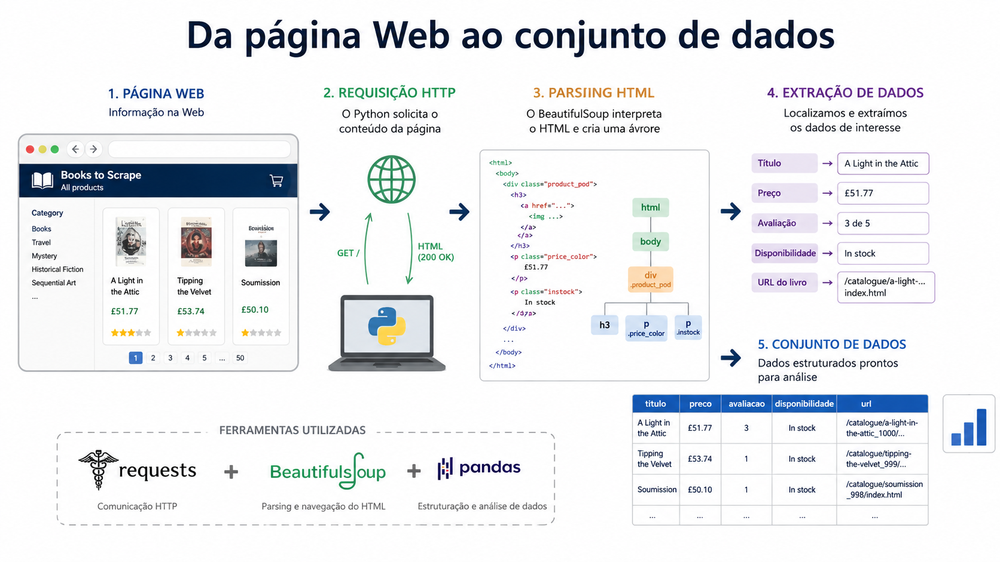

Nesta aula, vamos compreender como informações publicadas em páginas Web podem ser **requisitadas, interpretadas, localizadas, extraídas e estruturadas** com Python.

## 1. O que é Web Scraping?

**Web Scraping** é o processo automatizado de coleta de informações disponíveis em páginas Web.

Em termos computacionais, o processo envolve três operações principais:

1. **Aquisição:** obtenção do conteúdo da página por meio de uma requisição HTTP;
2. **Parsing:** interpretação da estrutura do documento HTML;
3. **Extração:** localização e transformação dos elementos de interesse em dados utilizáveis.

Um fluxo típico pode ser representado como:

```text
URL → Requisição HTTP → HTML → Parser → Elementos → Dados estruturados
```

### Exemplos de aplicação

- monitoramento de preços;
- coleta de notícias e documentos;
- criação de bases para análise de mercado;
- mineração de dados públicos;
- acompanhamento de indicadores;
- construção de datasets para pesquisa.

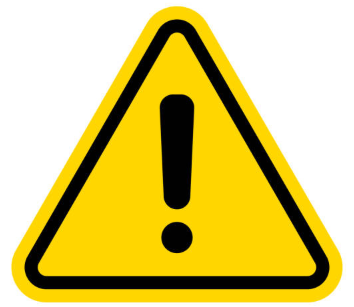
# Atenção - Evite práticas ilegais e antiéticas
#### Respeite as regras contidas do documento **Robots.txt**. 

A disponibilidade pública de uma página não implica autorização irrestrita para coleta automatizada. Termos de uso, limites de requisição, privacidade e legislação aplicável devem ser considerados.

O scraper deve seguir as regras estabelecidas no arquivo **robots.txt** do site e respeitar os termos de uso para evitar práticas ilegais ou antiéticas.

# 2. Fundamentos de HTML

## HTML: HyperText Markup Language

**HTML** é a linguagem de marcação utilizada para representar a estrutura de uma página Web.

- Geralmente contém três componentes
    - Tag de abertura;
    - Conteúdo;
    - Tag de fechamento
    
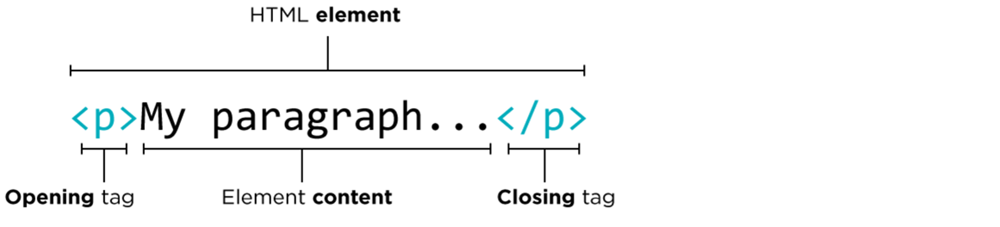

Tags de abertura também podem conter atributos:

```html
<tag atributo="valor">conteúdo</tag>
```

Exemplo:

```html
<p class="preco">R$ 89,90</p>
```

Neste elemento:

| Componente | Valor |
|---|---|
| Tag | `p` |
| Atributo | `class` |
| Valor do atributo | `preco` |
| Conteúdo textual | `R$ 89,90` |

Em tarefas de Web Scraping, esses componentes funcionam como **pistas para localizar a informação desejada**.

## Estrutura básica de um documento HTML

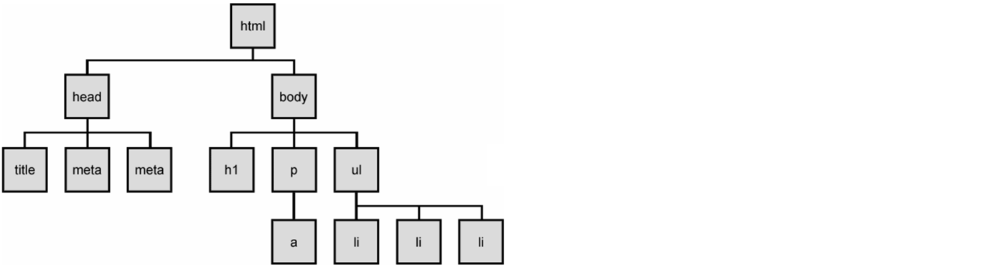

Exemplo codificado:

```html
<!DOCTYPE html>
<html>
    <head>
        <title>Minha página</title>
    </head>

    <body>
        <h1>Título principal</h1>
        <p>Um parágrafo.</p>
        <a href="https://exemplo.com">Um link</a>
    </body>
</html>
```

A estrutura HTML possui natureza **hierárquica**. Por isso, ela pode ser interpretada como uma árvore:

```text
html
├── head
│   └── title
└── body
    ├── h1
    ├── p
    └── a
```

Essa organização será importante quando utilizarmos `BeautifulSoup`.

## Algumas tags HTML frequentes

| Tag | Função típica |
|---|---|
| `<html>` | elemento raiz do documento |
| `<head>` | metadados e configurações |
| `<title>` | título da página |
| `<body>` | conteúdo visível principal |
| `<h1>` ... `<h6>` | títulos e subtítulos |
| `<p>` | parágrafo |
| `<a>` | hiperlink |
| `<img>` | imagem |
| `<div>` | agrupamento genérico |
| `<span>` | agrupamento inline |
| `<ul>` / `<ol>` | listas |
| `<li>` | item de lista |
| `<table>` | tabela |
| `<article>` | conteúdo independente |
| `<nav>` | navegação |

# 3. HTTP: comunicação entre cliente e servidor

**HTTP (Hypertext Transfer Protocol)** é o protocolo utilizado na comunicação entre clientes e servidores Web.

Quando digitamos uma URL no navegador, ocorre, de forma simplificada:

```text
Cliente                          Servidor
   │                                │
   │ -------- HTTP GET -----------> │
   │                                │
   │ <----- HTTP Response --------- │
   │        status + conteúdo       │
```

Em Python, a biblioteca `requests` pode assumir o papel do cliente.

## Métodos HTTP

Alguns métodos HTTP importantes:

| Método | Finalidade geral |
|---|---|
| `GET` | solicitar um recurso |
| `POST` | enviar dados para processamento |
| `PUT` | substituir ou atualizar um recurso |
| `PATCH` | atualizar parcialmente um recurso |
| `DELETE` | solicitar remoção de um recurso |

Nesta aula utilizaremos principalmente **GET**, pois nosso objetivo é solicitar páginas HTML.

## Códigos de status HTTP

Uma resposta HTTP possui um código de status.

| Faixa | Categoria | Exemplo |
|---|---|---|
| `1xx` | Informacional | processamento em andamento |
| `2xx` | Sucesso | `200 OK` |
| `3xx` | Redirecionamento | `301 Moved Permanently` |
| `4xx` | Erro do cliente | `404 Not Found` |
| `5xx` | Erro do servidor | `500 Internal Server Error` |

Para Web Scraping, um `200` normalmente indica que a requisição foi atendida com sucesso.

# 4. Web Scraping não é API

É importante diferenciar duas formas de obter dados de um sistema Web.

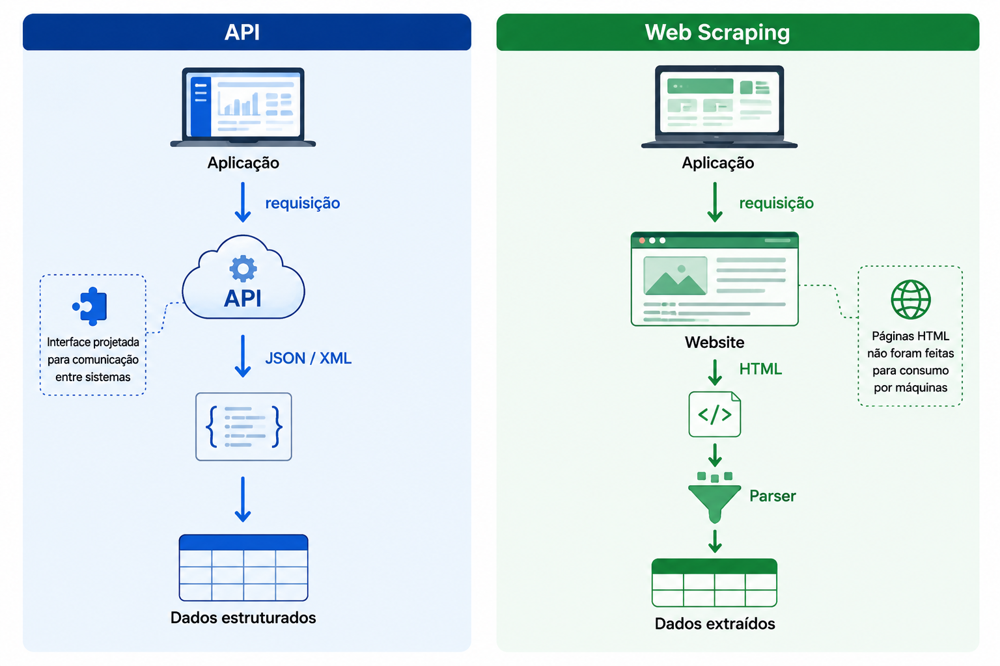

Em tarefas de Web Scraping, os dados precisam ser identificados dentro da estrutura destinada originalmente à apresentação da página.

## Páginas estáticas e páginas dinâmicas

Um ponto fundamental:

```python
requests.get(url)
```

obtém o conteúdo retornado pelo servidor na resposta HTTP.

Entretanto, alguns websites carregam parte dos dados **posteriormente com JavaScript**.

```text
HTML inicial
    │
    ├── conteúdo disponível imediatamente
    │
    └── JavaScript
           │
           └── novas requisições / conteúdo dinâmico
```

Nesses casos, o conteúdo visível no navegador pode não estar presente no HTML obtido diretamente com `requests`.

Ferramentas como **Selenium** e **Playwright** podem ser utilizadas em cenários mais complexos, mas não são necessárias para a prática desta aula.

# 5. Preparando o ambiente

Nesta aula utilizaremos:

- `requests`: comunicação HTTP;
- `BeautifulSoup`: parsing e navegação HTML;
- `re`: expressões regulares;
- `pandas`: estruturação dos dados;
- `urllib.parse`: construção segura de URLs.

In [4]:
# Execute somente se as bibliotecas ainda não estiverem instaladas.
#%pip install requests beautifulsoup4 pandasp

In [5]:
import re
import requests
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urljoin

# 6. Primeiro contato com BeautifulSoup: HTML controlado

Antes de trabalhar com um website real, utilizaremos um pequeno documento HTML criado especificamente para a aula.

Essa estratégia permite aprender os comandos do `BeautifulSoup` sem a complexidade adicional de páginas reais.

In [6]:
html = '''
<html>
    <head>
        <title>Livraria Exemplo</title>
    </head>

    <body>
        <h1>Catálogo de livros</h1>

        <div class="produto" data-categoria="programacao">
            <h2>Python para Dados</h2>
            <p class="preco">R$ 89,90</p>
            <p class="estoque">Disponível</p>
            <a href="/python">Detalhes</a>
        </div>

        <div class="produto" data-categoria="ia">
            <h2>Machine Learning</h2>
            <p class="preco">R$ 120,00</p>
            <p class="estoque">Disponível</p>
            <a href="/machine-learning">Detalhes</a>
        </div>
    </body>
</html>
'''

## Realizando o parsing

O **parsing** transforma o texto HTML em uma estrutura que pode ser navegada programaticamente.

In [7]:
soup = BeautifulSoup(html, 'html.parser')

In [8]:
print(soup.prettify())

<html>
 <head>
  <title>
   Livraria Exemplo
  </title>
 </head>
 <body>
  <h1>
   Catálogo de livros
  </h1>
  <div class="produto" data-categoria="programacao">
   <h2>
    Python para Dados
   </h2>
   <p class="preco">
    R$ 89,90
   </p>
   <p class="estoque">
    Disponível
   </p>
   <a href="/python">
    Detalhes
   </a>
  </div>
  <div class="produto" data-categoria="ia">
   <h2>
    Machine Learning
   </h2>
   <p class="preco">
    R$ 120,00
   </p>
   <p class="estoque">
    Disponível
   </p>
   <a href="/machine-learning">
    Detalhes
   </a>
  </div>
 </body>
</html>



## 6.1 `find()`: localizar a primeira ocorrência

O método `find()` retorna o **primeiro elemento** que corresponde ao critério informado.

In [9]:
soup.find('h1').text

'Catálogo de livros'

In [10]:
titulo = soup.find('h1')

### A propriedade `.text`

O objeto retornado pelo `BeautifulSoup` contém a tag completa.

```html
<h1>Catálogo de livros</h1>
```

Quando queremos apenas seu conteúdo textual:

```python
elemento.text
```

ou, preferencialmente quando há espaços e quebras de linha:

```python
elemento.get_text(strip=True)
```

In [11]:
# titulo.get_text(strip=True)
titulo.text

'Catálogo de livros'

## 6.2 `find_all()`: localizar todas as ocorrências

Enquanto `find()` retorna uma ocorrência, `find_all()` retorna uma coleção de elementos.

In [12]:
produtos = soup.find_all('div')
produtos

[<div class="produto" data-categoria="programacao">
 <h2>Python para Dados</h2>
 <p class="preco">R$ 89,90</p>
 <p class="estoque">Disponível</p>
 <a href="/python">Detalhes</a>
 </div>,
 <div class="produto" data-categoria="ia">
 <h2>Machine Learning</h2>
 <p class="preco">R$ 120,00</p>
 <p class="estoque">Disponível</p>
 <a href="/machine-learning">Detalhes</a>
 </div>]

In [13]:
len(produtos)

2

## 6.3 Localizando elementos por classe

O atributo HTML `class` é muito utilizado para identificar grupos de elementos.

No `BeautifulSoup`, podemos utilizar:

```python
class_="nome_da_classe"
```

O caractere `_` é necessário porque `class` é uma palavra reservada da linguagem Python.

In [14]:
precos = soup.find_all('p', class_='preco')

for i in precos:
    print(i.get_text(strip=True))

R$ 89,90
R$ 120,00


## 6.4 Localizando elementos por atributos

Também podemos pesquisar elementos por outros atributos.

In [15]:
produto_ia = soup.find('div', attrs={'data-categoria': 'ia'})
produto_ia

<div class="produto" data-categoria="ia">
<h2>Machine Learning</h2>
<p class="preco">R$ 120,00</p>
<p class="estoque">Disponível</p>
<a href="/machine-learning">Detalhes</a>
</div>

## 6.5 Extraindo atributos

Considere:

```html
<a href="/python">Detalhes</a>
```

O texto é `Detalhes`, enquanto o destino do link está no atributo `href`.

In [16]:
link = soup.find('a')
print(link)
print("Texto do link:", link.get_text(strip=True))
print("URL do link:", link['href'])

<a href="/python">Detalhes</a>
Texto do link: Detalhes
URL do link: /python


Uma alternativa mais segura para atributos opcionais é utilizar `.get()`:

In [17]:
link.get("href")

'/python'

## 6.6 Localização por texto

Também é possível localizar elementos por conteúdo textual.

In [18]:
soup.find("h2", string="Machine Learning")

<h2>Machine Learning</h2>

Quando não conhecemos exatamente o texto, expressões regulares podem ser úteis.

In [19]:
soup.find("h2", string=re.compile("machine", re.IGNORECASE))

<h2>Machine Learning</h2>

# 7. Navegando pela árvore HTML

Como o HTML possui estrutura hierárquica, um elemento pode ter:

- **pai** (`parent`);
- **filhos** (`children` ou `contents`);
- elementos anteriores e posteriores.

Considere o primeiro produto:

In [20]:
primeiro_produto = soup.find('div', class_='produto')
primeiro_produto

<div class="produto" data-categoria="programacao">
<h2>Python para Dados</h2>
<p class="preco">R$ 89,90</p>
<p class="estoque">Disponível</p>
<a href="/python">Detalhes</a>
</div>

In [21]:
primeiro_produto.parent.name

'body'

In [22]:
primeiro_produto.contents

['\n',
 <h2>Python para Dados</h2>,
 '\n',
 <p class="preco">R$ 89,90</p>,
 '\n',
 <p class="estoque">Disponível</p>,
 '\n',
 <a href="/python">Detalhes</a>,
 '\n']

In [23]:
primeiro_produto.contents[1]

<h2>Python para Dados</h2>

In [24]:
list(primeiro_produto.children)

['\n',
 <h2>Python para Dados</h2>,
 '\n',
 <p class="preco">R$ 89,90</p>,
 '\n',
 <p class="estoque">Disponível</p>,
 '\n',
 <a href="/python">Detalhes</a>,
 '\n']

In [25]:
for filho in primeiro_produto.children:
    print(filho)



<h2>Python para Dados</h2>


<p class="preco">R$ 89,90</p>


<p class="estoque">Disponível</p>


<a href="/python">Detalhes</a>




> **Observação:** `children` e `contents` acessam os filhos imediatos, incluindo tags e nós de texto. A diferença é que contents retorna uma lista, enquanto children fornece um iterador.

# 8. Seletores CSS

O `BeautifulSoup` também permite utilizar seletores CSS.

**CSS (Cascading Style Sheets)** é a linguagem utilizada para definir a **aparência e o layout dos elementos HTML** de uma página, como cores, fontes, tamanhos e posicionamento.

Um seletor **CSS** é uma expressão utilizada para identificar quais **elementos HTML receberão determinado estilo**. Em tarefas de Web Scraping, podemos reutilizar esses seletores para localizar elementos na página.

Essa abordagem é útil porque o mesmo raciocínio empregado no inspetor do navegador pode ser utilizado no Python.

Exemplos:

```css
div.produto
div.produto h2
p.preco
a
```

In [26]:
soup.select('div.produto')

[<div class="produto" data-categoria="programacao">
 <h2>Python para Dados</h2>
 <p class="preco">R$ 89,90</p>
 <p class="estoque">Disponível</p>
 <a href="/python">Detalhes</a>
 </div>,
 <div class="produto" data-categoria="ia">
 <h2>Machine Learning</h2>
 <p class="preco">R$ 120,00</p>
 <p class="estoque">Disponível</p>
 <a href="/machine-learning">Detalhes</a>
 </div>]

In [27]:
soup.select('div.produto h2')

[<h2>Python para Dados</h2>, <h2>Machine Learning</h2>]

In [28]:
soup.select_one('div.produto h2')

<h2>Python para Dados</h2>

In [29]:
soup.select('div.produto h2')[-1].get_text(strip=True)

'Machine Learning'

In [30]:
titulos = soup.select('div.produto h2')
for titulo in titulos:
    print(titulo.get_text(strip=True))

Python para Dados
Machine Learning


In [31]:
[i.get_text(strip=True) for i in soup.select('div.produto h2')]

['Python para Dados', 'Machine Learning']

## `find()` ou `select()`?

As duas abordagens podem resolver problemas semelhantes.

| BeautifulSoup | CSS Selector |
|---|---|
| `find("h2")` | `select_one("h2")` |
| `find_all("h2")` | `select("h2")` |
| `find_all("div", class_="produto")` | `select("div.produto")` |

Não existe necessidade de escolher uma única abordagem. O importante é utilizar seletores claros e suficientemente estáveis.

# 9. Mão na massa: um website real

Agora aplicaremos os conceitos em um ambiente criado especificamente para treinamento de Web Scraping:

**Books to Scrape**  
`https://books.toscrape.com/`

O site contém livros fictícios, categorias, preços, avaliações e paginação. Isso permite trabalhar com uma página real, mas com estrutura relativamente previsível.

> O próprio site informa que foi criado para demonstração de Web Scraping.

## 9.1 Realizando a requisição HTTP

Observe a separação de responsabilidades:

```text
requests      → obtém a resposta HTTP
BeautifulSoup → interpreta o HTML
pandas        → estrutura os dados
```

In [32]:
url = 'https://books.toscrape.com/'
response = requests.get(url, timeout=5)

print('Status Code:', response.status_code)
print('URL:', response.url)
print('Content-Type:', response.headers.get('Content-Type'))

Status Code: 200
URL: https://books.toscrape.com/
Content-Type: text/html


## 9.2 `response.text` versus `response.content`

- `response.text`: conteúdo convertido para `str`;
- `response.content`: conteúdo bruto em `bytes`.

Para analisar HTML com `BeautifulSoup`, `response.text` é suficiente na maioria dos exemplos introdutórios.

In [33]:
print(response.text[:500])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" /


Evite imprimir todo o HTML de páginas extensas. Mostrar apenas uma amostra facilita a inspeção.

## 9.3 Interpretando o HTML com BeautifulSoup

In [34]:
soup = BeautifulSoup(response.text, 'html.parser')

In [35]:
print(soup.prettify()[:500])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!-->
<html class="no-js" lang="en-us">
 <!--<![endif]-->
 <head>
  <title>
   All products | Books to Scrape - Sandbox
  </title>
  <meta content="text/html; charset=utf-8" http-equiv="content-type"/>
  <meta conte


## 9.4 Extraindo informações simples

In [36]:
print('Titulo:', soup.title.get_text(strip=True))

Titulo: All products | Books to Scrape - Sandbox


# 10. Identificando a unidade de análise

Ao inspecionar a página, observamos que cada livro está contido em um elemento:

```html
<article class="product_pod">
    ...
</article>
```

Isso é importante porque define nossa **unidade de análise**:

> uma ocorrência de `article.product_pod` corresponde a um livro.

In [37]:
livro = soup.find('article', class_='product_pod')
print(livro.prettify()[:500])

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/ind


## 10.1 Extraindo o título de um livro

O título está armazenado no atributo `title` do link interno ao elemento `<h3>`.

In [38]:
link_titulo = livro.find('h3').find('a')
titulo = link_titulo.get_text(strip=True)
print('Titulo:', titulo)

Titulo: A Light in the ...


## 10.2 Extraindo o preço

In [39]:
preco = livro.find('p', class_='price_color').get_text(strip=True)
print('Preço:', preco)

Preço: Â£51.77


## 10.3 Extraindo a disponibilidade

In [40]:
disponibilidade = livro.find('p', class_='instock availability').get_text(strip=True)
print('Disponibilidade:', disponibilidade)

Disponibilidade: In stock


## 10.4 Extraindo o link

O link apresentado no HTML é relativo. Para obter uma URL completa, utilizaremos `urljoin()`.

In [41]:
href = link_titulo.get('href')
url_livro = urljoin(url, href)
print(href)
print('URL do livro:', url_livro)

catalogue/a-light-in-the-attic_1000/index.html
URL do livro: https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html


## 10.5 Extraindo a avaliação

A avaliação está codificada por meio de classes HTML.

Um elemento pode aparecer, por exemplo, como:

```html
<p class="star-rating Three">
```

Nesse caso, uma das classes indica a quantidade de estrelas.

In [42]:
rating_tag = livro.find('p', class_='star-rating')
rating_tag.get('class')

['star-rating', 'Three']

## 10.6 Reunindo os atributos de um único livro

In [43]:
registro = {
    "titulo": titulo,
    "preco": preco,
    "disponibilidade": disponibilidade,
    "url": url_livro
}
print(registro)

{'titulo': 'A Light in the ...', 'preco': 'Â£51.77', 'disponibilidade': 'In stock', 'url': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html'}


# 11. De um elemento para vários registros

Agora substituímos:

```python
find(...)
```

por:

```python
find_all(...)
```

para localizar todos os livros da página.

In [44]:
livros = soup.find_all('article', class_='product_pod')
len(livros)

20

## Extraindo todos os livros da página

A estratégia será:

```text
para cada livro:
    localizar título
    localizar preço
    localizar avaliação
    localizar disponibilidade
    localizar URL
    armazenar registro
```

In [45]:
dados = []

mapa_estrelas = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for livro in livros:
    link_titulo = livro.find("h3").find("a")

    titulo = link_titulo.get("title")
    preco = livro.find("p", class_="price_color").get_text(strip=True)
    disponibilidade = livro.find(
        "p",
        class_="instock availability"
    ).get_text(strip=True)

    href = link_titulo.get("href")
    url_livro = urljoin(url, href)

    rating_tag = livro.find("p", class_="star-rating")
    classes = rating_tag.get("class", [])

    avaliacao = next(
        (mapa_estrelas[c] for c in classes if c in mapa_estrelas),
        None
    )

    dados.append({
        "titulo": titulo,
        "preco": preco,
        "avaliacao": avaliacao,
        "disponibilidade": disponibilidade,
        "url": url_livro
    })

len(dados)

20

# 12. Transformando os dados em um DataFrame

A partir deste ponto deixamos de trabalhar apenas com elementos HTML e passamos a trabalhar com uma estrutura típica de análise de dados.

In [46]:
df = pd.DataFrame(dados)
df

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


In [47]:
df.shape

(20, 5)

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   titulo           20 non-null     str  
 1   preco            20 non-null     str  
 2   avaliacao        20 non-null     int64
 3   disponibilidade  20 non-null     str  
 4   url              20 non-null     str  
dtypes: int64(1), str(4)
memory usage: 932.0 bytes


## 12.1 Limpeza básica do preço

O preço foi extraído como texto, por exemplo:

```text
£51.77
```

Para análise numérica, removeremos o símbolo monetário e converteremos a coluna para `float`.

In [49]:
#df["preco"] = df["preco"].str.replace("[^\d.]", "", regex=True).astype(float)
df

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


Agora já podemos realizar operações analíticas simples.

In [50]:
df["preco"].describe()

count          20
unique         20
top       Â£51.77
freq            1
Name: preco, dtype: object

In [51]:
df["avaliacao"].value_counts().sort_index()

avaliacao
1    6
2    3
3    3
4    4
5    4
Name: count, dtype: int64

# 13. Melhorando o código: criando uma função

Quando uma operação será repetida, encapsular a lógica em uma função melhora:

- legibilidade;
- reutilização;
- manutenção;
- testabilidade.

In [52]:
def extrair_livros(soup, url_base):
    mapa_estrelas = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }

    registros = []

    for livro in soup.find_all("article", class_="product_pod"):
        link_titulo = livro.find("h3").find("a")

        titulo = link_titulo.get("title")
        preco = livro.find("p", class_="price_color").get_text(strip=True)
        disponibilidade = livro.find(
            "p",
            class_="instock availability"
        ).get_text(strip=True)

        href = link_titulo.get("href")
        url_livro = urljoin(url_base, href)

        rating_tag = livro.find("p", class_="star-rating")
        classes = rating_tag.get("class", [])

        avaliacao = next(
            (mapa_estrelas[c] for c in classes if c in mapa_estrelas),
            None
        )

        registros.append({
            "titulo": titulo,
            "preco": preco,
            "avaliacao": avaliacao,
            "disponibilidade": disponibilidade,
            "url": url_livro
        })

    return registros

In [53]:
registros = extrair_livros(soup, url)

pd.DataFrame(registros).head

<bound method NDFrame.head of                                                titulo    preco  avaliacao  \
0                                A Light in the Attic  Â£51.77          3   
1                                  Tipping the Velvet  Â£53.74          1   
2                                          Soumission  Â£50.10          1   
3                                       Sharp Objects  Â£47.82          4   
4               Sapiens: A Brief History of Humankind  Â£54.23          5   
5                                     The Requiem Red  Â£22.65          1   
6   The Dirty Little Secrets of Getting Your Dream...  Â£33.34          4   
7   The Coming Woman: A Novel Based on the Life of...  Â£17.93          3   
8   The Boys in the Boat: Nine Americans and Their...  Â£22.60          4   
9                                     The Black Maria  Â£52.15          1   
10     Starving Hearts (Triangular Trade Trilogy, #1)  Â£13.99          2   
11                              Shakespeare's 

# 14. Tratamento básico de erros

Em aplicações reais, requisições podem falhar por:

- indisponibilidade do servidor;
- timeout;
- problemas de conexão;
- códigos HTTP de erro;
- alterações na estrutura da página.

Evite utilizar `except:` de forma genérica. Capture exceções compatíveis com o problema que está sendo tratado.

In [54]:
def obter_soup(url, timeout=10):
    try:
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        return BeautifulSoup(response.text, "html.parser")

    except requests.exceptions.RequestException as erro:
        print(f"Falha ao acessar {url}: {erro}")
        return None

In [55]:
soup_teste = obter_soup("https://books.toscrape.com/")

if soup_teste is not None:
    print(soup_teste.title.get_text(strip=True))

All products | Books to Scrape - Sandbox


# 15. Introdução à paginação

A primeira página contém apenas uma parte do catálogo.

No rodapé da página existe um link para a próxima página.

A lógica de paginação pode ser representada como:

```text
Página 1
   │
   └── next ──► Página 2
                    │
                    └── next ──► Página 3
                                      │
                                      └── ...
```

Uma estratégia robusta é seguir o link `next` até que ele deixe de existir.

In [56]:
proximo = soup.select_one("li.next a")

if proximo is not None:
    href_proximo = proximo.get("href")
    url_proximo = urljoin(url, href_proximo)
    print("URL da próxima página:", href_proximo)
    print("URL da próxima página:", url_proximo)

URL da próxima página: catalogue/page-2.html
URL da próxima página: https://books.toscrape.com/catalogue/page-2.html


## Função para percorrer múltiplas páginas

A célula abaixo demonstra o padrão. Para não realizar dezenas de requisições acidentalmente durante a aula, usamos o parâmetro `max_paginas`.

In [57]:
def coletar_catalogo(url_inicial, max_paginas=3):
    url_atual = url_inicial
    todos_os_registros = []
    pagina = 1

    while url_atual and pagina <= max_paginas:
        print(f"Coletando página {pagina}: {url_atual}")

        soup_pagina = obter_soup(url_atual)

        if soup_pagina is None:
            break

        todos_os_registros.extend(
            extrair_livros(soup_pagina, url_atual)
        )

        link_proxima = soup_pagina.select_one("li.next a")

        if link_proxima is None:
            url_atual = None
        else:
            url_atual = urljoin(
                url_atual,
                link_proxima.get("href")
            )

        pagina += 1

    return pd.DataFrame(todos_os_registros)

In [58]:
# Exemplo: coletar somente as três primeiras páginas.
# Altere max_paginas apenas quando desejar ampliar a coleta.

df_catalogo = coletar_catalogo(
    "https://books.toscrape.com/",
    max_paginas=3
)

df_catalogo.shape

Coletando página 1: https://books.toscrape.com/
Coletando página 2: https://books.toscrape.com/catalogue/page-2.html
Coletando página 3: https://books.toscrape.com/catalogue/page-3.html


(60, 5)

In [59]:
df_catalogo

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


# 16. O que pode dar errado em um Web Scraping?

Um script de scraping não deve ser considerado permanente.

Ele depende da estrutura da página.

Se o website alterar:

```html
<p class="price_color">
```

para:

```html
<span class="product-price">
```

um seletor como:

```python
soup.find("p", class_="price_color")
```

pode deixar de funcionar.

Por isso, uma solução de Web Scraping deve considerar:

- mudanças de layout;
- valores ausentes;
- elementos opcionais;
- códigos HTTP;
- redirecionamentos;
- limites de requisição;
- páginas dinâmicas;
- autenticação;
- bloqueios;
- aspectos legais e éticos.

## Boas práticas introdutórias

1. Verifique se existe uma **API oficial** antes de utilizar scraping.
2. Consulte os **termos de uso** do website.
3. Verifique o arquivo `robots.txt` quando pertinente.
4. Evite uma frequência excessiva de requisições.
5. Utilize `timeout`.
6. Trate falhas HTTP.
7. Não dependa de seletores excessivamente específicos.
8. Valide a quantidade e a qualidade dos dados extraídos.
9. Documente a data, a URL e a estratégia de coleta.
10. Considere que a estrutura do site pode mudar.

# Exemplo com site real

In [60]:
response = requests.get("https://www.cps.sp.gov.br/", timeout=5)

In [61]:
soup = BeautifulSoup(response.text, 'html.parser')

In [62]:
print(soup.prettify())

<!DOCTYPE html>
<html lang="pt-BR">
 <head>
  <meta charset="utf-8"/>
  <meta content="width=device-width, initial-scale=1" name="viewport"/>
  <link href="#" id="dynamicCSS" rel="stylesheet" type="text/css"/>
  <meta content="on" http-equiv="x-dns-prefetch-control"/>
  <meta content="index, follow, max-image-preview:large, max-snippet:-1, max-video-preview:-1" name="robots"/>
  <!-- This site is optimized with the Yoast SEO plugin v28.8 - https://yoast.com/product/yoast-seo-wordpress/ -->
  <title>
   Centro Paula Souza | Competência em Educação Pública Profissional
  </title>
  <link as="image" data-rocket-preload="" fetchpriority="high" href="https://bkpsitecpsnew.blob.core.windows.net/uploadsitecps/sites/1/2026/03/vestibulinho-2026-etec-2sem.jpg" rel="preload"/>
  <meta content="Confira as últimas notícias do Centro Paula Souza: projetos criados pelos alunos, vestibular, datas de eventos, premiações e muito mais." name="description"/>
  <link href="https://www.cps.sp.gov.br/" rel="

In [63]:
print(soup.title.get_text(strip=True))

Centro Paula Souza | Competência em Educação Pública Profissional


In [64]:
barra_nav = soup.find('nav', class_='main-menu-container menu-mobile-inativo')
print(barra_nav.prettify()[:500])

<nav class="main-menu-container menu-mobile-inativo" role="navigation">
 <i class="fas fa-times" id="fecha-menu">
 </i>
 <ul class="menu" id="menu-menu-principal">
  <li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542">
   <a>
    Institucional
   </a>
   <ul class="sub-menu">
    <li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom me


In [65]:
menu = barra_nav.find_all('ui', arrts=())

In [66]:
barra_nav = soup.find('nav', attrs={'class': 'main-menu-container menu-mobile-inativo'})
print(barra_nav)

<nav class="main-menu-container menu-mobile-inativo" role="navigation">
<i class="fas fa-times" id="fecha-menu"></i>
<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-

In [67]:
menu = barra_nav.find('ul', attrs={'class': 'menu'})
print(menu)

<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116324" id="menu-item-116324"><a href="https://www.cps.

In [68]:
pos = menu.find('li', attrs={'id': 'menu-item-80637'})
print(pos)

<li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80637" id="menu-item-80637"><a>Pós-Graduação</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80638" id="menu-item-80638"><a>Stricto Sensu</a><ul class="sub-menu"><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80640" id="menu-item-80640"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a></li><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80641" id="menu-item-80641"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão

In [69]:
link = pos.find('a')
print(link)

<a>Pós-Graduação</a>


In [70]:
links = pos.find_all('a')
print(links)

[<a>Pós-Graduação</a>, <a>Stricto Sensu</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão e Desenvolvimento da Educação Profissional</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/doutorado-profissional-em-gestao-e-desenvolvimento-da-educacao-tecnologica/" target="_blank">Doutorado Profissional em Gestão e Desenvolvimento da Educação Tecnológica</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/aluno-especial-do-mestrado/" target="_blank">Aluno Especial do Mestrado</a>, <a>Lato Sensu</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-projetos-e-processos-organizacionais-mgp/" target="_blank">MBA em Gestão de Projetos e Processos Organizaci

In [71]:
len(links)

11

In [72]:
print(links[2].text)

Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos


In [73]:
print(links[2].attrs)

{'target': '_blank', 'href': 'https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/'}


In [74]:
print(links[2]['href'])

https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/


In [75]:
for i in links:
    try:
        print(i['href'])
    except:
        print(i.text)

Pós-Graduação
Stricto Sensu
https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/
https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/
https://pos.cps.sp.gov.br/cursos-pos/doutorado-profissional-em-gestao-e-desenvolvimento-da-educacao-tecnologica/
https://pos.cps.sp.gov.br/cursos-pos/aluno-especial-do-mestrado/
Lato Sensu
https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-projetos-e-processos-organizacionais-mgp/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-engenharia-e-negocios-mbe/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-tecnologia-e-inovacao-mbt/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-design-mbd/


### Regras para encontrar elemento no BeautifulSoup
Neste exemplo, vamos explorar outras regras para encontrar elementos (.find)
- por classe
- por id
- por atributos
- por textos
- por pedaços de texto

###  Encontrar elemento por atributo
.find(nome do atributo = dados do atributo)

In [76]:
barra_nav2 = soup.find(class_ = 'main-menu-container menu-mobile-inativo')
print(barra_nav2)

<nav class="main-menu-container menu-mobile-inativo" role="navigation">
<i class="fas fa-times" id="fecha-menu"></i>
<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-

In [77]:
pos2 = soup.find(id = 'menu-item-80637')
print(pos2)

<li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80637" id="menu-item-80637"><a>Pós-Graduação</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80638" id="menu-item-80638"><a>Stricto Sensu</a><ul class="sub-menu"><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80640" id="menu-item-80640"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a></li><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80641" id="menu-item-80641"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão

In [78]:
atr = soup.find('img')
print(atr)

<img alt="Governo do Estado de São Paulo" class="logo" height="38" src="https://www.cps.sp.gov.br/wp-content/themes/tema-cps/images/sao-paulo/logo-governo-do-estado-sp.png" width="206"/>


In [79]:
texto_exato = soup.find(string = 'Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos')
print(texto_exato)

Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos


In [80]:
import re

parte_do_texto = soup.find_all(string = re.compile('Mestrado'))
print(parte_do_texto)

['Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos', 'Mestrado Profissional em Gestão e Desenvolvimento da Educação Profissional', 'Aluno Especial do Mestrado']


### Encontrar elemento que contém o texto da busca
Neste passo iremos usar as funções parent e contents

In [81]:
parent_texto = texto_exato.parent
print(parent_texto)

<a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a>


In [82]:
print(parent_texto.contents)

['Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos']


# 17 Exercício Prático: Construindo uma Base de Dados de Países

Neste exercício, utilizaremos o site **Scrape This Site**, especificamente a página **Countries of the World**:

https://www.scrapethissite.com/pages/simple/

O objetivo é aplicar os conceitos estudados para construir um conjunto de dados a partir das informações disponíveis na página.

---

## Parte 1: Investigação da Página

Acesse a página pelo navegador e utilize o **Inspetor de Elementos** para investigar sua estrutura HTML.

Identifique como cada país e seus respectivos atributos estão representados na página.

> **Importante:** as tags, classes e seletores necessários para realizar a extração não serão fornecidos. Você deverá identificá-los por meio da inspeção do HTML.

---

## Parte 2: Extração dos Dados

Utilizando **Requests** e **BeautifulSoup**, extraia as informações de todos os países disponíveis na página.

Construa um `DataFrame` contendo as seguintes variáveis:

| Variável | Descrição |
|---|---|
| `pais` | Nome do país |
| `capital` | Capital |
| `populacao` | População |
| `area_km2` | Área territorial em km² |

Ao final da extração:

1. Organize os registros em uma estrutura adequada;
2. Construa um `DataFrame` utilizando o Pandas;
3. Converta `populacao` e `area_km2` para tipos numéricos apropriados.

---

## Parte 3: Validação dos Dados

Realize uma análise inicial do conjunto de dados obtido.

Verifique:

- Quantos países foram extraídos?
- Quais são os tipos das variáveis?
- Existem valores ausentes?
- Existem valores que indiquem possíveis problemas na extração?

Utilize métodos do Pandas apropriados para realizar essas verificações.

---

## Parte 4: Análise dos Dados

Utilizando o conjunto de dados construído, responda:

1. Qual é o país mais populoso?
2. Qual país possui a maior área territorial?
3. Quais são os cinco países com maior densidade demográfica?

Para responder à terceira questão, crie uma nova variável:

$$
\text{densidade demográfica} =
\frac{\text{população}}
{\text{área territorial em km}^2}
$$

A densidade deverá representar o número de habitantes por km².

---

## Desafio

Identifique os **cinco países com menor densidade demográfica**.

Antes de realizar o cálculo, verifique se existem registros cuja população ou área territorial impossibilitem ou comprometam o cálculo da densidade.

---

## Resultado Esperado

Ao final do exercício, seu programa deverá implementar o seguinte pipeline:

    Página Web
        ↓
    Requisição HTTP
        ↓
    HTML
        ↓
    Identificação dos elementos
        ↓
    Extração dos dados
        ↓
    Tratamento e conversão
        ↓
    DataFrame
        ↓
    Validação
        ↓
    Análise dos dados

#### Acessando o site

In [83]:
url = "https://www.scrapethissite.com/pages/simple/" 
response = requests.get(url, timeout=5)

print('Status Code:', response.status_code)
print('URL:', response.url)
print('Content-Type:', response.headers.get('Content-Type'))

Status Code: 200
URL: https://www.scrapethissite.com/pages/simple/
Content-Type: text/html; charset=utf-8


#### Extração dos campos

In [84]:
soup = BeautifulSoup(response.text, 'html.parser')
print(soup.prettify()[:500])

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Countries of the World: A Simple Example | Scrape This Site | A public sandbox for learning web scraping
  </title>
  <link href="/static/images/scraper-icon.png" rel="icon" type="image/png"/>
  <meta content="width=device-width, initial-scale=1.0" name="viewport"/>
  <meta content="A single page that lists information about all the countries in the world. Good for those just get started with web scraping." name="des


In [85]:
paises = soup.find_all('div', class_='col-md-4 country')
print(paises[0])

<div class="col-md-4 country">
<h3 class="country-name">
<i class="flag-icon flag-icon-ad"></i>
                            Andorra
                        </h3>
<div class="country-info">
<strong>Capital:</strong> <span class="country-capital">Andorra la Vella</span><br/>
<strong>Population:</strong> <span class="country-population">84000</span><br/>
<strong>Area (km<sup>2</sup>):</strong> <span class="country-area">468.0</span><br/>
</div>
</div>


In [86]:
dados_paises = []
for paisName in paises:
    nome_pais = paisName.find('h3', class_='country-name').get_text(strip=True)
    capital = paisName.find('span', class_='country-capital').get_text(strip=True)
    populacao = paisName.find('span', class_='country-population').get_text(strip=True)
    area_km2 = paisName.find('span', class_='country-area').get_text(strip=True)
    
    novo_formato = {
        "pais": nome_pais,
        "capital": capital,
        "populacao": int(populacao),
        "area_km2": float(area_km2)
    }
    dados_paises.append(novo_formato)

In [87]:
print(dados_paises)

[{'pais': 'Andorra', 'capital': 'Andorra la Vella', 'populacao': 84000, 'area_km2': 468.0}, {'pais': 'United Arab Emirates', 'capital': 'Abu Dhabi', 'populacao': 4975593, 'area_km2': 82880.0}, {'pais': 'Afghanistan', 'capital': 'Kabul', 'populacao': 29121286, 'area_km2': 647500.0}, {'pais': 'Antigua and Barbuda', 'capital': "St. John's", 'populacao': 86754, 'area_km2': 443.0}, {'pais': 'Anguilla', 'capital': 'The Valley', 'populacao': 13254, 'area_km2': 102.0}, {'pais': 'Albania', 'capital': 'Tirana', 'populacao': 2986952, 'area_km2': 28748.0}, {'pais': 'Armenia', 'capital': 'Yerevan', 'populacao': 2968000, 'area_km2': 29800.0}, {'pais': 'Angola', 'capital': 'Luanda', 'populacao': 13068161, 'area_km2': 1246700.0}, {'pais': 'Antarctica', 'capital': 'None', 'populacao': 0, 'area_km2': 14000000.0}, {'pais': 'Argentina', 'capital': 'Buenos Aires', 'populacao': 41343201, 'area_km2': 2766890.0}, {'pais': 'American Samoa', 'capital': 'Pago Pago', 'populacao': 57881, 'area_km2': 199.0}, {'pais

#### Construindo o dataframe

In [88]:

df = pd.DataFrame(dados_paises)
print(df)

                     pais           capital  populacao   area_km2
0                 Andorra  Andorra la Vella      84000      468.0
1    United Arab Emirates         Abu Dhabi    4975593    82880.0
2             Afghanistan             Kabul   29121286   647500.0
3     Antigua and Barbuda        St. John's      86754      443.0
4                Anguilla        The Valley      13254      102.0
..                    ...               ...        ...        ...
245                 Yemen             Sanaa   23495361   527970.0
246               Mayotte         Mamoudzou     159042      374.0
247          South Africa          Pretoria   49000000  1219912.0
248                Zambia            Lusaka   13460305   752614.0
249              Zimbabwe            Harare   11651858   390580.0

[250 rows x 4 columns]


#### Conversão dos tipos

In [89]:
print(df.dtypes)

pais             str
capital          str
populacao      int64
area_km2     float64
dtype: object


#### Verificando a dimensão do dataframe e dados ausentes

In [90]:
print(df.isnull().sum())

pais         0
capital      0
populacao    0
area_km2     0
dtype: int64


In [91]:
id_mais_populoso = df['populacao'].idxmax()
pais_mais_populoso = df.loc[id_mais_populoso]
print(pais_mais_populoso)

pais              China
capital         Beijing
populacao    1330044000
area_km2      9596960.0
Name: 47, dtype: object


In [92]:
id_maior_area = df['area_km2'].idxmax()
pais_maior_area = df.loc[id_maior_area]
print(pais_maior_area)

pais             Russia
capital          Moscow
populacao     140702000
area_km2     17100000.0
Name: 190, dtype: object


In [93]:
df['densidade_demografica'] = df['populacao'] / df['area_km2']

In [94]:
print(df.sort_values(by='densidade_demografica', ascending=False).head(5))

             pais       capital  populacao  area_km2  densidade_demografica
137        Monaco        Monaco      32965      1.95           16905.128205
197     Singapore     Singapore    4701069    692.70            6786.587267
94      Hong Kong     Hong Kong    6898686   1092.00            6317.478022
82      Gibraltar     Gibraltar      27884      6.50            4289.846154
235  Vatican City  Vatican City        921      0.44            2093.181818


In [95]:
print(df)

                     pais           capital  populacao   area_km2  \
0                 Andorra  Andorra la Vella      84000      468.0   
1    United Arab Emirates         Abu Dhabi    4975593    82880.0   
2             Afghanistan             Kabul   29121286   647500.0   
3     Antigua and Barbuda        St. John's      86754      443.0   
4                Anguilla        The Valley      13254      102.0   
..                    ...               ...        ...        ...   
245                 Yemen             Sanaa   23495361   527970.0   
246               Mayotte         Mamoudzou     159042      374.0   
247          South Africa          Pretoria   49000000  1219912.0   
248                Zambia            Lusaka   13460305   752614.0   
249              Zimbabwe            Harare   11651858   390580.0   

     densidade_demografica  
0               179.487179  
1                60.033699  
2                44.974959  
3               195.832957  
4               129.941176

#### Cinco maiores densidades

Sugestão: Excluir áreas nulas ou iguais a zero antes da ordenação:

In [96]:
df_validos = df[
    (df["area_km2"].notna()) &
    (df["area_km2"] > 0) &
    (df["populacao"].notna())
].copy()

df_validos["densidade"] = (
    df_validos["populacao"] /
    df_validos["area_km2"]
)

df_validos.nlargest(
    5,
    "densidade"
)[
    ["pais", "populacao", "area_km2", "densidade"]
]

,pais,populacao,area_km2,densidade
137,Monaco,32965,1.95,16905.128205
197,Singapore,4701069,692.70,6786.587267
94,Hong Kong,6898686,1092.00,6317.478022
82,Gibraltar,27884,6.50,4289.846154
235,Vatican City,921,0.44,2093.181818


#### Cinco menores densidades

Importante: Há um detalhe metodológico que deve ser considerado, pois a página contém territórios com população 0, como Antarctica e Bouvet Island. Se o objetivo for encontrar territórios efetivamente habitados com menor densidade, é necessário excluir também populações iguais a zero:

In [97]:
df_habitados = df_validos[
    df_validos["populacao"] > 0
].copy()

df_habitados.nsmallest(
    5,
    "densidade"
)[
    ["pais", "populacao", "area_km2", "densidade"]
]

,pais,populacao,area_km2,densidade
89,South Georgia and the South Sandwich Islands,30,3903.0,0.007686
215,French Southern Territories,140,7829.0,0.017882
83,Greenland,56375,2166086.0,0.026026
200,Svalbard and Jan Mayen,2550,62049.0,0.041097
71,Falkland Islands,2638,12173.0,0.216709


## 4 Web Scraping Selenium Instalação

# Web Scraping com Selenium
### Instalação

#### Passo 1: Instalar biblioteca

In [1]:
# Remova o comentário(#) da linha abaixo caso esteja executando este script pela primeira vez
#%pip install --upgrade selenium

#### Passo 2: Importar biblioteca

In [2]:
from selenium import webdriver

### Instruções importantes:

- Para fazer scraping com a biblioteca Selenium use, preferencialmente, o navegador Chrome.
- Com o Google Chrome instalado, acesse a ULR chrome://settings/help para ver a versão do seu navegador.

<div>
<img src=attachment:175a48eb-5402-40d8-a71f-fe9198308f13.png width="600"/>
</div>
O número sublinhado em vermelho é o dado mais importante sobre a versão do seu navegador.

- Para que o Selenium controle o seu navegador é preciso obter os parâmetros de navegação e para isso é necessário baixar webdriver do seu navegador.
- Se o número versão do seu navegador for 128, então você precisa baixar o driver, chamado de chromedriver, que comece com o prefixo correspondente. 
- 
Acesse https://chromedriver.chromium.org/downloads e baixe versão compatível com o seu navegador
.
- Se não houver um chromedriver da versão exata da sua, pegue uma verão que tenha pelo menos o primeiro número igual.
- Link para acesso direto: https://developer.chrome.com/docs/chromedriver/downloads?hl=pt-br


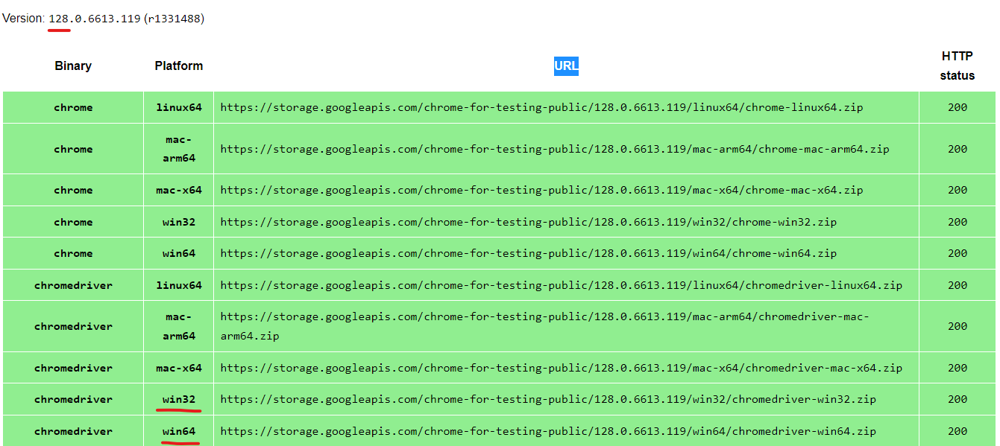

Descompacte o arquivo .zip e cole na pasta do anaconda3.a:.


#### Passo 3: Abrir o Chromedriver

In [3]:
driver = webdriver.Chrome() # Se uma nova janela do Chrome foi aberta, quer dizer que o selenium e o chromedriver estão funcionando corretamente.

#### Passo 4 (opicional): Atualizar webdriver automaticamente

In [4]:
# from selenium import webdriver
# from selenium.webdriver.chrome.service import Service

# # Informar o o diretório onde deve ser inserido o webdriver atualizado 
# driver = webdriver.Chrome(service=Service(r'C:\seu_caminho\chromedriver.exe'))

#### Passo 5 (opicional): Alternativa para atualizar webdriver automaticamente

In [5]:
# Remova o comentário(#) da linha abaixo caso esteja executando este script pela primeira vez
# %pip install webdriver-manager

In [6]:
# from selenium import webdriver
# from selenium.webdriver.chrome.service import Service
# from webdriver_manager.chrome import ChromeDriverManager

# driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))

In [7]:
driver = webdriver.Chrome()
driver.get("https://www.sp.senai.br/")

In [8]:
driver.quit

<bound method LocalWebDriver.quit of <selenium.webdriver.chrome.webdriver.WebDriver (session="5035de1fd61ba02f3ed01577cccfd10d")>>

## 5 Consumo De Apis Parte1

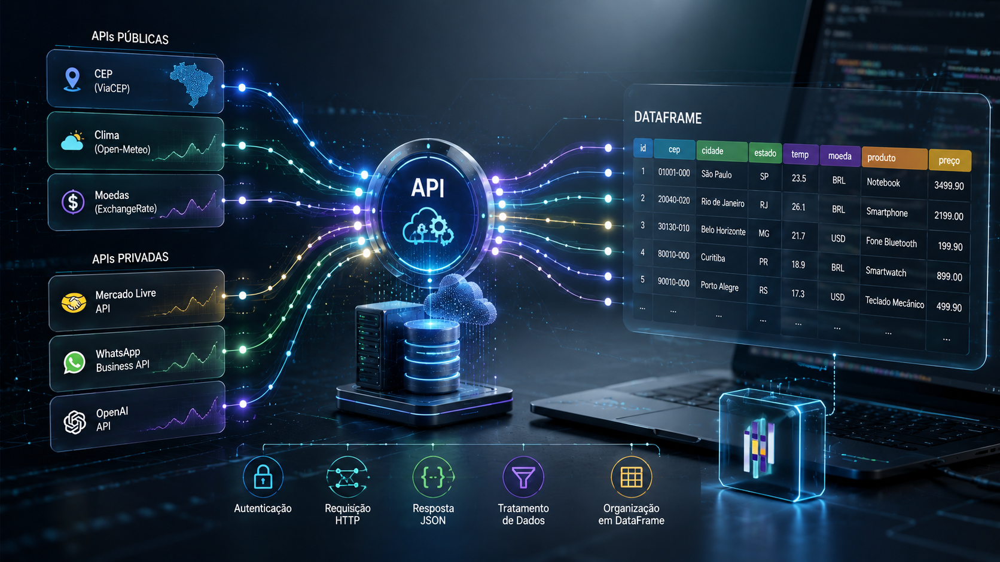

## Consumo de APIs: Obtenção de dados externos e organização em DataFrames

Nesta aula, estudaremos como aplicações em Python podem obter dados de serviços externos por meio de **APIs (Application Programming Interfaces)** e transformar as respostas recebidas em estruturas tabulares com `pandas`.

O foco da aula é o fluxo:

$$
\colorbox{#F1F5F9}{\text{documentação}}\;\longrightarrow\;
\colorbox{#E2E8F0}{\text{requisição HTTP}}\;\longrightarrow\;
\colorbox{#CBD5E1}{\text{resposta}}\;\longrightarrow\;
\colorbox{#B6C3D1}{\text{JSON}}\;\longrightarrow\;
\colorbox{#94A3B8}{\text{seleção de campos}}\;\longrightarrow\;
\colorbox{#718096}{\text{DataFrame}}\;\longrightarrow\;
\colorbox{#526477}{\color{white}{\text{validação}}}
$$

Serão utilizados seis exemplos:

| Tipo de acesso | API | Aplicação |
|---|---|---|
| Sem autenticação | ViaCEP | Consulta de endereços por CEP |
| Sem autenticação | IBGE | Consulta de estados e municípios |
| Sem autenticação | Open-Meteo | Dados meteorológicos |
| Com autenticação | Mercado Livre | OAuth 2.0 e recursos da conta |
| Com autenticação | GitHub | Token de acesso e dados do usuário |
| Com autenticação | OpenWeather | API Key e dados meteorológicos |

**Objetivo principal:** obter dados externos por meio de APIs e organizá-los em `DataFrame` para posterior análise, armazenamento ou integração com outros sistemas.

**Objetivos específicos**


1. explicar o que é uma API e identificar seus principais componentes;
2. interpretar a documentação de uma API REST;
3. diferenciar endpoint, método HTTP, parâmetro, header, payload e resposta;
4. realizar requisições HTTP em Python com a biblioteca `requests`;
5. verificar códigos de status e tratar erros básicos;
6. interpretar respostas em JSON;
7. transformar estruturas JSON em `DataFrame`;
8. consumir APIs sem autenticação;
9. utilizar credenciais em APIs que exigem autenticação;
10. compreender o fluxo OAuth 2.0 utilizado pelo Mercado Livre;
11. evitar a exposição de tokens, chaves e segredos no notebook.

# 1. O que é uma API?

Uma **API**, ou *Application Programming Interface*, define uma interface pela qual dois sistemas de software podem trocar dados ou solicitar operações.

Em uma aplicação web tradicional, uma pessoa utiliza uma interface gráfica. No consumo de uma API, um programa envia uma **requisição** diretamente a outro sistema.

Podemos representar o processo de forma simplificada:


$$\colorbox{#DCEEFF}{\text{Cliente}}\;\longrightarrow\;\colorbox{#FFF0CC}{\text{Requisição HTTP}}\;\longrightarrow\;\colorbox{#DDF4E4}{\text{API}}$$

$$\colorbox{#DCEEFF}{\text{Cliente}}\;\longleftarrow\;\colorbox{#EADFFF}{\text{Resposta HTTP}}\;\longleftarrow\;\colorbox{#DDF4E4}{\text{API}}$$

Nesta aula, o cliente será um programa Python executado no Jupyter Notebook.

## 2 Tipos de APIs

As APIs podem ser classificadas de diferentes formas, dependendo de sua arquitetura, protocolo de comunicação e finalidade. Entre os principais tipos encontrados em sistemas computacionais estão **SOAP, RPC, GraphQL e REST**.

### SOAP

**SOAP (*Simple Object Access Protocol*)** é um protocolo de comunicação baseado em mensagens estruturadas, normalmente utilizando **XML**.

Possui regras mais rígidas para a definição e troca de mensagens, sendo comum em sistemas corporativos que exigem contratos bem definidos, padronização e mecanismos formais de segurança.

**Aplicação:** integração entre sistemas bancários, sistemas governamentais e plataformas empresariais.

$$
\colorbox{#F3DDE3}{\text{Sistema A}}\;\longrightarrow\;\colorbox{#DDE5ED}{\text{mensagem XML}}\;
\longrightarrow\;\colorbox{#E8DFC9}{\text{serviço SOAP}}\;\longrightarrow\;
\colorbox{#DDE5ED}{\text{mensagem XML}}\;\longrightarrow\;
\colorbox{#F3DDE3}{\text{Sistema A}}
$$

### RPC

**RPC (*Remote Procedure Call*)**, ou **Chamada de Procedimento Remoto**, é um modelo de comunicação no qual um sistema **cliente solicita a execução de uma função ou procedimento localizado em um servidor remoto**.

A ideia central da RPC é permitir que uma operação executada em outro sistema seja solicitada de maneira semelhante a uma chamada de função.

Por exemplo, suponha que um servidor disponibilize uma função responsável pelo cálculo do valor de um frete:

```python
def calcular_frete(cep, peso):
    # processamento realizado no servidor
    return valor_frete
```

O cliente pode solicitar a execução dessa operação informando os parâmetros necessários:

```text
calcularFrete("01001000", 2.5)
```

Nesse processo, **a função não é executada no cliente**. O cliente apenas informa ao servidor qual operação deseja executar e quais valores devem ser utilizados como parâmetros.

O fluxo pode ser representado por:

$$
\colorbox{#E6E0F0}{\text{Cliente}}
\;\xrightarrow{\text{função + parâmetros}}\;
\colorbox{#DDEBE3}{\text{Servidor}}
\;\xrightarrow{\text{executa a função}}\;
\colorbox{#F2E3CF}{\text{Resultado}}
\;\longrightarrow\;
\colorbox{#E6E0F0}{\text{Cliente}}
$$

**Aplicação:** RPC é utilizada na comunicação entre sistemas distribuídos e **microsserviços**, especialmente quando diferentes componentes de uma aplicação precisam solicitar operações uns aos outros. Uma tecnologia amplamente utilizada nesse contexto é o **gRPC**, que implementa o paradigma RPC para comunicação entre aplicações.


### GraphQL

**GraphQL** é uma linguagem de consulta para APIs e um ambiente de execução que permite ao **cliente especificar exatamente quais dados deseja receber do servidor**.

Uma das principais características do GraphQL é permitir que diferentes informações relacionadas sejam solicitadas em uma única consulta, selecionando apenas os campos necessários.

Considere, por exemplo, um sistema que armazena informações sobre usuários. Um usuário pode possuir diversos atributos, como:

```text
id
nome
email
telefone
data_nascimento
endereco
pedidos
```

Se uma aplicação precisar apenas do nome e do e-mail de um usuário, poderá realizar uma consulta GraphQL como:

```graphql
query {
    usuario(id: 123) {
        nome
        email
    }
}
```

O servidor processa a consulta e retorna somente os campos solicitados:

```json
{
    "data": {
        "usuario": {
            "nome": "Ana Silva",
            "email": "ana@email.com"
        }
    }
}
```

Portanto, no GraphQL, **o cliente possui maior controle sobre a estrutura dos dados retornados**.

Isso é particularmente útil quando os dados possuem relacionamentos. Por exemplo, podemos solicitar informações do usuário e de seus pedidos na mesma consulta:

```graphql
query {
    usuario(id: 123) {
        nome
        email
        pedidos {
            id
            valor
            data
        }
    }
}
```


**Aplicação:** GraphQL é utilizado em aplicações web e móveis que trabalham com dados relacionados e podem precisar de diferentes conjuntos de atributos em diferentes telas. Uma interface de perfil, por exemplo, pode solicitar apenas `nome` e `foto`, enquanto outra tela pode solicitar `nome`, `email`, `pedidos` e outras informações relacionadas.

Apesar dessa flexibilidade, **REST continua sendo uma das abordagens mais difundidas para construção e consumo de APIs Web**. Como as APIs utilizadas nos exemplos desta aula são predominantemente baseadas em requisições HTTP no estilo REST, aprofundaremos a seguir a organização de **recursos e endpoints em APIs REST**.


### REST

**REST (*Representational State Transfer*)** é um estilo arquitetural amplamente utilizado na construção de APIs Web.

Em uma API REST, os dados são normalmente organizados como **recursos**, identificados por URLs. As operações sobre esses recursos são realizadas utilizando os métodos do protocolo HTTP, como `GET`, `POST`, `PUT`, `PATCH` e `DELETE`.

Por exemplo, considere uma API que disponibiliza informações sobre clientes:

```text
https://api.exemplo.com/clientes
```

O recurso representado nesse endereço é:

```text
clientes
```

Uma consulta a um cliente específico poderia utilizar:

```text
GET https://api.exemplo.com/clientes/123
```

Nesse caso:

* `GET` indica a operação de consulta;
* `clientes` representa o recurso;
* `123` identifica o cliente solicitado.

As APIs REST são particularmente relevantes para esta aula porque grande parte das APIs disponíveis na Web utiliza HTTP para disponibilizar dados, frequentemente retornados no formato **JSON**.

Os exemplos que utilizaremos, como **ViaCEP, IBGE, Open-Meteo, Mercado Livre, GitHub e OpenWeather**, seguem esse tipo de interação baseada em requisições HTTP.

Antes de começarmos a consumir essas APIs em Python, precisamos compreender melhor como uma API REST organiza seus **recursos e endpoints**. Esse será o assunto da próxima seção.


## 2.1 API REST e recursos

Muitas APIs disponíveis na Web seguem princípios associados à arquitetura REST. Nessas APIs, os dados são organizados em **recursos**, acessados por URLs denominadas **endpoints**.

Exemplo conceitual:

```text
https://api.exemplo.com/clientes/123
```

Podemos separar esse endereço em:

- **base URL:** `https://api.exemplo.com`
- **recurso:** `/clientes`
- **identificador:** `/123`

A URL completa utilizada para acessar uma operação específica é denominada **endpoint**.

## 2.2 Métodos HTTP

O método HTTP informa a operação que desejamos realizar.

| Método | Uso frequente |
|---|---|
| `GET` | consultar dados |
| `POST` | criar dados ou enviar informações para processamento |
| `PUT` | substituir um recurso |
| `PATCH` | atualizar parcialmente um recurso |
| `DELETE` | remover um recurso |

O objetivo principal desta aula é **obter dados externos**. Por isso, a maior parte das requisições utilizará `GET`.

## 2.3 Parâmetros, headers e body

Uma requisição HTTP pode transportar informações de diferentes maneiras. A posição de cada informação depende da finalidade do dado e das regras definidas pela API.

Considere uma API fictícia de uma loja virtual disponível em:

```text
https://api.loja.com
```

A partir desse exemplo, podemos identificar os principais componentes de uma requisição.

### Parâmetros de rota

Os **parâmetros de rota** fazem parte do próprio endpoint e normalmente são utilizados para identificar um recurso específico.

Por exemplo:

```text
GET https://api.loja.com/usuarios/123
```

Nesse caso:

* `/usuarios` representa o recurso que queremos consultar;
* `123` é um parâmetro de rota que identifica um usuário específico.

Assim, diferentes valores permitem acessar diferentes recursos:

```text
GET https://api.loja.com/usuarios/123
GET https://api.loja.com/usuarios/456
```

### Query parameters

Os **query parameters**, ou parâmetros de consulta, são utilizados para enviar informações adicionais ao servidor, frequentemente relacionadas a filtros, ordenação, paginação ou configuração da resposta.

Eles aparecem após o caractere `?` na URL:

```text
GET https://api.loja.com/produtos?categoria=notebooks&limite=10
```

Nesse exemplo, temos dois parâmetros:

```text
categoria = notebooks
limite = 10
```

O caractere `&` separa os diferentes parâmetros.

A requisição pode ser interpretada como:

> Consulte os produtos da categoria `notebooks` e retorne no máximo `10` registros.

Em Python, utilizando `requests`, não precisamos construir manualmente a query string. Podemos utilizar um dicionário:

```python
parametros = {
    "categoria": "notebooks",
    "limite": 10
}

resposta = requests.get(
    "https://api.loja.com/produtos",
    params=parametros
)
```

A biblioteca constrói a URL correspondente automaticamente.

### Headers

Os **headers** transportam metadados associados à requisição.

Eles não fazem parte diretamente dos dados que estamos consultando ou enviando. Em vez disso, fornecem informações adicionais sobre a comunicação entre cliente e servidor.

Um uso frequente é o envio de credenciais de autenticação:

```text
Authorization: Bearer TOKEN
```

Por exemplo:

```python
headers = {
    "Authorization": "Bearer TOKEN"
}

resposta = requests.get(
    "https://api.loja.com/usuarios/123",
    headers=headers
)
```

Nesse caso, o token permite que o servidor identifique ou autorize o cliente antes de fornecer o recurso solicitado.

Headers também podem informar o formato dos dados enviados ou esperados, como:

```text
Content-Type: application/json
Accept: application/json
```

### Body

O **body** corresponde ao corpo da requisição e permite enviar dados ao servidor.

É particularmente comum em operações como `POST`, `PUT` e `PATCH`.

Considere, por exemplo, o cadastro de um novo usuário:

```text
POST https://api.loja.com/usuarios
```

Os dados do usuário poderiam ser enviados no body em formato JSON:

```json
{
    "nome": "Ana Silva",
    "email": "ana@email.com",
    "cidade": "São Paulo"
}
```

Em Python:

```python
novo_usuario = {
    "nome": "Ana Silva",
    "email": "ana@email.com",
    "cidade": "São Paulo"
}

resposta = requests.post(
    "https://api.loja.com/usuarios",
    json=novo_usuario
)
```

Nesse caso, os dados contidos em `novo_usuario` são enviados no **body da requisição**.


A **documentação da API** determina quais métodos, parâmetros, headers e dados no body são aceitos ou obrigatórios em cada endpoint.


## 2.4 Códigos de status HTTP

Toda resposta HTTP possui um código de status.

| Faixa | Interpretação geral | Exemplos |
|---|---|---|
| `2xx` | requisição processada | `200 OK`, `201 Created` |
| `3xx` | redirecionamento | `301`, `302` |
| `4xx` | problema associado à requisição | `400`, `401`, `403`, `404`, `429` |
| `5xx` | erro no servidor | `500`, `502`, `503` |

Alguns códigos particularmente importantes no consumo de APIs são:

- `200`: requisição concluída;
- `400`: requisição inválida;
- `401`: autenticação ausente ou inválida;
- `403`: acesso não permitido;
- `404`: recurso não encontrado;
- `429`: limite de requisições excedido.

Não devemos transformar uma resposta em dados analíticos sem verificar se a requisição foi processada corretamente.

## 2.5 JSON

O formato **JSON (JavaScript Object Notation)** é amplamente utilizado por APIs.

Exemplo:

```json
{
    "nome": "Ana",
    "idade": 28,
    "cidade": "São Paulo"
}
```

Ao executar:

```python
dados = resposta.json()
```

a biblioteca `requests` converte o JSON para estruturas Python, normalmente dicionários e listas.

O `pandas` pode então organizar essas estruturas em tabelas.

# 3. Preparação do ambiente

Utilizaremos:

- `requests`: envio de requisições HTTP;
- `pandas`: organização e análise tabular;
- `os`: leitura de variáveis de ambiente;
- `getpass`: entrada temporária de credenciais sem exibi-las na célula;
- `urllib.parse`: apoio à construção de URLs.

In [1]:
import os
from getpass import getpass
from urllib.parse import urlencode

import pandas as pd
import requests

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 50)

## 3.1 Uma função auxiliar para requisições GET

Método básico para fazer uma requisição

```python
resposta = requests.get(url,params,headers,timeout)
```

Praa facilitar as próximas etapas, vamos criar uma função para:

1. enviar a requisição;
2. definir um tempo máximo de espera;
3. verificar o código de status;
4. gerar uma exceção quando a resposta HTTP indicar erro.

O parâmetro `timeout` evita que o notebook aguarde indefinidamente por um servidor que não responde.

In [2]:
def requisicao_get(url, params=None, headers=None, timeout=20):
    resposta = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=timeout
    )

    print("Status HTTP:", resposta.status_code)
    resposta.raise_for_status()

    return resposta

# 4. Como ler a documentação de uma API

Antes de escrever código, localize na documentação pelo menos os seguintes elementos:

| Elemento | Pergunta |
|---|---|
| Base URL | Qual é o domínio da API? |
| Endpoint | Qual recurso será consultado? |
| Método | A operação utiliza `GET`, `POST` ou outro método? |
| Autenticação | É necessário token, API Key ou OAuth? |
| Parâmetros | Quais dados são obrigatórios e opcionais? |
| Headers | Algum cabeçalho deve ser enviado? |
| Body | A operação exige corpo da requisição? |
| Resposta | Qual é a estrutura do JSON retornado? |
| Erros | Quais códigos de status precisam ser tratados? |
| Limites | Existe *rate limit*? |
| Paginação | Como obter resultados além da primeira página? |

Essa leitura deve preceder a implementação. Copiar apenas uma URL de exemplo não é suficiente para compreender a integração.

# 5. APIs sem autenticação

Nesta primeira parte, utilizaremos serviços que permitem executar os exemplos propostos sem criar credenciais.

A ausência de autenticação não significa ausência de regras. Uma API pode impor limites, bloquear uso massivo ou alterar sua política de acesso.

Os três exemplos serão:

1. ViaCEP;
2. IBGE;
3. Open-Meteo.

# 6. Exemplo 1: ViaCEP

O ViaCEP disponibiliza consultas de CEPs brasileiros. A documentação informa que a consulta por CEP utiliza oito dígitos e pode retornar JSON ou XML.

Documentação oficial: https://viacep.com.br/

Estrutura do endpoint JSON:

```text
https://viacep.com.br/ws/{CEP}/json/
```

Utilizaremos o CEP `01001000`, correspondente à região da Praça da Sé, em São Paulo.

In [3]:
cep = "04757000"
url_viacep = f"https://viacep.com.br/ws/{cep}/json/"

resposta = requisicao_get(url_viacep)
dados_cep = resposta.json()
dados_cep 

Status HTTP: 200


{'cep': '04757-000',
 'logradouro': 'Rua Bento Branco de Andrade Filho',
 'complemento': '',
 'unidade': '',
 'bairro': 'Jardim Dom Bosco',
 'localidade': 'São Paulo',
 'uf': 'SP',
 'estado': 'São Paulo',
 'regiao': 'Sudeste',
 'ibge': '3550308',
 'gia': '1004',
 'ddd': '11',
 'siafi': '7107'}

## 6.1 Do JSON para o DataFrame

A resposta representa um único endereço e, portanto, é convertida para um dicionário Python.

Para criar um `DataFrame` com uma linha, colocamos esse dicionário dentro de uma lista.

In [4]:
df_cep = pd.DataFrame([dados_cep])
df_cep

,cep,logradouro,complemento,unidade,bairro,localidade,...,estado,regiao,ibge,gia,ddd,siafi
0,04757-000,Rua Bento Branco de Andrade Filho,,,Jardim Dom Bosco,São Paulo,...,São Paulo,Sudeste,3550308,1004,11,7107


Observe a correspondência:

- cada **chave** do JSON torna-se uma coluna;
- cada **valor** torna-se o conteúdo da célula;
- o endereço consultado torna-se uma linha do `DataFrame`.

Esse padrão é recorrente no consumo de APIs.

## 6.2 Consultando vários CEPs

Uma situação mais próxima de um processo de dados consiste em consultar diversos CEPs e consolidar as respostas.

A função a seguir também verifica o campo `erro`, utilizado pelo ViaCEP quando um CEP possui formato válido, mas não é encontrado.

In [5]:
def consultar_cep(cep):
    cep_limpo = str(cep).replace("-", "").strip()

    if not (cep_limpo.isdigit() and len(cep_limpo) == 8):
        return {
            "cep_consultado": cep,
            "erro_consulta": "Formato inválido"
        }

    url = f"https://viacep.com.br/ws/{cep_limpo}/json/"

    try:
        resposta = requests.get(url, timeout=20)
        resposta.raise_for_status()
        dados = resposta.json()

        if dados.get("erro"):
            return {
                "cep_consultado": cep_limpo,
                "erro_consulta": "CEP não encontrado"
            }

        dados["cep_consultado"] = cep_limpo
        dados["erro_consulta"] = None
        return dados

    except requests.RequestException as erro:
        return {
            "cep_consultado": cep_limpo,
            "erro_consulta": str(erro)
        }

In [6]:
ceps = [
    "01001000",
    "20040002",
    "30140071",
    "99999999"
]

enderecos = [consultar_cep(cep) for cep in ceps]

df_ceps = pd.DataFrame(enderecos)

colunas_endereco = [
    "cep_consultado",
    "cep",
    "logradouro",
    "bairro",
    "localidade",
    "uf",
    "regiao",
    "ddd",
    "erro_consulta"
]

df_ceps = df_ceps.reindex(columns=colunas_endereco)
df_ceps

,cep_consultado,cep,logradouro,bairro,localidade,uf,regiao,ddd,erro_consulta
0,01001000,01001-000,Praça da Sé,Sé,São Paulo,SP,Sudeste,11,NaN
1,20040002,20040-002,Avenida Rio Branco,Centro,Rio de Janeiro,RJ,Sudeste,21,NaN
2,30140071,30140-071,Rua dos Aimorés,Boa Viagem,Belo Horizonte,MG,Sudeste,31,NaN
3,99999999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CEP não encontrado


## 6.3 O que aprendemos com o ViaCEP?

O exemplo introduziu o fluxo essencial:


$$
\colorbox{#F0F5FA}{\text{endpoint}}
\;\longrightarrow\;
\colorbox{#DDEAF4}{\text{GET}}
\;\longrightarrow\;
\colorbox{#C5DCEC}{\text{status}}
\;\longrightarrow\;
\colorbox{#A9CBDF}{\text{JSON}}
\;\longrightarrow\;
\colorbox{#86B5D0}{\text{dicionário}}
\;\longrightarrow\;
\colorbox{#639DBE}{\text{DataFrame}}
$$

Também introduziu uma prática importante: uma base resultante de uma API deve preservar informações sobre consultas que falharam. Excluir silenciosamente esses casos pode produzir uma base aparentemente completa, embora existam registros não obtidos.

# 7. Exemplo 2: API de Localidades do IBGE

Agora consultaremos dados hierárquicos de unidades territoriais.

A API de Localidades do IBGE permite consultar estados, municípios e outras divisões territoriais.

Endpoint utilizado:

```text
https://servicodados.ibge.gov.br/api/v1/localidades/estados/SP/municipios
```

Nesse caso:

- `SP` identifica a unidade federativa;
- `/municipios` especifica o recurso solicitado;
- a resposta contém uma **lista de objetos JSON**.

In [7]:
url_ibge = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/SP/municipios"

resposta_ibge = requisicao_get(url_ibge)
municipios_sp = resposta_ibge.json()

print(f"Total de estados: {len(municipios_sp)}")   
municipios_sp

Status HTTP: 200
Total de estados: 645


[{'id': 3500105,
  'nome': 'Adamantina',
  'microrregiao': {'id': 35035,
   'nome': 'Adamantina',
   'mesorregiao': {'id': 3508,
    'nome': 'Presidente Prudente',
    'UF': {'id': 35,
     'sigla': 'SP',
     'nome': 'São Paulo',
     'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}},
  'regiao-imediata': {'id': 350019,
   'nome': 'Adamantina - Lucélia',
   'regiao-intermediaria': {'id': 3505,
    'nome': 'Presidente Prudente',
    'UF': {'id': 35,
     'sigla': 'SP',
     'nome': 'São Paulo',
     'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}}},
 {'id': 3500204,
  'nome': 'Adolfo',
  'microrregiao': {'id': 35004,
   'nome': 'São José do Rio Preto',
   'mesorregiao': {'id': 3501,
    'nome': 'São José do Rio Preto',
    'UF': {'id': 35,
     'sigla': 'SP',
     'nome': 'São Paulo',
     'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}},
  'regiao-imediata': {'id': 350025,
   'nome': 'São José do Rio Preto',
   'regiao-intermediaria': {'id': 3507,
    'nome': 'S

## 7.1 JSON aninhado

Observe que alguns campos contêm outros objetos. Isso é denominado **estrutura aninhada**.

Quando queremos transformar estruturas aninhadas em formato tabular, `pd.json_normalize()` é particularmente útil.

In [8]:
df_municipios = pd.json_normalize(municipios_sp)

print("Dimensão:", df_municipios.shape)
df_municipios.head()

Dimensão: (645, 22)


,id,nome,microrregiao.id,microrregiao.nome,microrregiao.mesorregiao.id,microrregiao.mesorregiao.nome,...,regiao-imediata.regiao-intermediaria.UF.id,regiao-imediata.regiao-intermediaria.UF.sigla,regiao-imediata.regiao-intermediaria.UF.nome,regiao-imediata.regiao-intermediaria.UF.regiao.id,regiao-imediata.regiao-intermediaria.UF.regiao.sigla,regiao-imediata.regiao-intermediaria.UF.regiao.nome
0,3500105,Adamantina,35035,Adamantina,3508,Presidente Prudente,...,35,SP,São Paulo,3,SE,Sudeste
1,3500204,Adolfo,35004,São José do Rio Preto,3501,São José do Rio Preto,...,35,SP,São Paulo,3,SE,Sudeste
2,3500303,Aguaí,35029,Pirassununga,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste
3,3500402,Águas da Prata,35030,São João da Boa Vista,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste
4,3500501,Águas de Lindóia,35033,Amparo,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste


## 7.2 Seleção e renomeação de campos

Nem todos os campos retornados pela API precisam permanecer no conjunto analítico.

Selecionaremos apenas alguns atributos e atribuiremos nomes mais adequados ao contexto da análise.

In [9]:
colunas_ibge = {
    "id": "id_municipio",
    "nome": "municipio",
    "microrregiao.mesorregiao.UF.sigla": "uf",
    "microrregiao.mesorregiao.UF.nome": "estado"
}
df_municipios_resumo = (
    df_municipios[list(colunas_ibge)].rename(columns=colunas_ibge).sort_values("municipio").reset_index(drop=True)
)
df_municipios_resumo.head(10)

,id_municipio,municipio,uf,estado
0,3500105,Adamantina,SP,São Paulo
1,3500204,Adolfo,SP,São Paulo
2,3500303,Aguaí,SP,São Paulo
3,3500709,Agudos,SP,São Paulo
4,3500758,Alambari,SP,São Paulo
5,3500808,Alfredo Marcondes,SP,São Paulo
6,3500907,Altair,SP,São Paulo
7,3501004,Altinópolis,SP,São Paulo
8,3501103,Alto Alegre,SP,São Paulo
9,3501152,Alumínio,SP,São Paulo


Esse passo evidencia uma diferença importante entre **dados recebidos** e **dados analíticos**.

A resposta da API é estruturada de acordo com o contrato do serviço. O `DataFrame` deve ser organizado de acordo com o problema que será analisado.

# 8. Exemplo 3: Open-Meteo

O Open-Meteo disponibiliza dados meteorológicos e, para uso não comercial padrão, permite consultas sem API Key.

Documentação oficial: https://open-meteo.com/en/docs

O endpoint de previsão recebe coordenadas geográficas e as variáveis desejadas.

Consultaremos dados horários para São Paulo, aproximadamente:

- latitude: `-23.55`;
- longitude: `-46.63`.

In [10]:
url_open_meteo = "https://api.open-meteo.com/v1/forecast"

parametros_meteo = {
    "latitude": -23.55,
    "longitude": -46.63,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "forecast_days": 2,
    "timezone": "America/Sao_Paulo"
}

resposta_meteo = requisicao_get(
    url_open_meteo,
    params=parametros_meteo
)

dados_meteo = resposta_meteo.json()

dados_meteo.keys()

Status HTTP: 200


dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

## 8.1 Identificando o nível correto do JSON

Nem sempre devemos transformar o JSON inteiro diretamente em um `DataFrame`.

A resposta do Open-Meteo contém:

- metadados da consulta;
- unidades;
- coordenadas;
- uma estrutura `hourly` com as observações horárias.

Para uma análise temporal, o objeto de interesse é `hourly`.

In [11]:
dados_horarios = dados_meteo["hourly"]

df_tempo = pd.DataFrame(dados_horarios)
df_tempo["time"] = pd.to_datetime(df_tempo["time"])
df_tempo.head(10)

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-09-14 00:00:00,13.9,97,1.7
1,2026-09-14 01:00:00,13.9,98,2.0
2,2026-09-14 02:00:00,13.8,98,1.9
3,2026-09-14 03:00:00,13.8,98,2.0
4,2026-09-14 04:00:00,13.8,98,1.3
5,2026-09-14 05:00:00,13.8,98,1.9
6,2026-09-14 06:00:00,13.7,98,1.2
7,2026-09-14 07:00:00,14.0,98,0.3
8,2026-09-14 08:00:00,14.7,93,0.1
9,2026-09-14 09:00:00,14.8,87,0.0


## 8.2 Inspeção do DataFrame

Após importar dados de uma API, devemos verificar pelo menos:

- dimensão;
- nomes das colunas;
- tipos;
- valores ausentes;
- primeiras observações.

In [12]:
print("Dimensão:", df_tempo.shape)
print("\nTipos:")
display(df_tempo.dtypes)

print("\nValores ausentes:")
display(df_tempo.isna().sum())

df_tempo.head()

Dimensão: (48, 4)

Tipos:


time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
dtype: object


Valores ausentes:


time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
dtype: int64

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-09-14 00:00:00,13.9,97,1.7
1,2026-09-14 01:00:00,13.9,98,2.0
2,2026-09-14 02:00:00,13.8,98,1.9
3,2026-09-14 03:00:00,13.8,98,2.0
4,2026-09-14 04:00:00,13.8,98,1.3


# 9. Comparação dos três primeiros exemplos

| API | Entrada principal | Estrutura relevante da resposta | Estratégia tabular |
|---|---|---|---|
| ViaCEP | CEP | objeto JSON | `DataFrame([dicionario])` |
| IBGE | UF/recurso | lista de objetos aninhados | `json_normalize()` |
| Open-Meteo | coordenadas e variáveis | objeto com série em `hourly` | selecionar nível e usar `DataFrame()` |

O principal aprendizado é que **não existe uma única forma de converter JSON em tabela**. Primeiro é necessário compreender a estrutura semântica da resposta.

# 9.1 Atividade prática: consumo de APIs públicas

Nesta atividade, aplicaremos os conceitos estudados até aqui utilizando as três APIs públicas apresentadas anteriormente:

* **ViaCEP**, para consulta de endereços;
* **IBGE**, para consulta de municípios;
* **Open-Meteo**, para obtenção de dados meteorológicos.

O objetivo é praticar o fluxo completo:

```text
requisição HTTP → resposta JSON → seleção dos dados → DataFrame → análise
```
$$
\colorbox{#F3F0F7}{\text{requisição HTTP}}
\;\longrightarrow\;
\colorbox{#E5DDEC}{\text{resposta JSON}}
\;\longrightarrow\;
\colorbox{#D4C5DF}{\text{seleção dos dados}}
\;\longrightarrow\;
\colorbox{#BFA9CF}{\text{DataFrame}}
\;\longrightarrow\;
\colorbox{#A58ABB}{\text{análise}}
$$

A atividade está organizada em três etapas.


## Parte 1: consulta de endereços com ViaCEP

Consulte os seguintes CEPs utilizando a API ViaCEP:

```text
01001000
20040002
30140071
40020000
80010000
```

Construa um único `DataFrame` contendo as seguintes informações:

* CEP;
* logradouro;
* bairro;
* cidade;
* UF;
* região;
* DDD.

Ao final:

1. exiba o `DataFrame`;
2. verifique sua dimensão;
3. identifique se existem valores ausentes;
4. verifique se existem registros duplicados.

In [24]:
ceps = [
    "01001000",
    "20040002",
    "30140071",
    "40020000",
    "80010000"
]

enderecos = [consultar_cep(cep) for cep in ceps]
df_cep_atividade = pd.DataFrame(enderecos)

df_cep_atividade = df_cep_atividade[
    [
        "cep_consultado",
        "logradouro",
        "bairro",
        "localidade",
        "uf",
        "regiao",
        "ddd"
    ]
].rename(
    columns={
        "cep_consultado": "CEP",
        "localidade": "cidade",
        "uf": "UF",
        "regiao": "regiao",
        "ddd": "DDD"
    }
)

df_cep_atividade = df_cep_atividade[["CEP", "logradouro", "bairro", "cidade", "UF", "regiao", "DDD"]]
df_cep_atividade

,CEP,logradouro,bairro,cidade,UF,regiao,DDD
0,01001000,Praça da Sé,Sé,São Paulo,SP,Sudeste,11
1,20040002,Avenida Rio Branco,Centro,Rio de Janeiro,RJ,Sudeste,21
2,30140071,Rua dos Aimorés,Boa Viagem,Belo Horizonte,MG,Sudeste,31
3,40020000,NaN,NaN,NaN,NaN,NaN,NaN
4,80010000,Rua José Loureiro,Centro,Curitiba,PR,Sul,41


In [25]:
print("Dimensão:", df_cep_atividade.shape)
print("\nValores ausentes:")
print(df_cep_atividade.isna().sum())
print("\nRegistros duplicados:", df_cep_atividade.duplicated().sum())

if df_cep_atividade.duplicated().sum() > 0:
    print("\nLinhas duplicadas:")
    display(df_cep_atividade[df_cep_atividade.duplicated(keep=False)])

# Exibe o DataFrame final
display(df_cep_atividade)

Dimensão: (5, 7)

Valores ausentes:
CEP           0
logradouro    1
bairro        1
cidade        1
UF            1
regiao        1
DDD           1
dtype: int64

Registros duplicados: 0


,CEP,logradouro,bairro,cidade,UF,regiao,DDD
0,01001000,Praça da Sé,Sé,São Paulo,SP,Sudeste,11
1,20040002,Avenida Rio Branco,Centro,Rio de Janeiro,RJ,Sudeste,21
2,30140071,Rua dos Aimorés,Boa Viagem,Belo Horizonte,MG,Sudeste,31
3,40020000,NaN,NaN,NaN,NaN,NaN,NaN
4,80010000,Rua José Loureiro,Centro,Curitiba,PR,Sul,41


## Parte 2: consulta de municípios com a API do IBGE

Utilize a API de Localidades do IBGE para consultar todos os municípios do estado de **Minas Gerais (`MG`)**.

Construa um `DataFrame` contendo apenas:

* código do município;
* nome do município;
* sigla da UF;
* nome do estado.

Depois:

1. informe quantos municípios foram retornados;
2. ordene os municípios alfabeticamente;
3. exiba os 10 primeiros registros.

Endpoint de referência:

```text
https://servicodados.ibge.gov.br/api/v1/localidades/estados/MG/municipios
```



In [15]:
# Implementação IBGE
url_ibge_mg = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/MG/municipios"

resposta_ibge_mg = requisicao_get(url_ibge_mg)
municipios_mg = resposta_ibge_mg.json()

print(f"Registros retornados: {len(municipios_mg)}")

Status HTTP: 200
Registros retornados: 853


In [16]:
# Normalização JSON
df_municipios_mg = pd.json_normalize(municipios_mg)

df_municipios_mg.head()

,id,nome,microrregiao.id,microrregiao.nome,microrregiao.mesorregiao.id,microrregiao.mesorregiao.nome,...,regiao-imediata.regiao-intermediaria.UF.id,regiao-imediata.regiao-intermediaria.UF.sigla,regiao-imediata.regiao-intermediaria.UF.nome,regiao-imediata.regiao-intermediaria.UF.regiao.id,regiao-imediata.regiao-intermediaria.UF.regiao.sigla,regiao-imediata.regiao-intermediaria.UF.regiao.nome
0,3100104,Abadia dos Dourados,31019,Patrocínio,3105,Triângulo Mineiro/Alto Paranaíba,...,31,MG,Minas Gerais,3,SE,Sudeste
1,3100203,Abaeté,31024,Três Marias,3106,Central Mineira,...,31,MG,Minas Gerais,3,SE,Sudeste
2,3100302,Abre Campo,31061,Manhuaçu,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste
3,3100401,Acaiaca,31060,Ponte Nova,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste
4,3100500,Açucena,31039,Ipatinga,3108,Vale do Rio Doce,...,31,MG,Minas Gerais,3,SE,Sudeste


In [17]:
# Selecao de colunas
colunas_ibge_mg = {
    "id": "id_municipio",
    "nome": "municipio",
    "microrregiao.mesorregiao.UF.sigla": "uf",
    "microrregiao.mesorregiao.UF.nome": "estado"
}

df_municipios_mg_resumo = (
    df_municipios_mg[list(colunas_ibge_mg)]
    .rename(columns=colunas_ibge_mg)
    .sort_values("municipio")
    .reset_index(drop=True)
)

df_municipios_mg_resumo.head(10)

,id_municipio,municipio,uf,estado
0,3100104,Abadia dos Dourados,MG,Minas Gerais
1,3100203,Abaeté,MG,Minas Gerais
2,3100302,Abre Campo,MG,Minas Gerais
3,3100401,Acaiaca,MG,Minas Gerais
4,3100807,Aguanil,MG,Minas Gerais
5,3101102,Aimorés,MG,Minas Gerais
6,3101201,Aiuruoca,MG,Minas Gerais
7,3101300,Alagoa,MG,Minas Gerais
8,3101409,Albertina,MG,Minas Gerais
9,3101607,Alfenas,MG,Minas Gerais


In [18]:
# Quantidade de municipios
print(f"Quantidade de municipios: {len(df_municipios_mg_resumo)}")
df_municipios_mg_resumo.head(10)

Quantidade de municipios: 853


,id_municipio,municipio,uf,estado
0,3100104,Abadia dos Dourados,MG,Minas Gerais
1,3100203,Abaeté,MG,Minas Gerais
2,3100302,Abre Campo,MG,Minas Gerais
3,3100401,Acaiaca,MG,Minas Gerais
4,3100807,Aguanil,MG,Minas Gerais
5,3101102,Aimorés,MG,Minas Gerais
6,3101201,Aiuruoca,MG,Minas Gerais
7,3101300,Alagoa,MG,Minas Gerais
8,3101409,Albertina,MG,Minas Gerais
9,3101607,Alfenas,MG,Minas Gerais


## Parte 3: dados meteorológicos com Open-Meteo

Utilize a API Open-Meteo para consultar a previsão meteorológica de **São Paulo** utilizando aproximadamente as coordenadas:

```text
Latitude:  -23.55
Longitude: -46.63
```

Solicite as seguintes variáveis horárias:

* temperatura a 2 metros;
* umidade relativa a 2 metros;
* precipitação.

Utilize:

```text
timezone = America/Sao_Paulo
forecast_days = 1
```

Construa um `DataFrame` contendo as observações horárias.

Depois:

1. converta a coluna de data e hora para `datetime`;
2. exiba as primeiras observações;
3. informe a temperatura mínima;
4. informe a temperatura máxima;
5. calcule a temperatura média do período;
6. identifique o horário em que ocorre a maior temperatura.

In [19]:
# Implementacao Open-Meteo
url_open_meteo_sp = "https://api.open-meteo.com/v1/forecast"

parametros_meteo_sp = {
    "latitude": -23.55,
    "longitude": -46.63,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "forecast_days": 1,
    "timezone": "America/Sao_Paulo"
}

resposta_meteo_sp = requisicao_get(
    url_open_meteo_sp,
    params=parametros_meteo_sp
)

dados_meteo_sp = resposta_meteo_sp.json()

Status HTTP: 200


In [20]:
# Inspecao da resposta
print("Chaves da resposta:", list(dados_meteo_sp.keys()))
print("Chaves de hourly:", list(dados_meteo_sp["hourly"].keys()))
print("Unidades:", dados_meteo_sp["hourly_units"])

Chaves da resposta: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Chaves de hourly: ['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation']
Unidades: {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'precipitation': 'mm'}


In [21]:
# Construcao do DataFrame
dados_horarios_sp = dados_meteo_sp["hourly"]

df_tempo_sp = pd.DataFrame(dados_horarios_sp)
df_tempo_sp["time"] = pd.to_datetime(df_tempo_sp["time"])

df_tempo_sp.head()

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-09-14 00:00:00,13.9,97,1.7
1,2026-09-14 01:00:00,13.9,98,2.0
2,2026-09-14 02:00:00,13.8,98,1.9
3,2026-09-14 03:00:00,13.8,98,2.0
4,2026-09-14 04:00:00,13.8,98,1.3


In [22]:
# Estatisticas da temperatura
temperatura = df_tempo_sp["temperature_2m"]

print(f"Temperatura minima: {temperatura.min():.2f} °C")
print(f"Temperatura maxima: {temperatura.max():.2f} °C")
print(f"Temperatura media: {temperatura.mean():.2f} °C")

Temperatura minima: 13.70 °C
Temperatura maxima: 17.20 °C
Temperatura media: 14.80 °C


In [23]:
# Horario da maior temperatura
indice_maior_temperatura = df_tempo_sp["temperature_2m"].idxmax()
horario_maior_temperatura = df_tempo_sp.loc[indice_maior_temperatura, "time"]

print("Horario da maior temperatura:", horario_maior_temperatura)
print("Maior temperatura:", df_tempo_sp.loc[indice_maior_temperatura, "temperature_2m"], "°C")

Horario da maior temperatura: 2026-09-14 12:00:00
Maior temperatura: 17.2 °C


## Questões para análise

Após executar as três consultas, responda:

1. Qual API retornou um único objeto JSON por consulta?
2. Qual API retornou diretamente uma lista de registros?
3. Em qual API foi necessário selecionar uma parte específica da resposta JSON antes de criar o `DataFrame`?
4. Por que `pd.json_normalize()` foi útil no exemplo do IBGE?
5. Qual é a importância de verificar `status_code` ou utilizar `raise_for_status()` antes de processar os dados?
6. Apesar de todas serem APIs públicas, a estrutura das respostas é igual? Justifique.


# Desafio Extra - Obter dados da API Pokemon

In [1]:
# começo do código
import pandas as pd
import requests

nome_pokemon = input("Digite o nome de um Pokémon para buscar todos do mesmo tipo: ").strip().lower()

if not nome_pokemon:
    nome_pokemon = "pikachu"

df_consulta = pd.DataFrame([{
    "pokemon_consultado": nome_pokemon.title()
}])
display(df_consulta)

,pokemon_consultado
0,Pikachu


In [2]:
url_pokemon = f"https://pokeapi.co/api/v2/pokemon/{nome_pokemon}"

try:
    resposta_pokemon = requests.get(url_pokemon, timeout=20)
    resposta_pokemon.raise_for_status()
    dados_pokemon = resposta_pokemon.json()

    tipos = [tipo["type"]["name"] for tipo in dados_pokemon["types"]]
    tipo_principal = tipos[0]

    url_tipo = f"https://pokeapi.co/api/v2/type/{tipo_principal}"
    resposta_tipo = requests.get(url_tipo, timeout=20)
    resposta_tipo.raise_for_status()
    dados_tipo = resposta_tipo.json()

    lista_pokemons = [item["pokemon"]["name"].title() for item in dados_tipo["pokemon"]]

    habilidades = [habilidade["ability"]["name"] for habilidade in dados_pokemon["abilities"]]
    estatisticas = {
        status["stat"]["name"]: status["base_stat"]
        for status in dados_pokemon["stats"]
    }

    df_caracteristicas = pd.DataFrame([{
        "nome": dados_pokemon["name"].title(),
        "id": dados_pokemon["id"],
        "tipo_principal": tipo_principal.title(),
        "tipos": ", ".join(tipo.title() for tipo in tipos),
        "altura": dados_pokemon["height"],
        "peso": dados_pokemon["weight"],
        "experiencia_base": dados_pokemon["base_experience"],
        "habilidades": ", ".join(habilidade.title() for habilidade in habilidades),
        "quantidade_de_movimentos": len(dados_pokemon["moves"]),
        "quantidade_de_caracteristicas": len(dados_pokemon.keys())
    }])

    df_pokemons_tipo = pd.DataFrame({
        "nome": lista_pokemons,
        "tipo": tipo_principal.title()
    }).sort_values("nome").reset_index(drop=True)

    df_status = pd.DataFrame([estatisticas])
    df_status.insert(0, "pokemon", dados_pokemon["name"].title())

    df_validacao = pd.DataFrame([{
        "dimensao_pokemons_do_tipo": str(df_pokemons_tipo.shape),
        "valores_ausentes": int(df_pokemons_tipo.isna().sum().sum()),
        "registros_duplicados": int(df_pokemons_tipo.duplicated().sum())
    }])

    display(df_caracteristicas)
    display(df_pokemons_tipo.head(20))
    display(df_status)
    display(df_validacao)

except requests.exceptions.HTTPError:
    df_erro = pd.DataFrame([{
        "pokemon_consultado": nome_pokemon,
        "erro": "Pokémon não encontrado na API do Pokémon"
    }])
    display(df_erro)
except requests.exceptions.RequestException as erro:
    df_erro = pd.DataFrame([{
        "pokemon_consultado": nome_pokemon,
        "erro": str(erro)
    }])
    display(df_erro)

,nome,id,tipo_principal,tipos,altura,peso,experiencia_base,habilidades,quantidade_de_movimentos,quantidade_de_caracteristicas
0,Pikachu,25,Electric,Electric,4,60,112,"Static, Lightning-Rod",109,21


,nome,tipo
0,Ampharos,Electric
1,Ampharos-Mega,Electric
2,Arctozolt,Electric
3,Bellibolt,Electric
4,Blitzle,Electric
5,Boltund,Electric
6,Charjabug,Electric
7,Chinchou,Electric
8,Dedenne,Electric
9,Dracozolt,Electric


,pokemon,hp,attack,defense,special-attack,special-defense,speed
0,Pikachu,35,55,40,50,50,90


,dimensao_pokemons_do_tipo,valores_ausentes,registros_duplicados
0,"(114, 2)",0,0


## 5 Consumo De Api Parte2

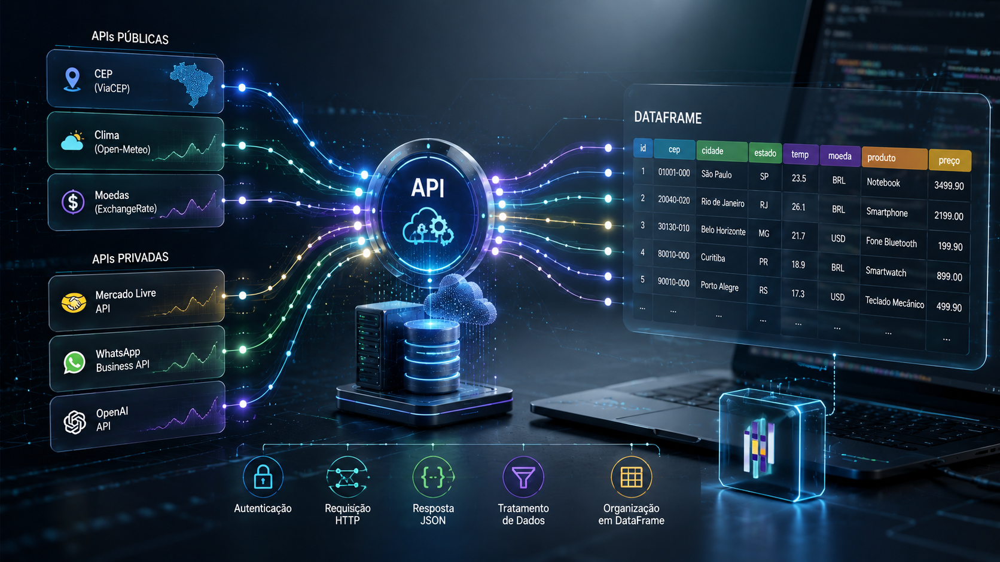

In [4]:
import os
from getpass import getpass
from urllib.parse import urlencode

import pandas as pd
import requests

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 50)

## 1. Uma função auxiliar para requisições GET

Método básico para fazer uma requisição

```python
resposta = requests.get(url,params,headers,timeout)
```

Praa facilitar as próximas etapas, vamos criar uma função para:

1. enviar a requisição;
2. definir um tempo máximo de espera;
3. verificar o código de status;
4. gerar uma exceção quando a resposta HTTP indicar erro.

O parâmetro `timeout` evita que o notebook aguarde indefinidamente por um servidor que não responde.

In [5]:
def requisicao_get(url, params=None, headers=None, timeout=20):
    resposta = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=timeout
    )

    print("Status HTTP:", resposta.status_code)
    resposta.raise_for_status()

    return resposta

# 2. APIs com autenticação

Agora estudaremos serviços que exigem uma credencial para os exemplos propostos.

Nesta aula, a expressão **API com autenticação** será usada para indicar uma integração em que a requisição depende de uma credencial, como:

- API Key;
- access token;
- OAuth 2.0.

Isso não significa que todos os dados fornecidos pelo serviço sejam necessariamente privados. O ponto central é que o servidor precisa identificar ou autorizar o cliente antes de processar a operação utilizada no exemplo.

## 2.1. Nunca escreva segredos diretamente no notebook

Evite:

```python
TOKEN = "meu_token_real"
```

Um notebook pode ser:

- enviado a outra pessoa;
- publicado no GitHub;
- armazenado em nuvem;
- incluído em backups;
- exibido durante uma aula.

Nesta aula, utilizaremos `getpass()` para digitação temporária. Em projetos reais, prefira mecanismos apropriados de gerenciamento de segredos ou variáveis de ambiente.

# 3. API do Mercado Livre: configuração, OAuth e busca de produtos

Nesta seção, a configuração será feita **na mesma ordem em que o código será construído**. A finalidade é reduzir erros de autenticação e tornar o procedimento reproduzível em sala de aula.

Ao final, faremos uma busca por **Smart TV 70** no catálogo do Mercado Livre e transformaremos os produtos retornados em um `DataFrame`.

Documentação oficial consultada:

- criação da aplicação: https://developers.mercadolivre.com.br/pt_br/crie-uma-aplicacao-no-mercado-livre
- autenticação e autorização: https://developers.mercadolivre.com.br/autenticacao-e-autorizacao
- buscador de produtos: https://developers.mercadolivre.com.br/buscador-de-produtos

> A interface do DevCenter pode mudar. Os nomes exatos dos campos podem sofrer pequenas alterações, mas os conceitos de `Client ID`, `Client Secret`, `Redirect URI`, escopos e OAuth permanecem.


## 3.1. Acesso o DevCenter e clique em Criar nova aplicação

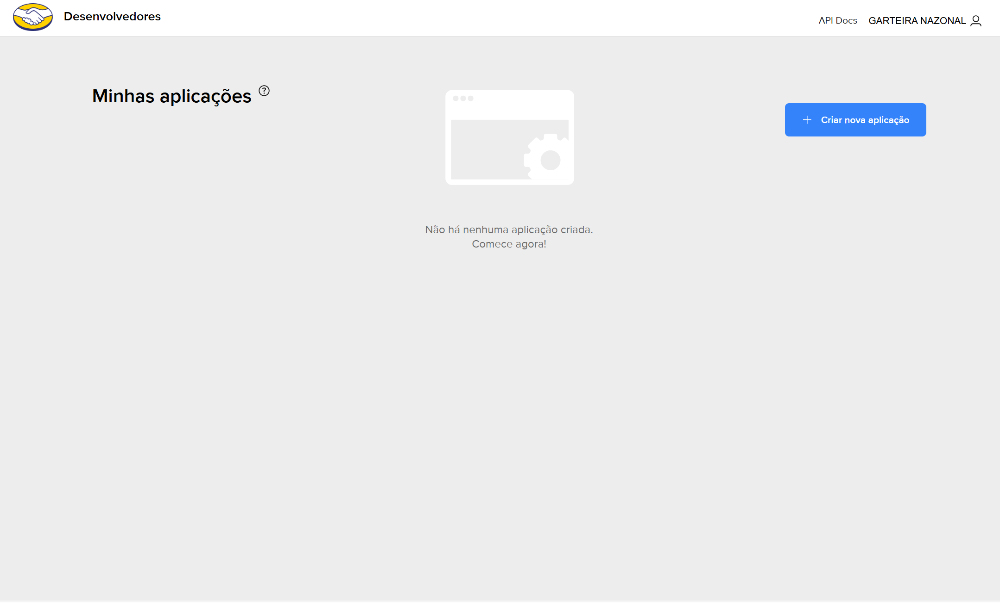

## 3.2. Preencha os dados e insira um logotipo qualquer.

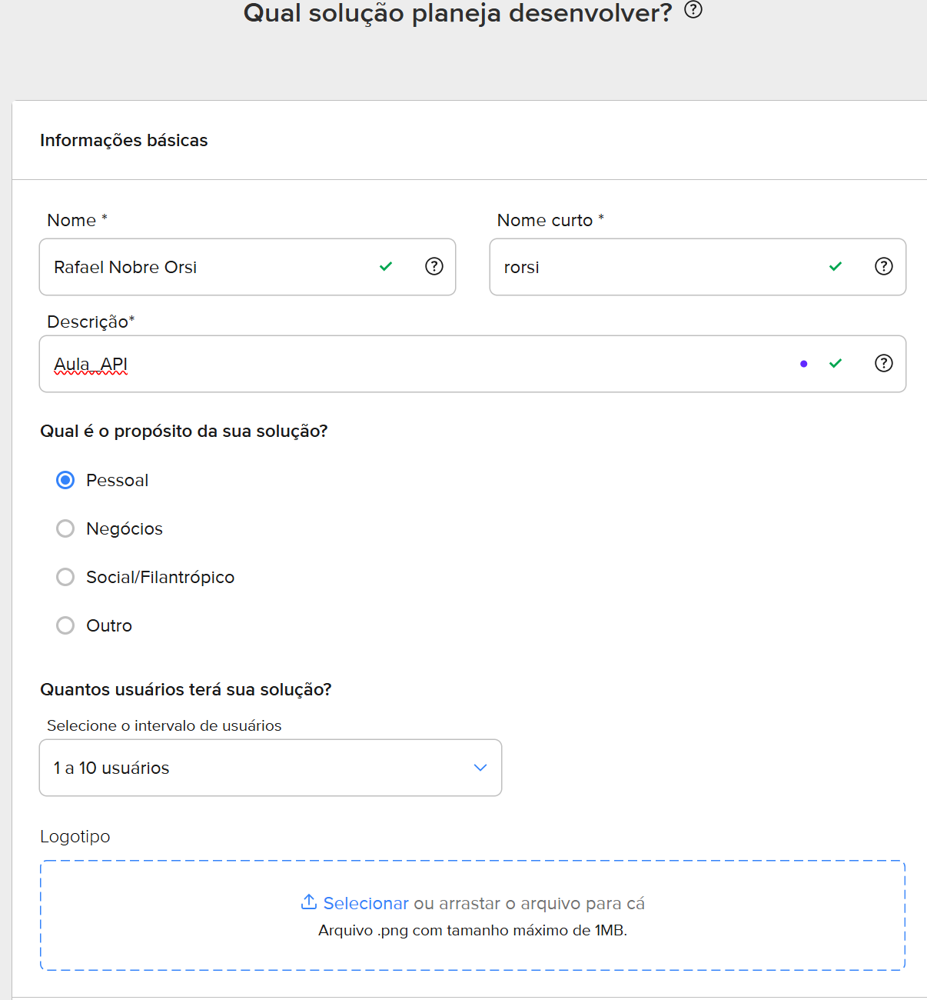

## 3.3. Adicione uma URI

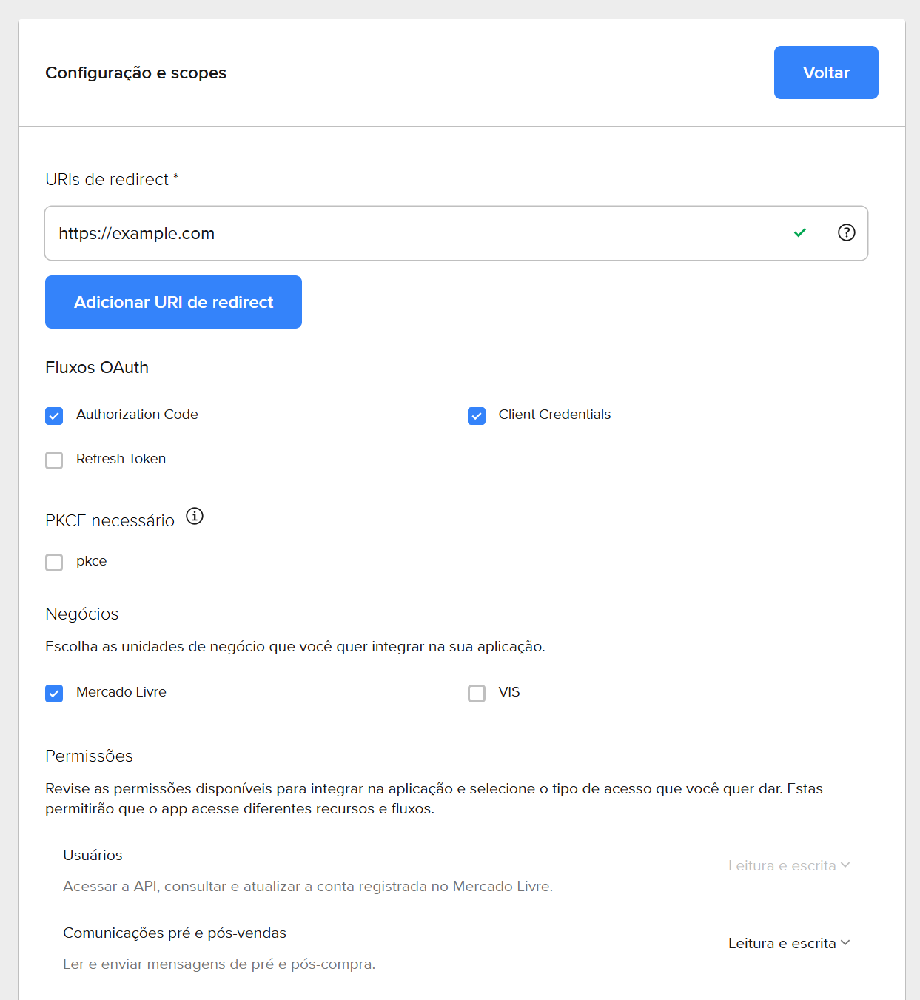

## 3.4. O que será configurado no DevCenter

Para esta aula, configure uma aplicação **somente para leitura**. Não precisamos publicar produtos, alterar anúncios ou receber notificações.

Preencha os campos da aplicação da seguinte forma:

| Campo no Mercado Livre | Configuração didática sugerida | Finalidade |
|---|---|---|
| **Nome** | `Aula API Mercado Livre` | Identificar a aplicação |
| **Nome curto** | um identificador simples e único | Identificação interna/URL da aplicação |
| **Descrição** | `Aplicação didática para consulta de produtos via API` | Texto apresentado no processo de autorização |
| **Logo** | opcional, conforme a interface permitir | Identificação visual |
| **Redirect URI** | `https://example.com` | Receber o retorno com o `code` |
| **PKCE** | desabilitado nesta primeira aula | Evita adicionar uma segunda camada ao fluxo didático |
| **Escopo Leitura** | habilitado | Necessário para chamadas `GET` |
| **Escopo Escrita** | desabilitado | Não será utilizado |
| **Tópicos/Notificações** | nenhum | Não precisamos receber eventos de Orders, Items, Catalog etc. |
| **URL de notificações** | não configurar | Só é necessária quando tópicos são selecionados |

### Por que usar `https://example.com`?

O Mercado Livre exige uma URI de redirecionamento com HTTPS. Para a aula, podemos utilizar uma URL de teste. Depois da autorização, observe a **barra de endereço do navegador**: o Mercado Livre acrescentará o parâmetro `code` à URL.

Exemplo conceitual:

```text
https://example.com/?code=TG-XXXXXXXXXXXX&state=YYYY
```

Mesmo que a página de destino não seja utilizada pela aplicação, o que nos interessa didaticamente é copiar o valor de `code` exibido na URL.

**Regra crítica:** use exatamente a mesma Redirect URI em três lugares:

1. cadastro da aplicação;
2. URL de autorização;
3. requisição que troca o `code` pelo token.

## 3.5. Resultado esperado
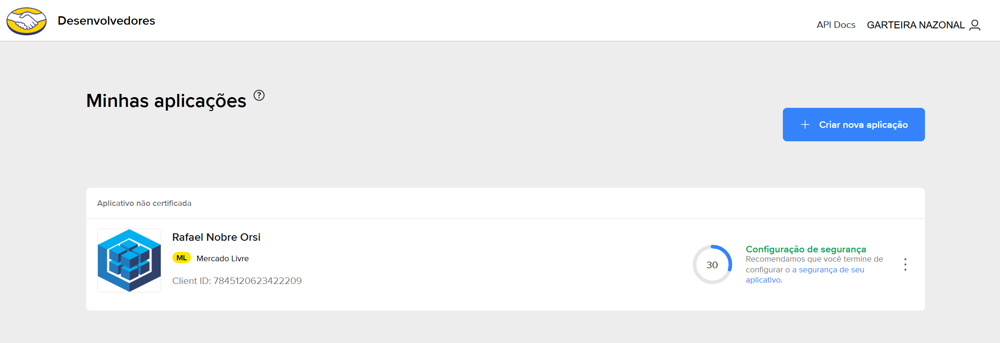

## 3.6. Depois de salvar a aplicação: identifique as credenciais

Após criar a aplicação, localize no DevCenter:

- **Client ID / APP ID**: identifica publicamente sua aplicação;
- **Client Secret / Secret Key**: segredo da aplicação;
- **Redirect URI**: endereço cadastrado anteriormente.

Nesta aula, o `Client Secret` nunca será escrito diretamente no notebook. Ele será solicitado por `getpass()`.

## 4. Construir o a URL de busca
## 4.1. registrar somente o Client ID e a Redirect URI

Começamos com os dois valores que **não são o token**. Nesta etapa ainda não faremos nenhuma requisição à API.


In [11]:
app_id_ml = input("APP ID / Client ID do Mercado Livre: ").strip()
redirect_uri_ml = input("Redirect URI cadastrada [https://example.com]: ").strip()

if not redirect_uri_ml: redirect_uri_ml = "https://example.com"

print("APP ID informado:", app_id_ml)
print("Redirect URI:", redirect_uri_ml)


APP ID informado: 1650467854542916
Redirect URI: https://example.com


## 4.2. Etapa 2: construir a URL de autorização

A URL de autorização é formada por um **endpoint fixo** e **parâmetros variáveis**.

Para o Brasil:

```text
https://auth.mercadolivre.com.br/authorization
```

Parâmetros utilizados:

- `response_type=code`: solicita um código de autorização;
- `client_id`: APP ID da aplicação;
- `redirect_uri`: deve coincidir exatamente com o cadastro;
- `state`: valor aleatório usado para associar a resposta à solicitação iniciada.

Em vez de montar a URL manualmente, utilizaremos `urlencode()`. Isso evita erros com caracteres especiais.


In [12]:
import secrets

state_ml = secrets.token_urlsafe(16)

parametros_autorizacao_ml = {
    "response_type": "code",
    "client_id": app_id_ml,
    "redirect_uri": redirect_uri_ml,
    "state": state_ml
}

url_autorizacao_ml = ("https://auth.mercadolivre.com.br/authorization?" + urlencode(parametros_autorizacao_ml))

print("Abra a URL abaixo no navegador:\n")
print(url_autorizacao_ml)
print("\nState gerado:", state_ml)


Abra a URL abaixo no navegador:

https://auth.mercadolivre.com.br/authorization?response_type=code&client_id=1650467854542916&redirect_uri=https%3A%2F%2Fexample.com&state=yCug_pLVDddha7aD6RD56A

State gerado: yCug_pLVDddha7aD6RD56A


## 4.3. Acesse o link gerado e a autorize a aplicação
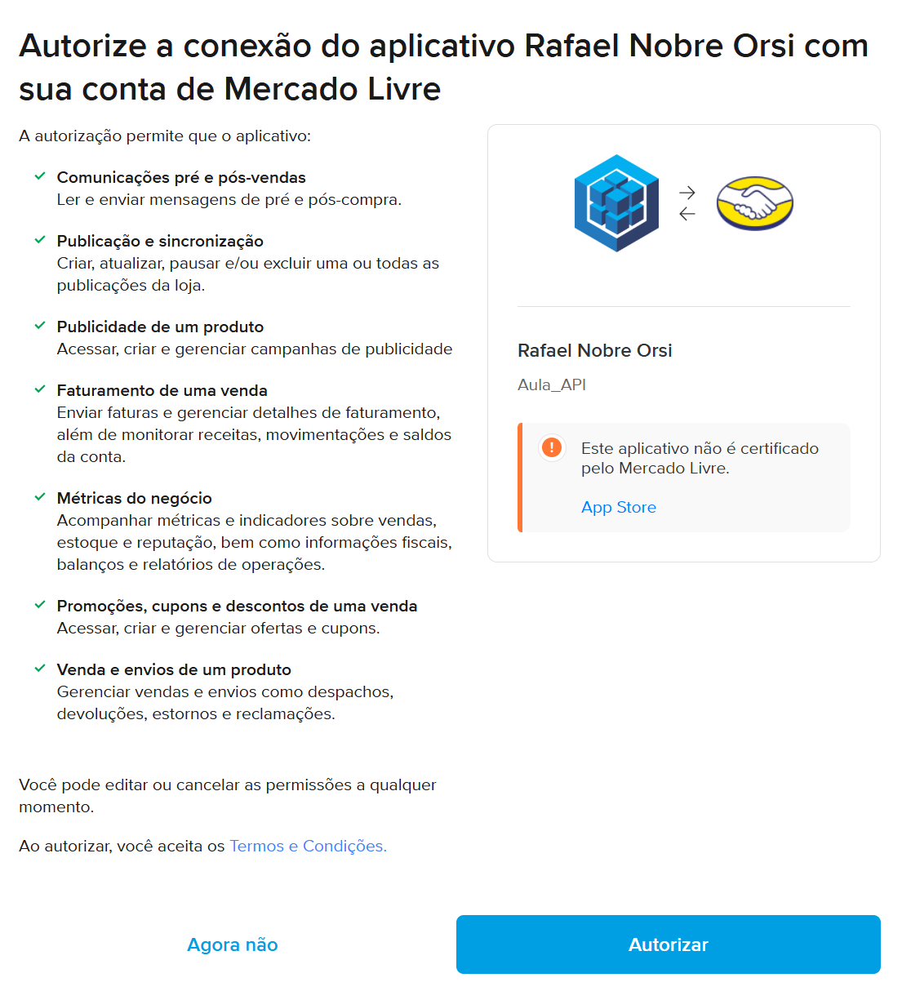

## 4.4. autorizar no navegador e copiar o `code`

Agora o processo sai temporariamente do Python.

1. copie a URL produzida pela célula anterior;
2. abra-a no navegador;
3. faça login com a conta proprietária da aplicação;
4. autorize a aplicação;
5. aguarde o redirecionamento;
6. observe a URL final na barra de endereço;
7. copie somente o valor depois de `code=` e antes de `&state=`.

Exemplo:

```text
https://example.com/?code=TG-ABC123&state=XYZ456
```

Nesse exemplo:

```text
code  = TG-ABC123
state = XYZ456
```

O `code` é temporário e de uso único. Ele **ainda não é o access token**.


## 4.5. Trocar o `code` pelo access token

A troca é feita com uma requisição `POST` para:

```text
https://api.mercadolibre.com/oauth/token
```

Agora precisamos do `Client Secret`, por isso ele será digitado com `getpass()`.

> Se ocorrer `invalid_grant`, verifique primeiro: `code` já utilizado/expirado, Redirect URI diferente da cadastrada ou `code` pertencente a outra tentativa de autorização.


In [13]:
client_secret_ml = getpass("Client Secret do Mercado Livre: ")
authorization_code_ml = getpass("Authorization code recebido: ")

url_token_ml = "https://api.mercadolibre.com/oauth/token"

dados_token_ml = {
    "grant_type": "authorization_code",
    "client_id": app_id_ml,
    "client_secret": client_secret_ml,
    "code": authorization_code_ml,
    "redirect_uri": redirect_uri_ml
}

resposta_token_ml = requests.post(
    url_token_ml,
    data=dados_token_ml,
    headers={
        "accept": "application/json",
        "content-type": "application/x-www-form-urlencoded"
    },
    timeout=20
)

print("Status HTTP:", resposta_token_ml.status_code)
resposta_token_ml.raise_for_status()

token_data_ml = resposta_token_ml.json()

print("Access token recebido:", "access_token" in token_data_ml)
print("Tipo:", token_data_ml.get("token_type"))
print("Expira em segundos:", token_data_ml.get("expires_in"))
print("Escopos:", token_data_ml.get("scope"))


Status HTTP: 200
Access token recebido: True
Tipo: Bearer
Expira em segundos: 21600
Escopos: read urn:global:admin:info:/read-only urn:global:admin:info:/read-write urn:global:admin:oauth:/read-only urn:global:admin:oauth:/read-write urn:global:admin:users:/read-only urn:global:admin:users:/read-write urn:ml:all:comunication:/read-only urn:ml:all:publish-sync:/read-only urn:ml:mktp:ads:/read-only urn:ml:mktp:comunication:/read-only urn:ml:mktp:invoices:/read-only urn:ml:mktp:metrics:/read-only urn:ml:mktp:offers:/read-only urn:ml:mktp:orders-shipments:/read-only urn:ml:mktp:publish-sync:/read-only write


## 4.6. Preparar o header de autenticação

A partir deste ponto, não precisamos colocar o token na URL. O Mercado Livre recomenda enviá-lo no header HTTP:

```text
Authorization: Bearer ACCESS_TOKEN
```

Essa configuração poderá ser reutilizada em todas as próximas chamadas autenticadas.


In [14]:
access_token_ml = token_data_ml["access_token"]

headers_ml = {"Authorization": f"Bearer {access_token_ml}"}

print("Header preparado. O token não será exibido.")


Header preparado. O token não será exibido.


## 5. Teste mínimo de autenticação

Antes de construir uma consulta maior, fazemos uma chamada pequena a `/users/me`.

Objetivo desta célula: responder apenas à pergunta **"o token funciona?"**.


In [15]:
resposta_usuario_ml = requisicao_get("https://api.mercadolibre.com/users/me", headers=headers_ml)

usuario_ml = resposta_usuario_ml.json()

print("Usuário autenticado:", usuario_ml.get("nickname"))
print("Site:", usuario_ml.get("site_id"))
print("ID:", usuario_ml.get("id"))


Status HTTP: 200
Usuário autenticado: MS20260217120137
Site: MLB
ID: 3210303604


## 6. Buscar produtos do catálogo

Agora utilizaremos um endpoint adequado para pesquisa textual de **produtos de catálogo**:

```text
GET https://api.mercadolibre.com/products/search
```

Parâmetros principais:

- `site_id=MLB`: Brasil;
- `status=active`: produtos ativos;
- `q`: texto de busca;
- `limit`: número de resultados;
- `offset`: posição inicial para paginação.

Vamos pesquisar:

```text
Smart TV 70
```

Observe que o retorno não é uma tabela. A resposta possui metadados de paginação e uma lista em `results`.


In [16]:
url_busca_ml = "https://api.mercadolibre.com/products/search"

parametros_busca_ml = {
    "site_id": "MLB",
    "status": "active",
    "q": "Smart TV 70",
    "limit": 20,
    "offset": 0
}

resposta_busca_ml = requisicao_get(
    url_busca_ml,
    params=parametros_busca_ml,
    headers=headers_ml
)

busca_ml = resposta_busca_ml.json()

print("Termo pesquisado:", busca_ml.get("keywords"))
print("Total informado pela API:", busca_ml.get("paging", {}).get("total"))
print("Resultados nesta página:", len(busca_ml.get("results", [])))


Status HTTP: 200
Termo pesquisado: Smart TV 70
Total informado pela API: 10000
Resultados nesta página: 20


## 6.1. Inspecionar a estrutura antes de criar o DataFrame

Antes de usar `pd.json_normalize()`, examine as chaves do primeiro produto. Essa prática evita selecionar colunas que não existem.


In [17]:
resultados_ml = busca_ml.get("results", [])

if resultados_ml:
    print("Campos do primeiro produto:")
    print(list(resultados_ml[0].keys()))
else:
    print("Nenhum produto retornado para a consulta.")


Campos do primeiro produto:
['id', 'catalog_product_id', 'domain_id', 'name', 'parent_id', 'settings', 'children_ids', 'attributes', 'tags', 'status', 'short_description', 'pictures', 'authority_types', 'date_created', 'last_updated', 'quality_type', 'product_standard', 'search_type']


## 6.2. Transformar os resultados em um DataFrame

A lista `results` é a parte da resposta que corresponde ao conjunto de produtos. Como alguns campos são aninhados, utilizaremos `pd.json_normalize()`.

Neste primeiro DataFrame manteremos os atributos de nível principal. Depois criaremos colunas específicas como marca e modelo.


In [18]:
df_produtos_ml = pd.json_normalize(resultados_ml)

print("Dimensão:", df_produtos_ml.shape)
df_produtos_ml.head()


Dimensão: (20, 21)


,id,catalog_product_id,domain_id,name,parent_id,children_ids,...,search_type,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content
0,MLB74613202,MLB74613202,MLB-TV_ANTENNAS,Antena Tdt para Smart TV Smart TV,MLB74613198,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
1,MLB52789883,MLB52789883,MLB-TELEVISIONS,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
2,MLB63066047,MLB63066047,MLB-TELEVISIONS,Smart TV Samsung 75 Qled Q6 Smart TV (2025),NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
3,MLB36185154,MLB36185154,MLB-TELEVISIONS,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
4,MLB62407410,MLB62407410,MLB-TELEVISIONS,Smart TV Hisense de 70 polegadas,NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,


## 6.4. Extrair atributos como marca, modelo e tamanho da tela

No retorno do catálogo, características técnicas costumam aparecer dentro de `attributes`, uma lista de objetos.

Em vez de manter essa lista inteira em uma célula, criaremos uma função para procurar um atributo pelo seu `id`.

IDs frequentemente úteis para televisores incluem `BRAND`, `MODEL` e atributos relacionados ao tamanho da tela. Como a estrutura pode variar entre produtos, o código utiliza uma lista de alternativas para o tamanho.


In [19]:
def valor_atributo(lista_atributos, ids_procurados):
    if not isinstance(lista_atributos, list):
        return None

    ids_procurados = set(ids_procurados)

    for atributo in lista_atributos:
        if atributo.get("id") in ids_procurados:
            return atributo.get("value_name")

    return None

if not df_produtos_ml.empty:
    df_produtos_ml["marca"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(x, ["BRAND"])
    )
    df_produtos_ml["modelo"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(x, ["MODEL"])
    )
    df_produtos_ml["tamanho_tela"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(
            x,
            ["SCREEN_SIZE", "DISPLAY_SIZE", "TV_SIZE"]
        )
    )

    colunas_ml = [
        "id", "name", "status", "domain_id",
        "marca", "modelo", "tamanho_tela"
    ]

    df_produtos_ml_base = df_produtos_ml[
        [c for c in colunas_ml if c in df_produtos_ml.columns]
    ].copy()
else:
    df_produtos_ml_base = pd.DataFrame()

df_produtos_ml_base


,id,name,status,domain_id,marca,modelo,tamanho_tela
0,MLB74613202,Antena Tdt para Smart TV Smart TV,active,MLB-TV_ANTENNAS,Distronik,SB-3002,NaN
1,MLB52789883,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",active,MLB-TELEVISIONS,Motorola,"Motorola Smart TV 50 50""","50 """
2,MLB63066047,Smart TV Samsung 75 Qled Q6 Smart TV (2025),active,MLB-TELEVISIONS,Samsung,Q6,"75 """
3,MLB36185154,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,active,MLB-TELEVISIONS,LG,75UR8750PSA,"75 """
4,MLB62407410,Smart TV Hisense de 70 polegadas,active,MLB-TELEVISIONS,Hisense,70A6,"70 """
5,MLB35086039,Smart TV Led Samsung 70 Un70Cu7000GCfv,active,MLB-TELEVISIONS,Samsung,UN70CU7000GCFV,"70 """
6,MLB62599860,Samsung Smart Tv 85 Uhd 4k + Samsung Smart Tv 50,active,MLB-TELEVISIONS,Samsung,UN85U8100FGXZD,"85 """
7,MLB24658978,"Smart TV Vizio M65q7-j01 Quantum 65"" Smart TV 4K",active,MLB-TELEVISIONS,Vizio,M65Q7-J01,"65 """
8,MLB62868674,Smart TV 5.0 Qled Q7f Vision Ai Smart TV (2025),active,MLB-TELEVISIONS,Samsung,QN50Q7FAAGX,"50 """
9,MLB21558719,Smart TV Hisense 60 4k Uhd Smart TV Hdr Roku T...,active,MLB-TELEVISIONS,Hisense,60R6E,"60 """


## 6.5. Obter detalhes dos produtos encontrados

A busca fornece uma lista resumida. Para aprofundar a coleta, podemos consultar cada `product_id` em:

```text
GET https://api.mercadolibre.com/products/{PRODUCT_ID}
```

O detalhe pode incluir `permalink`, `family_name`, atributos técnicos, imagens e informações da oferta vencedora (`buy_box_winner`) quando disponíveis.

Para não gerar muitas requisições em sala, consultaremos apenas os cinco primeiros produtos.


In [20]:
detalhes_produtos_ml = []

for product_id in df_produtos_ml_base.get("id", pd.Series(dtype=str)).head(5):
    resposta = requisicao_get(
        f"https://api.mercadolibre.com/products/{product_id}",
        headers=headers_ml
    )
    detalhes_produtos_ml.append(resposta.json())

print("Produtos detalhados:", len(detalhes_produtos_ml))


Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Produtos detalhados: 5


In [21]:
linhas_detalhes_ml = []

for produto in detalhes_produtos_ml:
    vencedor = produto.get("buy_box_winner") or {}

    linhas_detalhes_ml.append({
        "product_id": produto.get("id"),
        "nome": produto.get("name"),
        "familia": produto.get("family_name"),
        "status": produto.get("status"),
        "dominio": produto.get("domain_id"),
        "preco_oferta_vencedora": vencedor.get("price"),
        "moeda": vencedor.get("currency_id"),
        "frete_gratis": (vencedor.get("shipping") or {}).get("free_shipping"),
        "permalink": produto.get("permalink")
    })

df_detalhes_ml = pd.DataFrame(linhas_detalhes_ml)
df_detalhes_ml


,product_id,nome,familia,status,dominio,preco_oferta_vencedora,moeda,frete_gratis,permalink
0,MLB74613202,Antena Tdt para Smart TV Smart TV,Antena de TV Distronik SB-3002 para interno,active,MLB-TV_ANTENNAS,None,None,None,
1,MLB52789883,"Smart TV de 50"" Motorola Smart TV Motorola Sma...","Smart TV de 50"" Motorola Smart TV Motorola Sma...",active,MLB-TELEVISIONS,None,None,None,
2,MLB63066047,Smart TV Samsung 75 Qled Q6 Smart TV (2025),Smart TV Samsung 75 Qled Q6 Smart TV (2025),active,MLB-TELEVISIONS,None,None,None,
3,MLB36185154,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,active,MLB-TELEVISIONS,None,None,None,
4,MLB62407410,Smart TV Hisense de 70 polegadas,Smart TV Hisense de 70 polegadas,active,MLB-TELEVISIONS,None,None,None,


## 6.6. Paginação da busca

O Mercado Livre utiliza `offset` e `limit` neste recurso. A ideia é deslocar a janela de resultados:

```text
offset=0   → primeira página
offset=20  → segunda página
offset=40  → terceira página
```

A função abaixo reúne várias páginas em um único DataFrame.


In [22]:
def buscar_produtos_ml(termo, paginas=3, limite=20):
    produtos = []

    for pagina in range(paginas):
        params = {
            "site_id": "MLB",
            "status": "active",
            "q": termo,
            "limit": limite,
            "offset": pagina * limite
        }

        resposta = requests.get(
            "https://api.mercadolibre.com/products/search",
            params=params,
            headers=headers_ml,
            timeout=20
        )
        resposta.raise_for_status()

        lote = resposta.json().get("results", [])
        produtos.extend(lote)

        if len(lote) < limite:
            break

    return pd.json_normalize(produtos)


In [26]:
# Exemplo:
df_tv_70_multiplas_paginas = buscar_produtos_ml("Smart TV 70", paginas=3)
df_tv_70_multiplas_paginas.head(3)

,id,catalog_product_id,domain_id,name,parent_id,children_ids,...,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content,enhanced_content_template_id
0,MLB74613202,MLB74613202,MLB-TV_ANTENNAS,Antena Tdt para Smart TV Smart TV,MLB74613198,[],...,fixed,catalog_required,False,plaintext,,NaN
1,MLB52789883,MLB52789883,MLB-TELEVISIONS,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
2,MLB63066047,MLB63066047,MLB-TELEVISIONS,Smart TV Samsung 75 Qled Q6 Smart TV (2025),NaN,[],...,fixed,catalog_required,False,plaintext,,NaN


## 7. Diagnóstico rápido de erros do Mercado Livre

| Situação | Causa provável | Verificação |
|---|---|---|
| `redirect_uri` inválida | URI diferente entre cadastro e código | compare caractere por caractere |
| `invalid_grant` | `code` expirado, usado ou associado a outra tentativa | gere um novo `code` |
| `invalid_client` | Client ID ou Client Secret incorretos | confira o DevCenter |
| `401` | token ausente, inválido ou expirado | refaça autenticação/renovação |
| `403` | escopo/permissão insuficiente ou restrição da aplicação | revise escopos e conta |
| `429` | excesso de requisições | reduza frequência e implemente espera |


# 21. Exercícios

Os exercícios abaixo devem ser resolvidos reutilizando as células anteriores, sem escrever credenciais diretamente no notebook.

### Nível 1: busca simples

Pesquise `notebook gamer` no catálogo brasileiro e construa um `DataFrame` com pelo menos:

- `id`;
- nome;
- status;
- domínio;
- marca;
- modelo.

### Nível 2: comparação de consultas

Faça três buscas independentes:

```text
Smart TV 55
Smart TV 65
Smart TV 70
```

Crie uma única base contendo uma coluna `termo_busca` que identifique a origem de cada registro. Compare a quantidade de produtos retornados e as marcas mais frequentes.

### Nível 3: paginação

Modifique a função `buscar_produtos_ml()` para coletar até três páginas de resultados para `Smartphone 256 GB`. Verifique duplicidades pelo `id`.

### Nível 4: enriquecimento

Selecione cinco `product_id` e consulte `/products/{PRODUCT_ID}`. Crie uma base com preço da oferta vencedora, moeda, frete grátis e permalink quando esses campos estiverem disponíveis.

### Nível 5: desafio analítico

Escolha duas categorias de produtos de consumo. Construa um pequeno relatório comparando:

- quantidade de produtos encontrados;
- principais marcas;
- disponibilidade de preço no `buy_box_winner`;
- frequência de frete grátis;
- valores ausentes por campo.

Explique quais limitações impedem interpretar o resultado como uma amostra estatisticamente representativa de todo o marketplace.


In [25]:
df_notebook_gamer_multiplas_paginas = buscar_produtos_ml("notebook gamer", paginas=3)
df_notebook_gamer_multiplas_paginas.head(10)

,id,catalog_product_id,domain_id,name,children_ids,attributes,...,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content,parent_id
0,MLB52846446,MLB52846446,MLB-NOTEBOOKS,Notebook gamer Victus preto - AMD,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,NaN
1,MLB25959779,MLB25959779,MLB-HOME_OFFICE_DESKS,Mesa Computador Escrivaninha Notebook Gamer Br...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,"Seja para estudar ou trabalhar, esta mesa Loja...",MLB25602980
2,MLB43639942,MLB43639942,MLB-NOTEBOOKS,"Notebook gamer GF63 15.6"" preto - Intel",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,NaN
3,MLB23208217,MLB23208217,MLB-HOME_OFFICE_DESKS,Escrivaninha Mesa Computador Notebook Gamer Br...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,Escrivaninha Delta 1 Porta 1 Gaveta Benetil Mó...,MLB23208216
4,MLB24565256,MLB24565256,MLB-NOTEBOOKS,Notebook Gamer Dell G3 3579-a10p,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB24565233
5,MLB21172837,MLB21172837,MLB-NOTEBOOKS,Notebook Gamer Alienware Area 51mr2-a20s,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB21172834
6,MLB46616713,MLB46616713,MLB-NOTEBOOKS,Notebook gamer VICTUS - Intel Core i5,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,O HP Victus foi projetado para quem busca alto...,MLB37055283
7,MLB30067277,MLB30067277,MLB-HOME_OFFICE_DESKS,Mesa De Computador Notebook Gamer Escritório L...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,A Mesa Para Computador Lohan é a escolha certa...,MLB30067274
8,MLB32939968,MLB32939968,MLB-NOTEBOOKS,Notebook Gamer Alienware Area 51mr2-a40s Cor P...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB15297201
9,MLB21504494,MLB21504494,MLB-BACKPACKS,Mochila Para Notebook Gamer Dell 15.6 17.3 Preto,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,Divirta-se carregando tudo o que você precisa ...,MLB21504461


In [30]:
df_tv_55_multiplas_paginas = buscar_produtos_ml("Smart TV 55", paginas=3)
df_tv_65_multiplas_paginas = buscar_produtos_ml("Smart TV 65", paginas=3)
df_tv_70_multiplas_paginas = buscar_produtos_ml("Smart TV 70", paginas=3)

df_tv_55_multiplas_paginas["termo_busca"] = "Smart TV 55"
df_tv_65_multiplas_paginas["termo_busca"] = "Smart TV 65"
df_tv_70_multiplas_paginas["termo_busca"] = "Smart TV 70"

df_tv_todas_multiplas_paginas = pd.concat([
    df_tv_55_multiplas_paginas,
    df_tv_65_multiplas_paginas,
    df_tv_70_multiplas_paginas
])
print("Dimensão do DataFrame final:", df_tv_todas_multiplas_paginas.shape)



df_tv_todas_multiplas_paginas["marca"] = df_tv_todas_multiplas_paginas["attributes"].apply(
    lambda x: valor_atributo(x, ["BRAND"])
)

quantidade_por_marca = (
    df_tv_todas_multiplas_paginas["marca"]
    .value_counts()
    .rename_axis("marca")
    .reset_index(name="quantidade_produtos")
)


print("\nQuantidade por marca geral:")
print(quantidade_por_marca.head(10))


Dimensão do DataFrame final: (180, 23)

Quantidade por marca geral:
      marca  quantidade_produtos
0   Samsung                   53
1        LG                   19
2   Hisense                   10
3  Motorola                    9
4    Philco                    8
5    Kalley                    7
6       TCL                    6
7   Philips                    6
8   Hyundai                    4
9      Aiwa                    4


In [ ]:
# Nível 3: paginação

def buscar_produtos_ml_com_paginacao(termo, paginas=3, limite=20):
    produtos = []
    vistos = set()

    for pagina in range(paginas):
        params = {
            "site_id": "MLB",
            "status": "active",
            "q": termo,
            "limit": limite,
            "offset": pagina * limite,
        }

        resposta = requisicao_get(
            "https://api.mercadolibre.com/products/search",
            params=params,
            headers=headers_ml,
        )
        lote = resposta.json().get("results", [])

        if not lote:
            break

        for produto in lote:
            pid = produto.get("id")
            if pid not in vistos:
                vistos.add(pid)
                produtos.append(produto)

        if len(lote) < limite:
            break

    df = pd.json_normalize(produtos)
    return df


df_smartphone_256 = buscar_produtos_ml_com_paginacao("Smartphone 256 GB", paginas=3)
print("Total de registros únicos:", len(df_smartphone_256))
print("Duplicados por id:", df_smartphone_256["id"].duplicated().sum())


Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Total de registros únicos: 60
Duplicados por id: 0


In [33]:
# Nível 4: enriquecimento

ids_para_detalhar = df_smartphone_256.head(5)["id"].dropna().astype(str).tolist()

linhas_enriquecimento = []

for product_id in ids_para_detalhar:
    resposta = requisicao_get(
        f"https://api.mercadolibre.com/products/{product_id}",
        headers=headers_ml,
    )
    produto = resposta.json()
    vencedor = produto.get("buy_box_winner") or {}
    shipping = vencedor.get("shipping") or {}

    linhas_enriquecimento.append({
        "product_id": produto.get("id"),
        "preco_oferta_vencedora": vencedor.get("price"),
        "moeda": vencedor.get("currency_id"),
        "frete_gratis": shipping.get("free_shipping"),
        "permalink": produto.get("permalink"),
    })

if linhas_enriquecimento:
    df_enriquecimento = pd.DataFrame(linhas_enriquecimento)
else:
    df_enriquecimento = pd.DataFrame(columns=[
        "product_id",
        "preco_oferta_vencedora",
        "moeda",
        "frete_gratis",
        "permalink",
    ])

print(df_enriquecimento)


Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
    product_id preco_oferta_vencedora moeda frete_gratis permalink
0  MLB47543923                   None  None         None          
1  MLB47328442                   None  None         None          
2  MLB47317457                   None  None         None          
3  MLB25875149                   None  None         None          
4  MLB63947086                   None  None         None          


In [ ]:
# Nível 5: desafio analítico

categorias = [
    ("Smart TV 70", "eletronicos"),
    ("notebook gamer", "informatica"),
]

linhas_relatorio = []

for termo, categoria in categorias:
    df = buscar_produtos_ml(termo, paginas=2)
    df["categoria"] = categoria
    df["marca"] = df["attributes"].apply(lambda x: valor_atributo(x, ["BRAND"]))

    detalhes = []
    for product_id in df["id"].dropna().astype(str).head(5):
        resposta = requisicao_get(
            f"https://api.mercadolibre.com/products/{product_id}",
            headers=headers_ml,
        )
        produto = resposta.json()
        vencedor = produto.get("buy_box_winner") or {}
        detalhes.append({
            "product_id": produto.get("id"),
            "preco_disponivel": vencedor.get("price") != None,
            "frete_gratis": (vencedor.get("shipping") or {}).get("free_shipping"),
            "moeda": vencedor.get("currency_id"),
        })

    df_det = pd.DataFrame(detalhes)

    linhas_relatorio.append({
        "categoria": categoria,
        "quantidade_produtos": len(df),
        "principais_marcas": df["marca"].value_counts().head(3).to_dict(),
        "preco_disponivel": df_det["preco_disponivel"].mean() if not df_det.empty else None,
        "frete_gratis": df_det["frete_gratis"].fillna(False).mean() if not df_det.empty else None,
        "campos_ausentes": {
            "marca": int(df["marca"].isna().sum()),
            "preco_buy_box": int(df_det["preco_disponivel"].eq(False).sum()) if not df_det.empty else 0,
        },
    })

pd.DataFrame(linhas_relatorio)

Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200


,categoria,quantidade_produtos,principais_marcas,preco_disponivel,frete_gratis,campos_ausentes
0,eletronicos,40,"{'Samsung': 18, 'LG': 6, 'Hisense': 2}",0.0,0.0,"{'marca': 0, 'preco_buy_box': 5}"
1,informatica,40,"{'Dell': 8, 'HP': 4, 'Loja Tigo': 3}",0.0,0.0,"{'marca': 0, 'preco_buy_box': 5}"


## 6 Sqlite

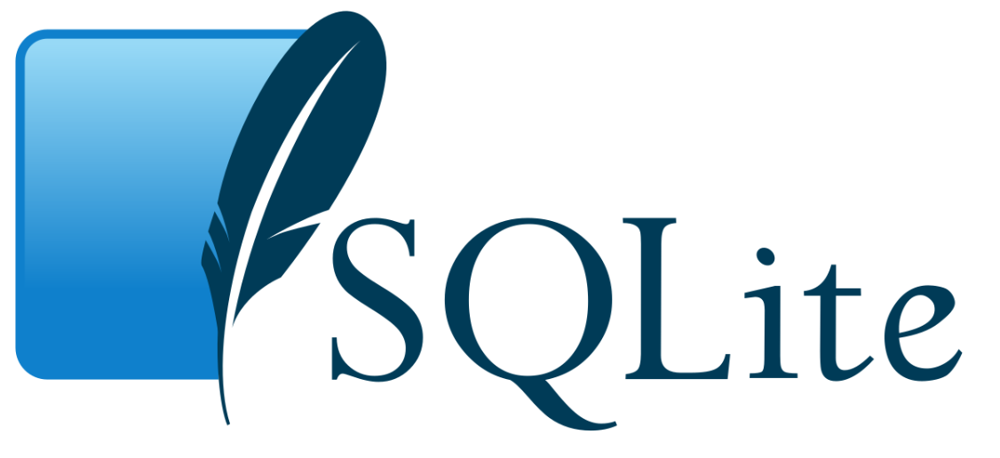

#### Passo 1: Instalar bibliotecas

In [ ]:
#!pip install sqlite3 

#### Passo 2: Importar bibliotecas

In [2]:
import sqlite3
import pandas as pd

#### Passo 3: Amostra de dados de entrada

In [3]:
# Exemplo de DataFrame obtido após o scraping
data = {
    "titulo": ["Notebook Dell", "Smartphone Samsung", "Livro Python", "Monitor LG"],
    "preco": [3500.00, 2100.00, 89.90, 899.00],
    "categoria": ["Eletrônicos", "Eletrônicos", "Livros", "Eletrônicos"]
}
df = pd.DataFrame(data)
df

,titulo,preco,categoria
0,Notebook Dell,3500.0,Eletrônicos
1,Smartphone Samsung,2100.0,Eletrônicos
2,Livro Python,89.9,Livros
3,Monitor LG,899.0,Eletrônicos


#### Passo 4: Conexão com banco SQLite

In [4]:
conn = sqlite3.connect('produtos.db')  # Cria ou conecta ao banco de dados SQLite

A classe Cursor é uma instância com a qual você pode invocar métodos que executam instruções SQLite e buscam dados dos conjuntos de resultados das consultas. Você pode criar um objeto Cursor usando o método cursor() do objeto/classe Connection.

In [5]:
cursor = conn.cursor()

#### Passo 5: Criando tabela

Nesta etapa utilizaremos a sintaxe: `cursor.execute(""" ... """)`

- O cursor é quem envia comandos SQL para o banco.
- O método execute() executa o SQL que está entre aspas triplas """ ... """.
- Usamos aspas triplas para poder escrever o comando em várias linhas, deixando mais organizado.

In [6]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    preco REAL NOT NULL,
    categoria TEXT NOT NULL
    );
""")

### Vamos entender cada comando que foi utilizado aqui:

1) `CREATE TABLE IF NOT EXISTS produtos`
- `CREATE TABLE`  cria uma nova tabela no banco.
- `IF NOT EXISTS`  evita erro caso a tabela já exista (sem isso, o comando falharia).
- `produtos`  é o nome da tabela.

2) `id INTEGER PRIMARY KEY AUTOINCREMENT,`
- `id`  nome da coluna.
- `INTEGER`  tipo de dado (número inteiro).
- `PRIMARY KEY`  define que essa coluna é a chave primária da tabela (identificador único de cada linha).
- `AUTOINCREMENT`  cada novo registro recebe automaticamente um valor de ID (1, 2, 3, …).

3) `titulo TEXT NOT NULL,`
- `titulo` → nome da coluna.
- `TEXT` → tipo de dado (texto de tamanho variável).
- `NOT NULL` → esse campo não pode ficar vazio

4) `preco REAL NOT NULL,`
- `preco` nome da coluna.
- `REAL` tipo de dado para números decimais (preço pode ter vírgula/ponto).
- `NOT NULL` não pode ficar em branco.

5) `categoria TEXT NOT NULL`
- `categoria` → nome da coluna.
- `TEXT` → tipo de dado (texto).
- `NOT NULL` → obrigatório.

#### Passo 6: Inserindo dados do DataFrame no banco

In [7]:
for _, row in df.iterrows():
    cursor.execute("""
    INSERT INTO produtos (titulo, preco, categoria) VALUES (?, ?, ?)
    """, (row['titulo'], row['preco'], row['categoria']))
conn.commit()

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


### Novamente, vamos entender cada comando
1) `for _, row in df.iterrows():`
- O método `iterrows()` do **Pandas** serve para **percorrer um DataFrame linha por linha**
- Esse método devolve, a cada iteração, um **par** (índice, linha):
- Usando `for _, row` é possível ignorar o índice substituindo o nome da variável por `_`
    - `index, row`  pegaria os dois.
    - `_, row` ignora o índice e pega só a linha

2) `INSERT INTO produtos (titulo, preco, categoria) VALUES (?, ?, ?)", (row["titulo"], row["preco"], row["categoria"])`
- Esse comando SQL insere uma nova linha na tabela produtos
- `INSERT INTO produtos (titulo, preco, categoria)` indica em quais colunas você vai inserir dados.`
- `VALUES (?, ?, ?)`  são **placeholders** (marcadores) para os valores reais.
    - `?` significa "substitua aqui por um valor passado no Python".
- `(row["titulo"], row["preco"], row["categoria"])` é uma tupla com os valores da linha do DataFrame que vão substituir os `?`

#### Passo 7: Consulta SQL

##### Ex 1: Selecionar produtos abaixo de 1000 reais

In [9]:
for row in cursor.execute("SELECT * FROM produtos WHERE preco > 1000"):
    print(row)

(1, 'Notebook Dell', 3500.0, 'Eletrônicos')
(2, 'Smartphone Samsung', 2100.0, 'Eletrônicos')


- `SELECT *`  busca todas as colunas da tabela.
- `FROM produtos` consulta a tabela produtos.
- `WHERE preco < 1000` aplica um filtro: só traz os produtos cujo preço seja menor que 1000.

##### Ex 2: Top 2 produtos mais caros

In [10]:
for row in cursor.execute("SELECT * FROM produtos ORDER BY preco DESC LIMIT 2;"):
    print(row)

(1, 'Notebook Dell', 3500.0, 'Eletrônicos')
(2, 'Smartphone Samsung', 2100.0, 'Eletrônicos')


1) `SELECT titulo, preco` Pede ao banco apenas as colunas titulo e preco (não traz todas as colunas como no `*`
2) `ORDER BY preco DESC` Ordena os resultados pelo preço (preco) em ordem decrescente (DESC) - (ASC seria crescente, padrão do SQL)
3) `LIMIT 2` Limita o número de registros retornados a 2 linhas apenas

##### Ex 3: Contagem por categorias

In [11]:
for row in cursor.execute("SELECT categoria, COUNT(*) FROM produtos GROUP BY categoria;"):
    print(row)

('Eletrônicos', 3)
('Livros', 1)


1) `SELECT categoria` Seleciona a coluna "categoria"
2) `COUNT(*)` Conta o número de registros
3) `FROM produtos` Da tabela "produtos"
4) `GROUP BY categoria` Agrupa os resultados por categoria

#### Passo 8: Encerra conexão com banco de dados

In [12]:
conn.close()  # Fecha a conexão com o banco de dados

## 7 Webscraping Sqlite

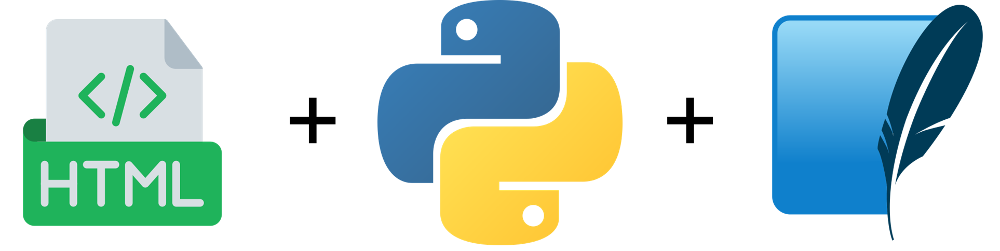

#### Passo 1: Instalar bibliotecas

In [1]:
#!pip install requests
#!pip install beautifulsoup4
#!pip install sqlite3 
#!pip install pandas

#### Passo 2: Importar bibliotecas

In [2]:
import requests
from bs4 import BeautifulSoup
import sqlite3
import pandas as pd

#### Passo 3: Fromatar link de busca

Neste exemplo utilizaremos um site público de testes de scraping

http://books.toscrape.com (feito exatamente para treinar scraping).

In [3]:
# URL base
url = "https://books.toscrape.com/catalogue/category/books_1/page-1.html"

#### Passo 4: Determinar variáveis que para armazenamento
Neste exemplo, iremos utilizar:
- Título
- Preços
- Estoque

In [4]:
titulos, precos, estoque = [], [], []

#### Passo 5: Obter informações do link

In [5]:
response = requests.get(url)
soup = BeautifulSoup(response.text, "html.parser")

#### Passo 5.1: Obter informações dos produtos

In [6]:
# Cada produto está dentro de article.product_pod
livros = soup.find_all("article", class_="product_pod")

In [7]:
livros[0].h3.a['title']

'A Light in the Attic'

In [8]:
# Preço
livros[0].find("p", class_="price_color").text.replace("Â£", "")

'51.77'

In [9]:
# Estoque
livros[0].find("p", class_="instock availability").text.strip() 
# A função strip()em Python serve para remover espaços em branco ou caracteres específicos do início e/ou fim de uma string

'In stock'

#### Passo 6: Coletar dados em escala
Neste exemplo, vamos coletar dados das 5 primeiras páginas

In [10]:
for page in range(1, 5):
    response = requests.get(f"https://books.toscrape.com/catalogue/category/books_1/page-{page}.html")
    soup = BeautifulSoup(response.text, "html.parser")
    
    # Cada produto está dentro de article.product_pod
    livros = soup.find_all("article", class_="product_pod")
    
    for livro in livros:
        # Título
        titulo = livro.h3.a["title"]
        titulos.append(titulo)
        
        # Preço
        preco = livro.find("p", class_="price_color").text.replace("Â£", "")
        precos.append(preco)
        
        # Estoque
        estoque_info = livro.find("p", class_="instock availability").text.strip()
        estoque.append(estoque_info)

print("Coleta concluída!")

Coleta concluída!


#### Passo 7: Criar DataFrame

In [11]:
df = pd.DataFrame({"titulo": titulos, "preco": precos, "estoque": estoque})
df.head()

,titulo,preco,estoque
0,A Light in the Attic,51.77,In stock
1,Tipping the Velvet,53.74,In stock
2,Soumission,50.10,In stock
3,Sharp Objects,47.82,In stock
4,Sapiens: A Brief History of Humankind,54.23,In stock


#### Passo 8: Criar Banco de Dados

In [12]:
conn = sqlite3.connect('livros.db')
cursor = conn.cursor()

#### Passo 9: DDL – Data Definition Language
DDL serve para **definir a estrutura do banco de dados**: criar, alterar e excluir tabelas.

- `CREATE` → cria tabelas e estruturas  
- `ALTER` → modifica a estrutura de tabelas  
- `DROP` → apaga tabelas ou bancos de dados  


In [13]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS livro (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    estoque TEXT NOT NULL,
    preco REAL NOT NULL
);
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


##### 9.1: Listar todas tabelas do banco
Neste exemplo iremos utilizaremos a sintaxe `SELECT name FROM sqlite_master;`

- `sqlite_master` é uma tabela especial **interna** do SQLite que guarda **metadados** sobre o banco de dados: tabelas, índices, views e triggers
- `SELECT name` seleciona apenas o nome (`name`) dos objetos armazenados no `sqlite_master`

In [14]:
cursor.execute(''' SELECT name FROM sqlite_master; ''')
print(cursor.fetchall())

[('sqlite_sequence',), ('livro',)]


Como pegar os resultados usando o método `fetch` (buscar)
- `fetchone()` Retorna apenas uma linha do resultado (a próxima disponível). Se não houver mais nada, retorna `None`
- `fetchmany(n)` Retorna as próximas n linhas do resultado.
- `fetchall()` Retorna todas as linhas restantes do resultado em uma lista de tuplas.

##### 9.2: Verificar o esquema da tabela (estrutura das colunas)

In [15]:
cursor.execute(''' PRAGMA table_info(livro); ''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'estoque', 'TEXT', 1, None, 0)
(3, 'preco', 'REAL', 1, None, 0)


O comando `PRAGMA table_info(livro)` mostra as colunas da tabela, seus tipos e as principais restrições.

##### 9.3: Alterar tabela
Nesta etapa utilizaremos o comando `ALTER TABLE` informar a alteração da tabela e o comando `ADD COLUMN` para especificar a alteração

In [16]:
cursor.execute(''' ALTER TABLE livro ADD COLUMN categoria TEXT; ''')
conn.commit()
print("Coluna 'categoria' adicionada com sucesso!")

Coluna 'categoria' adicionada com sucesso!


##### 9.4: Verifica o equema da tabela após incluir coluna coluna

In [17]:
cursor.execute(''' PRAGMA table_info(livro); ''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'estoque', 'TEXT', 1, None, 0)
(3, 'preco', 'REAL', 1, None, 0)
(4, 'categoria', 'TEXT', 0, None, 0)


##### 9.5: Remover uma coluna 
Nesta etapa utilizaremos o comando `ALTER TABLE` informar a alteração da tabela e o comando `DROP COLUMN` para especificar a alteração

In [18]:
cursor.execute(''' ALTER TABLE livro DROP COLUMN categoria; ''')
conn.commit()
print("Coluna 'categoria' removida com sucesso!")

Coluna 'categoria' removida com sucesso!


##### 9.6: Verifica o equema da tabela após incluir coluna coluna

In [19]:
cursor.execute(''' PRAGMA table_info(livro); ''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'estoque', 'TEXT', 1, None, 0)
(3, 'preco', 'REAL', 1, None, 0)


##### 9.7: Excluir tabela
Primeiro vamos criar uma tabela adicional

In [20]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS produto (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    autor TEXT NOT NULL,
    preco REAL NOT NULL
);
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


##### Listar todas tabelas do banco

In [21]:
cursor.execute(''' SELECT name FROM sqlite_master; ''')
print(cursor.fetchall())

[('sqlite_sequence',), ('livro',), ('produto',)]


##### Remover tabela do banco

In [22]:
cursor.execute(''' DROP TABLE IF EXISTS livro; ''')
conn.commit()
print("Tabela 'livro' removida com sucesso!")

Tabela 'livro' removida com sucesso!


##### Listar todas tabelas do banco

In [23]:
cursor.execute(''' SELECT name FROM sqlite_master; ''')
print(cursor.fetchall())

[('sqlite_sequence',), ('produto',)]


#### Passo 10: DML – Data Manipulation Language

DML serve para **manipular os dados** dentro das tabelas:

- `INSERT` → inserir registros  
- `UPDATE` → atualizar registros  
- `DELETE` → excluir registros



##### 10.1 `INSERT` (inserir dados)

In [24]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS livro (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    estoque TEXT NOT NULL,
    preco REAL NOT NULL
);
""")
for _, row in df.iterrows():
    cursor.execute("""
    INSERT INTO livro (titulo, preco, estoque) VALUES (?, ?, ?)
    """, (row['titulo'], row['preco'], row['estoque']))
conn.commit()

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


##### Verifica quantos registros foram inseridos

In [25]:
cursor.execute("SELECT COUNT(*) FROM livro;")
cursor.fetchone()

(80,)

##### Verifica uma amostra dos registros inseridos

In [26]:
cursor.execute("SELECT * FROM livro;")
cursor.fetchmany(5)

[(1, 'A Light in the Attic', 'In stock', 51.77),
 (2, 'Tipping the Velvet', 'In stock', 53.74),
 (3, 'Soumission', 'In stock', 50.1),
 (4, 'Sharp Objects', 'In stock', 47.82),
 (5, 'Sapiens: A Brief History of Humankind', 'In stock', 54.23)]

##### 10.2: `UPDATE` (atualizar dados)

In [27]:
cursor.execute("UPDATE livro SET preco =  49.90 WHERE titulo = 'Sharp Objects';")
conn.commit()
print("Preço atualizado com sucesso!")

Preço atualizado com sucesso!


##### Verifica uma amostra dos registros inseridos

In [28]:
cursor.execute("SELECT titulo, preco FROM livro WHERE titulo = 'Sharp Objects';")
cursor.fetchone()

('Sharp Objects', 49.9)

##### 10.3: Inserir um novo registro no banco

In [29]:
cursor.execute("INSERT INTO livro (titulo, estoque, preco) VALUES ('Exemplo de Livro', 'Autor Exemplo', 19.99)")
cursor.execute("INSERT INTO livro (titulo, estoque, preco) VALUES ('Exemplo de Livro 2', 'Autor Exemplo 2', 19.99)")
cursor.execute("INSERT INTO livro (titulo, estoque, preco) VALUES ('Exemplo de Livro 3', 'Autor Exemplo 3', 19.99)")
cursor.execute("INSERT INTO livro (titulo, estoque, preco) VALUES ('Exemplo de Livro 4', 'Autor Exemplo 4', 19.99)")
cursor.execute("INSERT INTO livro (titulo, estoque, preco) VALUES ('Exemplo de Livro 5', 'Autor Exemplo 5', 19.99)")

print("Livro inserido com sucesso!")

Livro inserido com sucesso!


##### Verifica quantos registros existem no banco

In [30]:
cursor.execute("SELECT COUNT(*) FROM livro;")
cursor.fetchone()

(85,)

##### Verifica uma amostra dos últimos registros inseridos

In [31]:
cursor.execute("SELECT * FROM livro ORDER BY id DESC;")
cursor.fetchmany(5)

[(85, 'Exemplo de Livro 5', 'Autor Exemplo 5', 19.99),
 (84, 'Exemplo de Livro 4', 'Autor Exemplo 4', 19.99),
 (83, 'Exemplo de Livro 3', 'Autor Exemplo 3', 19.99),
 (82, 'Exemplo de Livro 2', 'Autor Exemplo 2', 19.99),
 (81, 'Exemplo de Livro', 'Autor Exemplo', 19.99)]

##### 10.4: `DELETE` (exclui registros)

In [32]:
cursor.execute("DELETE FROM livro WHERE titulo = 'Exemplo de Livro';")
conn.commit()
print("Livro deletado com sucesso!")

Livro deletado com sucesso!


##### Verifica uma amostra dos últimos registros inseridos

In [33]:
cursor.execute("SELECT * FROM livro ORDER BY id DESC;")
cursor.fetchmany(5)

[(85, 'Exemplo de Livro 5', 'Autor Exemplo 5', 19.99),
 (84, 'Exemplo de Livro 4', 'Autor Exemplo 4', 19.99),
 (83, 'Exemplo de Livro 3', 'Autor Exemplo 3', 19.99),
 (82, 'Exemplo de Livro 2', 'Autor Exemplo 2', 19.99),
 (80,
  'Rat Queens, Vol. 3: Demons (Rat Queens (Collected Editions) #11-15)',
  'In stock',
  50.4)]

#### Passo 11: DQL serve para **consultar dados** no banco:

- `SELECT`  
- `WHERE`  
- `ORDER BY`  
- `GROUP BY`  
- Funções de agregação (`COUNT`, `AVG`, `MAX`, `MIN`, `SUM`) 

##### Consulta simples com `fetchone`

In [34]:
cursor.execute("SELECT * FROM livro")
cursor.fetchone()

(1, 'A Light in the Attic', 'In stock', 51.77)

##### Consulta simples com `fetchmany()`

In [35]:
cursor.execute("SELECT * FROM livro")
cursor.fetchone()

(1, 'A Light in the Attic', 'In stock', 51.77)

##### Consulta simples com `fetchall()`

In [36]:
cursor.execute("SELECT * FROM livro")
cursor.fetchall()

[(1, 'A Light in the Attic', 'In stock', 51.77),
 (2, 'Tipping the Velvet', 'In stock', 53.74),
 (3, 'Soumission', 'In stock', 50.1),
 (4, 'Sharp Objects', 'In stock', 49.9),
 (5, 'Sapiens: A Brief History of Humankind', 'In stock', 54.23),
 (6, 'The Requiem Red', 'In stock', 22.65),
 (7, 'The Dirty Little Secrets of Getting Your Dream Job', 'In stock', 33.34),
 (8,
  'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  'In stock',
  17.93),
 (9,
  'The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics',
  'In stock',
  22.6),
 (10, 'The Black Maria', 'In stock', 52.15),
 (11, 'Starving Hearts (Triangular Trade Trilogy, #1)', 'In stock', 13.99),
 (12, "Shakespeare's Sonnets", 'In stock', 20.66),
 (13, 'Set Me Free', 'In stock', 17.46),
 (14,
  "Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)",
  'In stock',
  52.29),
 (15, 'Rip it Up and Start Again', 'In stock', 35.02),
 (16,
  'Our Band Could Be 

#### `WHERE`
##### Consulta com filtro: Livros com preço abaixo de 20 

In [37]:
cursor.execute("SELECT titulo, preco FROM livro WHERE preco < 20.00")
cursor.fetchall()

[('The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  17.93),
 ('Starving Hearts (Triangular Trade Trilogy, #1)', 13.99),
 ('Set Me Free', 17.46),
 ('In Her Wake', 12.84),
 ('The Four Agreements: A Practical Guide to Personal Freedom', 17.66),
 ("Sophie's World", 15.94),
 ('Maude (1883-1993):She Grew Up with the country', 18.02),
 ('In a Dark, Dark Wood', 19.63),
 ('Untitled Collection: Sabbath Poems 2014', 14.27),
 ('Unicorn Tracks', 18.78),
 ('Tsubasa: WoRLD CHRoNiCLE 2 (Tsubasa WoRLD CHRoNiCLE #2)', 16.28),
 ('This One Summer', 19.49),
 ('Thirst', 17.27),
 ('The Torch Is Passed: A Harding Family Story', 19.09),
 ('The Life-Changing Magic of Tidying Up: The Japanese Art of Decluttering and Organizing',
  16.77),
 ('The Age of Genius: The Seventeenth Century and the Birth of the Modern Mind',
  19.73),
 ('Reskilling America: Learning to Labor in the Twenty-First Century', 19.83),
 ('Exemplo de Livro 2', 19.99),
 ('Exemplo de Livro 3', 19.99),
 

#### `ORDER BY`
##### Consulta com ordenação: Top 5 livros mais caros 

In [38]:
cursor.execute("SELECT titulo, preco FROM livro ORDER BY preco DESC LIMIT 5;")
cursor.fetchall()

[('The Death of Humanity: and the Case for Life', 58.11),
 ('Slow States of Collapse: Poems', 57.31),
 ('Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  57.25),
 ('The Past Never Ends', 56.5),
 ('The Pioneer Woman Cooks: Dinnertime: Comfort Classics, Freezer Food, 16-Minute Meals, and Other Delicious Ways to Solve Supper!',
  56.41)]

#### `GROUP BY`
##### Consulta com agregação: Quantidade de livros por situação de estoque 

In [39]:
cursor.execute("SELECT titulo, preco FROM livro GROUP BY estoque;")
cursor.fetchall()

[('Exemplo de Livro 2', 19.99),
 ('Exemplo de Livro 3', 19.99),
 ('Exemplo de Livro 4', 19.99),
 ('Exemplo de Livro 5', 19.99),
 ('A Light in the Attic', 51.77)]

#### `DISTINCT`
##### Consulta com filtro: Contagem de dados distintos

In [40]:
cursor.execute("SELECT COUNT(DISTINCT estoque) FROM livro;")
cursor.fetchall()

[(5,)]

#### `HAVING COUNT(*)`
##### Consulta com filtro: Contagem de dados repetidos

In [41]:
cursor.execute("SELECT preco FROM livro GROUP BY preco HAVING COUNT(*) > 1;")
cursor.fetchall()

[(19.99,), (44.18,)]

#### `AVG`
##### Consulta com agregação: Valor médio dos livros 

In [42]:
cursor.execute("SELECT AVG(preco) FROM livro;")
cursor.fetchone()

(34.98464285714286,)

##### Consulta com agregação: Valor médio dos livros  (com arredondamento)

In [43]:
cursor.execute("SELECT ROUND(AVG(preco), 2) FROM livro;")
cursor.fetchone()

(34.98,)

#### `MAX`
##### Consulta com agregação: Maior valor entre os livros `MAX`

In [44]:
cursor.execute("SELECT MAX(preco) FROM livro;")
cursor.fetchone()

(58.11,)

#### `MIN`
##### Consulta com agregação: Menor valor entre os livros 

In [45]:
cursor.execute("SELECT MIN(preco) FROM livro;")
cursor.fetchone()

(12.84,)

#### `SUM`
##### Consulta com agregação: Soma do valor dos livros

In [46]:
cursor.execute("SELECT SUM(preco) FROM livro;")
cursor.fetchone()

(2938.71,)

##### Consulta com agregação: Soma do valor dos livros em estoque

In [47]:
cursor.execute("SELECT SUM(preco) FROM livro WHERE estoque LIKE '%In stock%';")
cursor.fetchone()

(2858.75,)

##### Consulta com agregação: Soma do valor dos livros sem estoque

In [48]:
cursor.execute("SELECT SUM(preco) FROM livro WHERE estoque LIKE '%Out of stock%';")
cursor.fetchone()

(None,)

##### Consulta de multiplos valores: Valor Máximo, Medio e Mínimo

In [49]:
cursor.execute("SELECT MAX(preco), ROUND(AVG(preco), 2), MIN(preco) FROM livro;")
cursor.fetchone()

(58.11, 34.98, 12.84)

##### Consulta com Ranking por Preço

In [50]:
cursor.execute("""
SELECT titulo, preco, RANK() OVER (ORDER BY preco DESC) AS ranking
FROM livro
ORDER BY preco DESC;
""")
cursor.fetchall()

[('The Death of Humanity: and the Case for Life', 58.11, 1),
 ('Slow States of Collapse: Poems', 57.31, 2),
 ('Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  57.25,
  3),
 ('The Past Never Ends', 56.5, 4),
 ('The Pioneer Woman Cooks: Dinnertime: Comfort Classics, Freezer Food, 16-Minute Meals, and Other Delicious Ways to Solve Supper!',
  56.41,
  5),
 ('The Secret of Dreadwillow Carse', 56.13, 6),
 ('The Electric Pencil: Drawings from Inside State Hospital No. 3', 56.06, 7),
 ('Birdsong: A Story in Pictures', 54.64, 8),
 ('Sapiens: A Brief History of Humankind', 54.23, 9),
 ('The Murder That Never Was (Forensic Instincts #5)', 54.11, 10),
 ('Tipping the Velvet', 53.74, 11),
 ('Aladdin and His Wonderful Lamp', 53.13, 12),
 ("Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)", 52.29, 13),
 ('Behind Closed Doors', 52.22, 14),
 ('The Black Maria', 52.15, 15),
 ('A Light in the Attic', 51.77, 16),
 ('Libertarianism for Beginners', 51.33, 17),
 

#### 12: JOINS – Relacionando tabelas

JOINS permitem **combinar dados de várias tabelas**.  
Vamos criar outras tabelas para exemplificar.

##### 12.1 Criar tabela de vendas

In [51]:
cursor.execute("PRAGMA foreign_keys = ON;")
cursor.execute("""
CREATE TABLE IF NOT EXISTS vendas (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    livro_id INTEGER NOT NULL,
    quantidade INTEGER NOT NULL CHECK (quantidade > 0),
    data_venda TEXT NOT NULL,
    FOREIGN KEY (livro_id) REFERENCES livro(id)
);
""")
conn.commit()
print("Tabela 'vendas' criada com sucesso!")

Tabela 'vendas' criada com sucesso!


##### Verifica o esquema da tabela (estrutura das colunas)

In [52]:
cursor.execute(''' PRAGMA table_info(vendas); ''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'livro_id', 'INTEGER', 1, None, 0)
(2, 'quantidade', 'INTEGER', 1, None, 0)
(3, 'data_venda', 'TEXT', 1, None, 0)


##### 12.2: Inserir dados de exemplo

In [53]:
livros_disponiveis = cursor.execute("SELECT id FROM livro ORDER BY id LIMIT 5;").fetchall()
quantidades = [2, 1, 3, 1, 2]
datas = ["2026-01-10", "2026-01-11", "2026-01-12", "2026-01-13", "2026-01-14"]
vendas_exemplo = [
    (livro_id[0], quantidade, data)
    for livro_id, quantidade, data in zip(livros_disponiveis, quantidades, datas)
]
cursor.executemany(
    "INSERT INTO vendas (livro_id, quantidade, data_venda) VALUES (?, ?, ?);",
    vendas_exemplo
)
conn.commit()
print(f"{len(vendas_exemplo)} venda(s) de exemplo inserida(s)!")

5 venda(s) de exemplo inserida(s)!


##### Verifica dados inseridos 

In [54]:
cursor.execute("SELECT * FROM vendas;")
cursor.fetchall()

[(1, 1, 2, '2026-01-10'),
 (2, 2, 1, '2026-01-11'),
 (3, 3, 3, '2026-01-12'),
 (4, 4, 1, '2026-01-13'),
 (5, 5, 2, '2026-01-14')]

##### 12.3: Exemplos de JOINs com a tabela existente

In [55]:
# INNER JOIN: mostra somente livros que possuem vendas.
cursor.execute("""
SELECT livro.titulo, vendas.quantidade, vendas.data_venda
FROM vendas
INNER JOIN livro ON vendas.livro_id = livro.id;
""")
cursor.fetchall()

[('A Light in the Attic', 2, '2026-01-10'),
 ('Tipping the Velvet', 1, '2026-01-11'),
 ('Soumission', 3, '2026-01-12'),
 ('Sharp Objects', 1, '2026-01-13'),
 ('Sapiens: A Brief History of Humankind', 2, '2026-01-14')]

In [56]:
# LEFT JOIN: inclui livros mesmo quando ainda não possuem vendas.
cursor.execute("""
SELECT livro.titulo, vendas.quantidade, vendas.data_venda
FROM livro
LEFT JOIN vendas ON vendas.livro_id = livro.id;
""")
cursor.fetchall()

[('A Light in the Attic', 2, '2026-01-10'),
 ('Tipping the Velvet', 1, '2026-01-11'),
 ('Soumission', 3, '2026-01-12'),
 ('Sharp Objects', 1, '2026-01-13'),
 ('Sapiens: A Brief History of Humankind', 2, '2026-01-14'),
 ('The Requiem Red', None, None),
 ('The Dirty Little Secrets of Getting Your Dream Job', None, None),
 ('The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  None,
  None),
 ('The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics',
  None,
  None),
 ('The Black Maria', None, None),
 ('Starving Hearts (Triangular Trade Trilogy, #1)', None, None),
 ("Shakespeare's Sonnets", None, None),
 ('Set Me Free', None, None),
 ("Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)", None, None),
 ('Rip it Up and Start Again', None, None),
 ('Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  None,
  None),
 ('Olio', None, None),
 ('Mesaerion: The Best Science Fictio

In [57]:
# Equivalente a um RIGHT JOIN: inverte as tabelas e usa LEFT JOIN.
cursor.execute("""
SELECT livro.titulo, vendas.quantidade, vendas.data_venda
FROM vendas
LEFT JOIN livro ON vendas.livro_id = livro.id;
""")
cursor.fetchall()

[('A Light in the Attic', 2, '2026-01-10'),
 ('Tipping the Velvet', 1, '2026-01-11'),
 ('Soumission', 3, '2026-01-12'),
 ('Sharp Objects', 1, '2026-01-13'),
 ('Sapiens: A Brief History of Humankind', 2, '2026-01-14')]

In [58]:
# FULL OUTER JOIN: combina os dois LEFT JOINs para incluir registros sem correspondência.
cursor.execute("""
SELECT livro.titulo, vendas.quantidade, vendas.data_venda
FROM livro
LEFT JOIN vendas ON vendas.livro_id = livro.id
UNION ALL
SELECT livro.titulo, vendas.quantidade, vendas.data_venda
FROM vendas
LEFT JOIN livro ON vendas.livro_id = livro.id
WHERE livro.id IS NULL;
""")
cursor.fetchall()

[('A Light in the Attic', 2, '2026-01-10'),
 ('Tipping the Velvet', 1, '2026-01-11'),
 ('Soumission', 3, '2026-01-12'),
 ('Sharp Objects', 1, '2026-01-13'),
 ('Sapiens: A Brief History of Humankind', 2, '2026-01-14'),
 ('The Requiem Red', None, None),
 ('The Dirty Little Secrets of Getting Your Dream Job', None, None),
 ('The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  None,
  None),
 ('The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics',
  None,
  None),
 ('The Black Maria', None, None),
 ('Starving Hearts (Triangular Trade Trilogy, #1)', None, None),
 ("Shakespeare's Sonnets", None, None),
 ('Set Me Free', None, None),
 ("Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)", None, None),
 ('Rip it Up and Start Again', None, None),
 ('Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  None,
  None),
 ('Olio', None, None),
 ('Mesaerion: The Best Science Fictio

In [59]:
# Agrupa as vendas por livro e calcula a quantidade total vendida.
cursor.execute("""
SELECT livro.titulo, SUM(vendas.quantidade) AS quantidade_vendida
FROM livro
INNER JOIN vendas ON vendas.livro_id = livro.id
GROUP BY livro.id, livro.titulo
ORDER BY quantidade_vendida DESC;
""")
cursor.fetchall()

[('Soumission', 3),
 ('A Light in the Attic', 2),
 ('Sapiens: A Brief History of Humankind', 2),
 ('Tipping the Velvet', 1),
 ('Sharp Objects', 1)]

#### 13: Transações – BEGIN, COMMIT e ROLLBACK

Uma transação é um conjunto de operações que devem ser executadas juntas.  

- `BEGIN` → inicia a transação  
- `COMMIT` → confirma as alterações  
- `ROLLBACK` → desfaz as alterações (caso de erro)  

In [60]:
try:
    conn.execute("BEGIN;")
    cursor.execute("""
        INSERT INTO livro (titulo, estoque, preco) 
        VALUES ('Livro de Teste', 'Em Estoque', 29.99)
    """)
    raise Exception("Erro proposital para testar o rollback")
except:
    conn.rollback()
    print("Rollback realizado com sucesso!")

Rollback realizado com sucesso!


#### Passo 13: Encerra conexão com banco de dados

In [61]:
cursor.close()
conn.close()
print("Conexão com o banco de dados encerrada com sucesso!")

Conexão com o banco de dados encerrada com sucesso!


## 8 Join

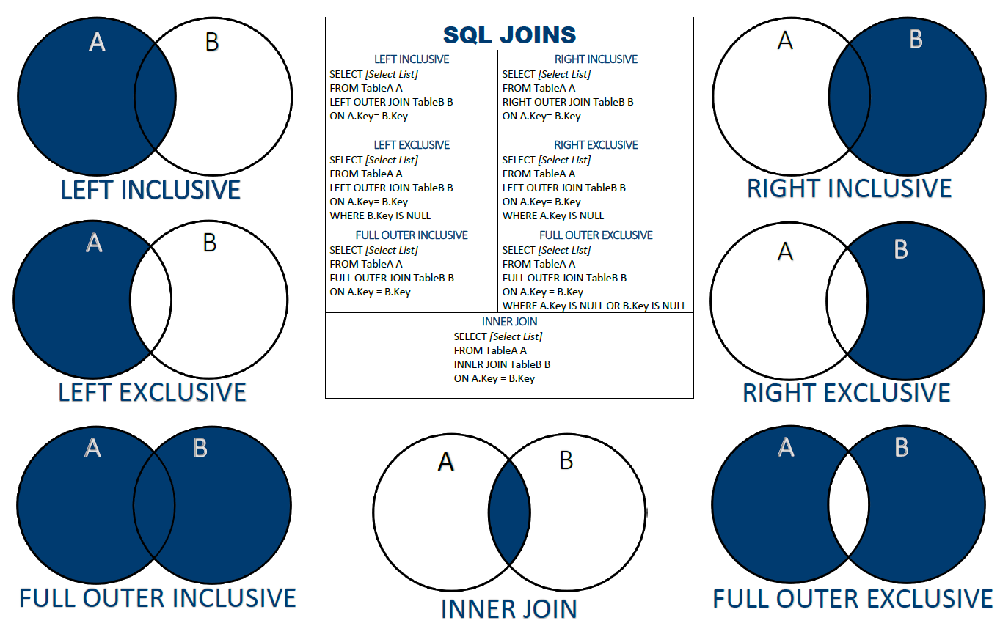

#### 1. Importar Bibliotecas

In [1]:
import sqlite3
import pandas as pd

#### 2. Criar conexão com banco de dados em memória

In [2]:
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

#### 3. Criar tabelas

In [3]:
# Tabela 1: Funcionarios
cursor.execute("""
CREATE TABLE Funcionarios (
id INTEGER PRIMARY KEY,
nome TEXT,
dep_id INTEGER
);
""")

# Tabela 2: Departamentos
cursor.execute("""
CREATE TABLE Departamentos (
id INTEGER PRIMARY KEY,
departamento TEXT
);
""")

#### 4. Inserir dados nas tabelas

In [4]:
# Inserir dados em Funcionarios
cursor.executemany("INSERT INTO Funcionarios VALUES (?, ?, ?)", [
(1, 'Ana', 10),
(2, 'Bruno', 20),
(3, 'Carla', None),
(4, 'Daniel', 30)
])

# Inserir dados em Departamentos
cursor.executemany("INSERT INTO Departamentos VALUES (?, ?)", [
(10, 'RH'),
(20, 'TI'),
(40, 'Marketing')
])

conn.commit()

#### 5. Visualizar tabelas

In [5]:
cursor.execute("SELECT * FROM funcionarios;")
pd.DataFrame(cursor.fetchall(), columns = ['id','nome','dep_id'])

,id,nome,dep_id
0,1,Ana,10.0
1,2,Bruno,20.0
2,3,Carla,NaN
3,4,Daniel,30.0


In [6]:
cursor.execute("SELECT * FROM departamentos;")
pd.DataFrame(cursor.fetchall(), columns = ['id','departamento'])

,id,departamento
0,10,RH
1,20,TI
2,40,Marketing


### INNER JOIN:

`INNER JOIN` é um formato comum de join, que retorna dados apenas quando as duas tabelas tem chaves correspondentes na cláusula ON do join.

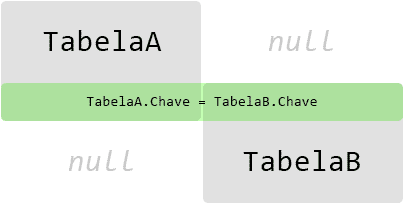

In [7]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
INNER JOIN Departamentos d
ON f.dep_id = d.id;
''')
inner_join_result = cursor.fetchall()
pd.DataFrame(inner_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI


### LEFT JOIN

`LEFT OUTER JOIN` ou simplesmente `LEFT JOIN` é um dos formatos mais usados de join, que retorna a Tabela A inteira e apenas os registros que coincidirem com a igualdade do join na Tabela B (ou campos nulos para os campos sem correspondência).

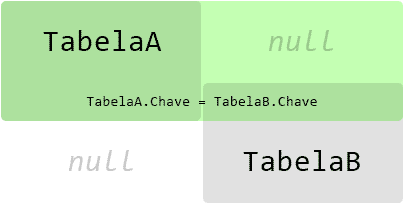

In [8]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
LEFT JOIN Departamentos d
ON f.dep_id = d.id;
''')
left_join_result = cursor.fetchall()
pd.DataFrame(left_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI
2,Carla,NaN
3,Daniel,NaN


### RIGHT JOIN

`RIGHT OUTER JOIN` ou simplesmente `RIGHT JOIN` segue o mesmo raciocínio do LEFT JOIN, mas se aplicando à tabela B em vez da A:

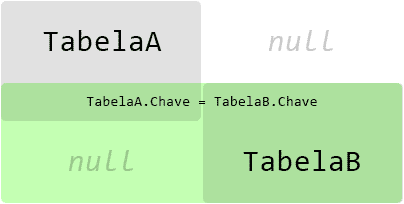

In [9]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Departamentos d
LEFT JOIN Funcionarios f
ON f.dep_id = d.id;
''')
right_join_result = cursor.fetchall()
pd.DataFrame(right_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI
2,NaN,Marketing


### FULL JOIN 

Conhecida como `OUTER JOIN` ou simplesmente `FULL JOIN`, este retorna todos os registros de ambas as tabelas.

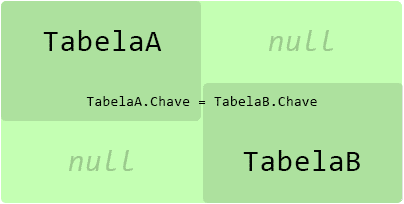

Obs: SQLite não suporta FULL JOIN diretamente. Então simulamos com UNION de LEFT JOIN e RIGHT JOIN.

In [10]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
LEFT JOIN Departamentos d ON f.dep_id = d.id
UNION
SELECT f.nome, d.departamento
FROM Departamentos d
LEFT JOIN Funcionarios f ON f.dep_id = d.id;
''')
full_join_result = cursor.fetchall()
pd.DataFrame(full_join_result, columns=["nome", "departamento"])

,nome,departamento
0,NaN,Marketing
1,Ana,RH
2,Bruno,TI
3,Carla,NaN
4,Daniel,NaN


### CROSS JOIN: retorna o produto cartesiano entre as duas tabelas.

Basicamente é o produto cartesiano entre as duas tabelas. Para cada linha de Tabela A, são retornadas todas as linhas de Tabela B.

É mais fácil entender o CROSS JOIN como um "Join sem cláusula ON", ou seja, todas as combinações de linhas de A e B são devolvidas. Inclusive, se você fizer um CROSS JOIN com cláusula ON, ele "vira" um mero INNER JOIN.

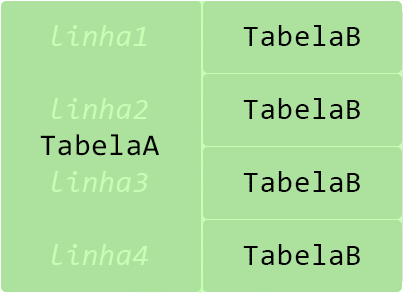

In [11]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
CROSS JOIN Departamentos d;
''')
cross_join_result = cursor.fetchall()
pd.DataFrame(cross_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Ana,TI
2,Ana,Marketing
3,Bruno,RH
4,Bruno,TI
5,Bruno,Marketing
6,Carla,RH
7,Carla,TI
8,Carla,Marketing
9,Daniel,RH


## 9 Forma Normal Fn

# Normalização de Banco de Dados (1FN a 6FN)
Este notebook demonstra passo a passo a normalização de um conjunto de dados fictício de pedidos, clientes e produtos.

Vamos evoluir desde uma tabela não normalizada até a 6ª Forma Normal (6FN), mostrando exemplos práticos em Python com pandas.

In [1]:
import pandas as pd
import numpy as np

def show(title, df):
    print(f"\n=== {title} ===")
    display(df)

## Tabela inicial (não normalizada)
A tabela possui múltiplos produtos em colunas (`produto1`, `produto2`), bem como telefones e e-mails em formato de lista separada por ponto e vírgula.

In [2]:

pedidos_raw = pd.DataFrame([
    {
        "pedido_id": 1,
        "data_pedido": "2025-09-20",
        "cliente_nome": "Ana Silva",
        "cliente_endereco": "Rua A, 123",
        "cidade": "São Paulo",
        "estado": "SP",
        "telefones": "11-99999-0001;11-99999-0002",
        "emails": "ana@example.com;ana.silva@empresa.com",
        "produto1": "Lápis",
        "preco1": 1.50,
        "produto2": "Caderno",
        "preco2": 10.00
    },
    {
        "pedido_id": 2,
        "data_pedido": "2025-09-21",
        "cliente_nome": "João Souza",
        "cliente_endereco": "Av. B, 456",
        "cidade": "Campinas",
        "estado": "SP",
        "telefones": "19-98888-1111",
        "emails": "joao@example.com",
        "produto1": "Caneta",
        "preco1": 2.00,
        "produto2": "Caderno",
        "preco2": 10.00
    },
    {
        "pedido_id": 3,
        "data_pedido": "2025-09-22",
        "cliente_nome": "Maria Costa",
        "cliente_endereco": "Rua C, 789",
        "cidade": "São Paulo",
        "estado": "SP",
        "telefones": "11-97777-3333;11-96666-4444",
        "emails": "maria@example.com",
        "produto1": "Borracha",
        "preco1": 0.75,
        "produto2": None,
        "preco2": None
    }
])
show("Tabela inicial (não normalizada)", pedidos_raw)


=== Tabela inicial (não normalizada) ===


,pedido_id,data_pedido,cliente_nome,cliente_endereco,cidade,estado,telefones,emails,produto1,preco1,produto2,preco2
0,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Lápis,1.50,Caderno,10.0
1,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caneta,2.00,Caderno,10.0
2,3,2025-09-22,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com,Borracha,0.75,NaN,NaN


## Primeira Forma Normal (1FN)
- Remove grupos repetidos (produto1, produto2)
- Cria uma linha por produto do pedido

In [3]:
rows = []
product_pairs = [(1, 'produto1', 'preco1'), (2, 'produto2', 'preco2')]
for _, r in pedidos_raw.iterrows():
    for _, produto_col, preco_col in product_pairs:
        produto = r[produto_col]
        preco = r[preco_col]
        if pd.notna(produto):
            rows.append({
                "pedido_id": r["pedido_id"],
                "data_pedido": r["data_pedido"],
                "cliente_nome": r["cliente_nome"],
                "cliente_endereco": r["cliente_endereco"],
                "cidade": r["cidade"],
                "estado": r["estado"],
                "telefones": r["telefones"],
                "emails": r["emails"],
                "produto": produto,
                "preco": preco
            })
pedidos_1fn = pd.DataFrame(rows)
show("Pedidos (1FN)", pedidos_1fn)


=== Pedidos (1FN) ===


,pedido_id,data_pedido,cliente_nome,cliente_endereco,cidade,estado,telefones,emails,produto,preco
0,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Lápis,1.50
1,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Caderno,10.00
2,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caneta,2.00
3,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caderno,10.00
4,3,2025-09-22,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com,Borracha,0.75


## Segunda Forma Normal (2FN)
- Elimina dependência parcial da chave composta (pedido_id, produto).
- Criamos tabelas: `Clientes`, `Pedidos`, `Itens_Pedido`. 

In [4]:
clientes = pedidos_1fn[["cliente_nome","cliente_endereco","cidade","estado","telefones","emails"]].drop_duplicates().reset_index(drop=True)
clientes = clientes.reset_index().rename(columns={"index":"cliente_id"})
clientes["cliente_id"] = clientes["cliente_id"] + 1
clientes = clientes[["cliente_id","cliente_nome","cliente_endereco","cidade","estado","telefones","emails"]]
show("Clientes (2FN)", clientes)

pedidos = pedidos_1fn[["pedido_id","data_pedido","cliente_nome","cliente_endereco"]].drop_duplicates().reset_index(drop=True)
pedidos = pedidos.merge(clientes[["cliente_id","cliente_nome","cliente_endereco"]], on=["cliente_nome","cliente_endereco"], how="left")
pedidos = pedidos[["pedido_id","data_pedido","cliente_id"]]
show("Pedidos (2FN)", pedidos)

itens_pedido = pedidos_1fn[["pedido_id","produto","preco"]].reset_index(drop=True)
show("Itens_Pedido (2FN)", itens_pedido)


=== Clientes (2FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade,estado,telefones,emails
0,1,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com
1,2,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com
2,3,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com



=== Pedidos (2FN) ===


,pedido_id,data_pedido,cliente_id
0,1,2025-09-20,1
1,2,2025-09-21,2
2,3,2025-09-22,3



=== Itens_Pedido (2FN) ===


,pedido_id,produto,preco
0,1,Lápis,1.50
1,1,Caderno,10.00
2,2,Caneta,2.00
3,2,Caderno,10.00
4,3,Borracha,0.75


## Terceira Forma Normal (3FN)
- Remove dependências transitivas (`cidade → estado`).
- Criamos tabela `Cidades` e referenciamos por `cidade_id`. 

In [5]:
cidades = clientes[["cidade","estado"]].drop_duplicates().reset_index(drop=True)
cidades = cidades.reset_index().rename(columns={"index":"cidade_id"})
cidades["cidade_id"] = cidades["cidade_id"] + 1
cidades = cidades[["cidade_id","cidade","estado"]]
show("Cidades (3FN)", cidades)

clientes_3fn = clientes.merge(cidades, on=["cidade","estado"], how="left")
clientes_3fn = clientes_3fn[["cliente_id","cliente_nome","cliente_endereco","cidade_id","telefones","emails"]]
show("Clientes (após 3FN)", clientes_3fn)


=== Cidades (3FN) ===


,cidade_id,cidade,estado
0,1,São Paulo,SP
1,2,Campinas,SP



=== Clientes (após 3FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade_id,telefones,emails
0,1,Ana Silva,"Rua A, 123",1,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com
1,2,João Souza,"Av. B, 456",2,19-98888-1111,joao@example.com
2,3,Maria Costa,"Rua C, 789",1,11-97777-3333;11-96666-4444,maria@example.com


## Forma Normal de Boyce-Codd (BCNF)
- Elimina dependências funcionais anômalas.
- Exemplo: `produto → preco`. Criamos tabela `Produtos`. 

In [6]:
produtos = itens_pedido[["produto","preco"]].drop_duplicates().reset_index(drop=True)
produtos = produtos.reset_index().rename(columns={"index":"produto_id"})
produtos["produto_id"] = produtos["produto_id"] + 1
produtos = produtos[["produto_id","produto","preco"]].rename(columns={"preco":"preco_unitario"})
show("Produtos (BCNF)", produtos)

itens_pedido_bcnf = itens_pedido.merge(produtos[["produto_id","produto"]], on="produto", how="left")
itens_pedido_bcnf = itens_pedido_bcnf[["pedido_id","produto_id"]]
show("Itens_Pedido (após BCNF)", itens_pedido_bcnf)


=== Produtos (BCNF) ===


,produto_id,produto,preco_unitario
0,1,Lápis,1.50
1,2,Caderno,10.00
2,3,Caneta,2.00
3,4,Borracha,0.75



=== Itens_Pedido (após BCNF) ===


,pedido_id,produto_id
0,1,1
1,1,2
2,2,3
3,2,2
4,3,4


## Quarta Forma Normal (4FN)
- Elimina dependências multivaloradas.
- Telefones e Emails de clientes são separados em tabelas próprias. 

In [7]:
telefones_rows = []
for _, r in clientes_3fn.iterrows():
    cliente_id = r["cliente_id"]
    telefones_raw = r["telefones"]
    if pd.notna(telefones_raw):
        for t in str(telefones_raw).split(";"):
            t = t.strip()
            if t:
                telefones_rows.append({"cliente_id": cliente_id, "telefone": t})
telefones = pd.DataFrame(telefones_rows)
show("Telefones (4FN)", telefones)

emails_rows = []
for _, r in clientes_3fn.iterrows():
    cliente_id = r["cliente_id"]
    emails_raw = r["emails"]
    if pd.notna(emails_raw):
        for e in str(emails_raw).split(";"):
            e = e.strip()
            if e:
                emails_rows.append({"cliente_id": cliente_id, "email": e})
emails = pd.DataFrame(emails_rows)
show("Emails (4FN)", emails)

clientes_4fn = clientes_3fn[["cliente_id","cliente_nome","cliente_endereco","cidade_id"]]
show("Clientes (após 4FN)", clientes_4fn)


=== Telefones (4FN) ===


,cliente_id,telefone
0,1,11-99999-0001
1,1,11-99999-0002
2,2,19-98888-1111
3,3,11-97777-3333
4,3,11-96666-4444



=== Emails (4FN) ===


,cliente_id,email
0,1,ana@example.com
1,1,ana.silva@empresa.com
2,2,joao@example.com
3,3,maria@example.com



=== Clientes (após 4FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade_id
0,1,Ana Silva,"Rua A, 123",1
1,2,João Souza,"Av. B, 456",2
2,3,Maria Costa,"Rua C, 789",1


## Quinta Forma Normal (5FN)
- Elimina dependências de junção.
- Exemplo com relação ternária (Fornecedor, Produto, Região). 

In [8]:
fornece = pd.DataFrame([
    {"fornecedor":"F1","produto":"P1","regiao":"Norte"},
    {"fornecedor":"F1","produto":"P2","regiao":"Norte"},
    {"fornecedor":"F2","produto":"P1","regiao":"Sul"},
    {"fornecedor":"F2","produto":"P2","regiao":"Sul"},
])
show("R - Fornece (tripla)", fornece)

fornece_fp = fornece[["fornecedor","produto"]].drop_duplicates().reset_index(drop=True)
fornece_fr = fornece[["fornecedor","regiao"]].drop_duplicates().reset_index(drop=True)
fornece_pr = fornece[["produto","regiao"]].drop_duplicates().reset_index(drop=True)
show("Fornece_FP", fornece_fp)
show("Fornece_FR", fornece_fr)
show("Fornece_PR", fornece_pr)

# Reconstrução por junção
temp = fornece_fp.merge(fornece_pr, on="produto")
recon = temp.merge(fornece_fr, on="fornecedor", how="left", suffixes=('_pr','_fr'))
reg_cols = [c for c in recon.columns if 'regiao' in c]
if reg_cols:
    recon['regiao'] = recon[reg_cols[0]]
recon = recon[['fornecedor','produto','regiao']].drop_duplicates().reset_index(drop=True)
show("Reconstrução de R", recon)


=== R - Fornece (tripla) ===


,fornecedor,produto,regiao
0,F1,P1,Norte
1,F1,P2,Norte
2,F2,P1,Sul
3,F2,P2,Sul



=== Fornece_FP ===


,fornecedor,produto
0,F1,P1
1,F1,P2
2,F2,P1
3,F2,P2



=== Fornece_FR ===


,fornecedor,regiao
0,F1,Norte
1,F2,Sul



=== Fornece_PR ===


,produto,regiao
0,P1,Norte
1,P2,Norte
2,P1,Sul
3,P2,Sul



=== Reconstrução de R ===


,fornecedor,produto,regiao
0,F1,P1,Norte
1,F1,P1,Sul
2,F1,P2,Norte
3,F1,P2,Sul
4,F2,P1,Norte
5,F2,P1,Sul
6,F2,P2,Norte
7,F2,P2,Sul


## Sexta Forma Normal (6FN)
- Decomposição extrema, geralmente usada em cenários temporais.
- Exemplo: histórico de preços de produtos em períodos distintos.

In [9]:
prod_precos = pd.DataFrame([
    {"produto_id": 1, "start":"2025-01-01", "end":"2025-06-30", "preco": 1.40},
    {"produto_id": 1, "start":"2025-07-01", "end": None,       "preco": 1.50},
    {"produto_id": 2, "start":"2025-01-01", "end": None,       "preco": 10.00},
])
show("Produto_Precos (6FN - temporal)", prod_precos)


=== Produto_Precos (6FN - temporal) ===


,produto_id,start,end,preco
0,1,2025-01-01,2025-06-30,1.4
1,1,2025-07-01,NaN,1.5
2,2,2025-01-01,NaN,10.0


## Resumo
- **1FN** → remove grupos repetidos
- **2FN** → remove dependência parcial
- **3FN** → remove dependência transitiva
- **BCNF** → remove dependências funcionais anômalas
- **4FN** → remove dependências multivaloradas
- **5FN** → remove dependências de junção
- **6FN** → granularidade máxima (ex.: temporal)

## 10 Introduçãomysql

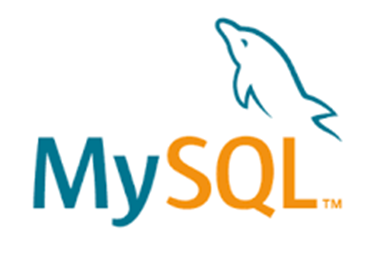

# Introdução ao MySQL com Python

#### Passo 1: Instalar bibliotecas

In [22]:
#%pip install pymysql

#### Passo 2: Importar bibliotecas

In [23]:
import pymysql

#### Passo 3: Conectar no MySQL

In [24]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4:  Criar banco

In [25]:
cursor.execute("CREATE DATABASE IF NOT EXISTS mohammadteste")
print("Banco criado com sucesso!")

Banco criado com sucesso!


#### Passo 5: Conferir no Workbench
- Abra o **MySQL Workbench**
- No painel esquerdo (Schemas), clique em Refresh
- Você deve ver o banco `meubanco`

#### Passo 6: Verificar conexão

In [26]:
# Encerrar conexão com banco de dados
conn.close()

In [27]:
# Testa se a conexão está ativa
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Banco de dados desconectado


In [28]:
# Criar conexão 
if not conn.open:
    conn.ping(reconnect=True)

C:\Users\41228408807\AppData\Local\Temp\ipykernel_31156\628939375.py:3: DeprecationWarning: The 'reconnect' argument is deprecated. Create a new connection if you want to reconnect.
  conn.ping(reconnect=True)


In [29]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

(None,)

In [30]:
# Verificar bancos existentes
cursor.execute("SHOW DATABASES;")
cursor.fetchall()

(('information_schema',),
 ('mohammadteste',),
 ('mysql',),
 ('performance_schema',),
 ('sakila',),
 ('sys',),
 ('world',))

In [31]:
# Conectar ao banco existente
cursor.execute("USE mohammadteste")

0

In [32]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('mohammadteste',)

In [33]:
# Encerrar conexão com banco de dados
conn.close()

In [34]:
# Forma completa para conectar
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="mohammadteste"  
)
cursor = conn.cursor()

In [35]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('mohammadteste',)

#### Passo 7: Criar tabela

In [36]:
# Conecta com banco de dados
cursor = conn.cursor()

# Cria Tabela
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255),
    preco DECIMAL(10,2),
    categoria VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


#### Passo 8: Inserir dados

In [37]:
dados = [
    ("Notebook Dell", 3500.00, "Eletrônicos"),
    ("Smartphone Samsung", 2100.00, "Eletrônicos"),
    ("Livro Python", 89.90, "Livros"),
    ("Monitor LG", 899.00, "Eletrônicos")
]
cursor.executemany("INSERT INTO produtos (titulo, preco, categoria) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [38]:
# Encerrar conexão com banco de dados
conn.close()

#### Passo 9: Visualizar no Workbench
- Clique em `meubanco` → abra a aba de queries.

Rode: `SELECT * FROM produtos;`

#### Passo 9: inserindo novos dados pelo Workbench
Ainda no Workbench, rode:

`INSERT INTO produtos (titulo, preco, categoria)`

`VALUES ("Mouse Gamer", 199.90, "Eletrônicos");`

#### Passo 10: Consulta de teste no Python

In [39]:
# Conecta com Banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="mohammadteste"  
)
cursor = conn.cursor()

In [40]:
cursor.execute("SELECT * FROM produtos")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Monitor LG', Decimal('899.00'), 'Eletrônicos')
(5, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(6, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(7, 'Livro Python', Decimal('89.90'), 'Livros')
(8, 'Monitor LG', Decimal('899.00'), 'Eletrônicos')


# Neste exercício exploramos Python e Workbench no mesmo banco MySQL
- O banco é o mesmo: Python e Workbench são apenas **duas portas de acesso**.
- Você pode **criar, inserir e consultar** dados em um ambiente e ver os resultados no outro.
- Isso mostra a importância de **separar a camada de aplicação (Python) da camada de dados (MySQL).**

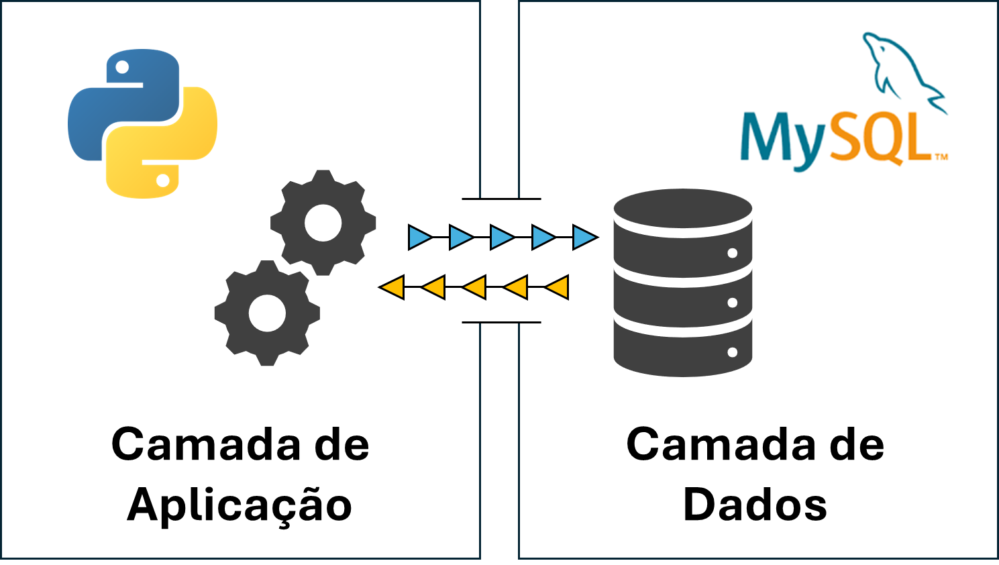

### Onde o banco de dados fica salvo? 

- Diferente do **SQLite** em que o banco é criado como **um arquivo** `.db` **no diretório atual** (mesma pasta do notebook/script)
- O **MySQL guarda os bancos em uma pasta interna do servido**. Geralmente em:
 
  `C:\ProgramData\MySQL\MySQL Server 8.0\Data\`
  
 **Atenção:** 
 - Essa pasta é oculta, tem que habilitar **Mostrar arquivos ocultos**
 - Você **não manipula diretamente esses arquivos**, sempre acessa via o servidor MySQL (Workbench, Python, terminal).

### Apagar o banco de dados

- Atenção! Esse comando apaga todo o banco de dados (tabelas, dados, índices, etc.).

- **Não há undo** – depois de rodar, não tem como recuperar a não ser que você tenha backup.

In [41]:
# Exclui banco de dados
cursor.execute("DROP DATABASE IF EXISTS meubanco")

# Salvar. commit() grava de forma definitiva as alterações feitas no banco de dados na transação atual
conn.commit()

# Fecha o canal de envio de comandos
cursor.close()

# Encerrar conexão com banco de dados
conn.close()

---
# Exercícios de fixação

> **Orientação:** execute cada exercício em sequência. Quando necessário, confira o resultado também no MySQL Workbench.


## Exercício 1: Conexão com o MySQL

Crie uma conexão com o servidor MySQL utilizando `pymysql.connect()`. Depois:

1. crie um cursor;
2. execute `SELECT DATABASE();`;
3. imprima o resultado;
4. verifique se a conexão está ativa.

**Objetivo:** praticar conexão, cursor e execução de uma consulta simples.


In [42]:
# Ajuste a senha antes de conectar, se necessário.
conn = pymysql.connect(host="localhost", user="root", password="root")
cursor = conn.cursor()
cursor.execute("SELECT DATABASE();")
print("Banco selecionado:", cursor.fetchone()[0])
print("Conexão ativa!" if conn.open else "Conexão inativa.")

Banco selecionado: None
Conexão ativa!


## Exercício 2: Criando um banco para os exercícios

Crie um banco de dados chamado `loja_treinamento`, caso ele ainda não exista. Em seguida, selecione esse banco com o comando `USE` e confirme, por meio de `SELECT DATABASE();`, que ele está ativo.

**Objetivo:** praticar `CREATE DATABASE`, `USE` e verificação do banco selecionado.


In [43]:
cursor.execute("CREATE DATABASE IF NOT EXISTS loja_treinamento;")
cursor.execute("USE loja_treinamento;")
cursor.execute("SELECT DATABASE();")
print("Banco selecionado:", cursor.fetchone()[0])

Banco selecionado: loja_treinamento


## Exercício 3: Criando uma tabela

No banco `loja_treinamento`, crie uma tabela chamada `clientes` com a seguinte estrutura:

| Campo | Tipo | Regra |
|---|---|---|
| `id` | INT | chave primária e `AUTO_INCREMENT` |
| `nome` | VARCHAR(150) | nome do cliente |
| `cidade` | VARCHAR(100) | cidade do cliente |
| `idade` | INT | idade do cliente |

Utilize `CREATE TABLE IF NOT EXISTS`.

**Objetivo:** praticar criação de tabelas e definição de campos.


In [44]:
cursor.execute("USE loja_treinamento;")
cursor.execute("""
CREATE TABLE IF NOT EXISTS clientes (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(150) NOT NULL,
    cidade VARCHAR(100) NOT NULL,
    idade INT NOT NULL
);
""")
print("Tabela clientes criada com sucesso!")

Tabela clientes criada com sucesso!


## Exercício 4: Inserindo vários registros

Insira **pelo menos cinco clientes** na tabela `clientes`. Utilize uma lista de tuplas em Python e o método `executemany()`. Ao final, confirme a transação com `conn.commit()`.

Exemplo de estrutura dos dados:

```python
dados = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35)
]
```

Acrescente pelo menos três registros diferentes dos apresentados no exemplo.

**Objetivo:** praticar inserção em lote e persistência com `commit()`.


In [45]:
dados_clientes = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35),
    ("Beatriz", "Santos", 42),
    ("Diego", "Campinas", 24),
    ("Fernanda", "Curitiba", 31),
]
cursor.executemany(
    "INSERT INTO clientes (nome, cidade, idade) VALUES (%s, %s, %s);",
    dados_clientes
)
conn.commit()
print(f"{len(dados_clientes)} clientes cadastrados.")

5 clientes cadastrados.


## Exercício 5: Consultando os dados

Faça uma consulta que retorne **todos os registros** da tabela `clientes`. Utilize `fetchall()` e um laço `for` para imprimir cada linha separadamente.

Depois, responda observando a saída:

1. Quantos clientes foram cadastrados?
2. Qual informação aparece na primeira posição de cada tupla retornada?

**Objetivo:** praticar `SELECT`, `fetchall()` e leitura do resultado no Python.


In [46]:
cursor.execute("SELECT * FROM clientes;")
clientes = cursor.fetchall()
for cliente in clientes:
    print(cliente)
print(f"Total de clientes: {len(clientes)}")
print("A primeira informação de cada tupla é o id do cliente.")

(1, 'Ana', 'São Paulo', 28)
(2, 'Carlos', 'Campinas', 35)
(3, 'Beatriz', 'Santos', 42)
(4, 'Diego', 'Campinas', 24)
(5, 'Fernanda', 'Curitiba', 31)
Total de clientes: 5
A primeira informação de cada tupla é o id do cliente.


## Exercício 6: Consultas com filtros

Realize as seguintes consultas na tabela `clientes`:

1. exiba apenas os clientes com idade maior que 30 anos;
2. exiba apenas os clientes de uma cidade escolhida por você;
3. exiba somente as colunas `nome` e `cidade`.

Imprima os resultados de cada consulta.

**Objetivo:** praticar consultas `SELECT` com seleção de colunas e filtros.


In [47]:
# Consulta 1: clientes com mais de 30 anos.
cursor.execute("SELECT * FROM clientes WHERE idade > %s;", (30,))
print("Maiores de 30 anos:", cursor.fetchall())

# Consulta 2: clientes de Campinas.
cursor.execute("SELECT * FROM clientes WHERE cidade = %s;", ("Campinas",))
print("Clientes de Campinas:", cursor.fetchall())

# Consulta 3: somente nome e cidade.
cursor.execute("SELECT nome, cidade FROM clientes;")
print("Nome e cidade:", cursor.fetchall())

Maiores de 30 anos: ((2, 'Carlos', 'Campinas', 35), (3, 'Beatriz', 'Santos', 42), (5, 'Fernanda', 'Curitiba', 31))
Clientes de Campinas: ((2, 'Carlos', 'Campinas', 35), (4, 'Diego', 'Campinas', 24))
Nome e cidade: (('Ana', 'São Paulo'), ('Carlos', 'Campinas'), ('Beatriz', 'Santos'), ('Diego', 'Campinas'), ('Fernanda', 'Curitiba'))


## Exercício 7: Cadastro de produtos

Crie uma tabela chamada `produtos_treinamento` com os campos `id`, `titulo`, `preco` e `categoria`, seguindo a estrutura utilizada anteriormente no notebook. Depois:

1. cadastre pelo menos seis produtos de duas ou mais categorias;
2. confirme os dados com `commit()`;
3. consulte todos os produtos;
4. mostre apenas os produtos de uma categoria escolhida por você.

**Objetivo:** integrar criação de tabela, inserção e consulta em uma única atividade.


In [48]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos_treinamento (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255) NOT NULL,
    preco DECIMAL(10, 2) NOT NULL,
    categoria VARCHAR(100) NOT NULL
);
""")
dados_produtos = [
    ("Notebook", 3500.00, "Eletrônicos"),
    ("Mouse", 89.90, "Eletrônicos"),
    ("Teclado", 159.90, "Eletrônicos"),
    ("Livro de Python", 79.90, "Livros"),
    ("Livro de SQL", 69.90, "Livros"),
    ("Livro de Dados", 99.90, "Livros"),
]
cursor.executemany(
    "INSERT INTO produtos_treinamento (titulo, preco, categoria) VALUES (%s, %s, %s);",
    dados_produtos
)
conn.commit()

cursor.execute("SELECT * FROM produtos_treinamento;")
print("Todos os produtos:", cursor.fetchall())
cursor.execute("SELECT * FROM produtos_treinamento WHERE categoria = %s;", ("Livros",))
print("Produtos da categoria Livros:", cursor.fetchall())

Todos os produtos: ((1, 'Notebook', Decimal('3500.00'), 'Eletrônicos'), (2, 'Mouse', Decimal('89.90'), 'Eletrônicos'), (3, 'Teclado', Decimal('159.90'), 'Eletrônicos'), (4, 'Livro de Python', Decimal('79.90'), 'Livros'), (5, 'Livro de SQL', Decimal('69.90'), 'Livros'), (6, 'Livro de Dados', Decimal('99.90'), 'Livros'))
Produtos da categoria Livros: ((4, 'Livro de Python', Decimal('79.90'), 'Livros'), (5, 'Livro de SQL', Decimal('69.90'), 'Livros'), (6, 'Livro de Dados', Decimal('99.90'), 'Livros'))


## Exercício 8: Python e Workbench no mesmo banco

Este exercício deve ser realizado utilizando os dois ambientes.

1. Pelo **Python**, insira um novo produto em `produtos_treinamento`.
2. No **MySQL Workbench**, execute uma consulta e verifique se o produto aparece.
3. Pelo **Workbench**, insira outro produto.
4. Volte ao **Python**, execute novamente o `SELECT` e confirme se o novo registro aparece.

Ao final, explique em poucas linhas por que Python e Workbench conseguem visualizar os mesmos dados.

**Objetivo:** consolidar a diferença entre o banco de dados MySQL e as ferramentas utilizadas para acessá-lo.


**Resposta conceitual:**

Escreva aqui sua explicação.


## Desafio final

Sem copiar diretamente os exemplos anteriores, desenvolva um pequeno cadastro para um contexto de sua escolha, como **livros, alunos, filmes, veículos ou funcionários**. Sua solução deve:

1. criar uma nova tabela;
2. possuir uma chave primária com `AUTO_INCREMENT`;
3. possuir pelo menos três atributos além do `id`;
4. inserir pelo menos cinco registros com `executemany()`;
5. executar uma consulta que mostre todos os registros;
6. executar pelo menos uma consulta com filtro;
7. utilizar `commit()` após as inserções;
8. fechar o cursor e a conexão ao final.

**Objetivo:** aplicar de forma integrada os conceitos trabalhados no notebook.


## 11 Procedures Functions Triggers

# Procedures, Functions e Triggers
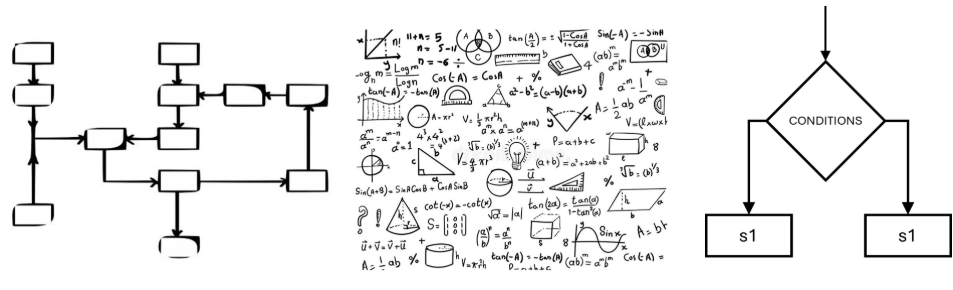

## Objetivos
- Criar e usar **Stored Procedures**, **Functions** e **Triggers** no **MySQL**.
- Conectar ao MySQL usando **PyMySQL** a partir do **Python**.
- Registrar e analisar **auditoria** de alterações (triggers).
- Visualizar resultados com **pandas** e **matplotlib**.

#### Passo 1: Importar bibliotecas

In [2]:
import os
import pymysql
import pandas as pd
import matplotlib.pyplot as plt

#### Passo 2: Conexão ao MySQL (criando `conn` e `cursor`)

In [3]:
# 1. Criar conexão com o servidor MySQL (sem selecionar banco ainda)
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root", 
    autocommit=False  # manteremos controle explícito de commit
)
cursor = conn.cursor()
print("Conexão criada com sucesso!")

Conexão criada com sucesso!


#### Passo 3: Criar o banco de dados e selecioná-lo
**O que faremos agora:**  
1. Criar o banco `empresa_dados` (se não existir).  
2. Selecionar o banco com `USE`.  
3. Conferir qual banco está em uso.

In [4]:
cursor.execute('DROP DATABASE IF EXISTS pft') # Remove banco das aulas passadas
cursor.execute('CREATE DATABASE IF NOT EXISTS pft')
print('Banco criado')

Banco criado


In [5]:
cursor.execute('USE pft')

0

#### Passo 4: Criar tabelas

#### 4.1) Tabela `departamentos`
Campos principais:  
- `id` (chave primária)  
- `nome` (nome do departamento)

In [6]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL
);
""")
conn.commit()
print("Tabela 'departamentos' criada com sucesso!")

Tabela 'departamentos' criada com sucesso!


#### 4.2) Tabela `funcionarios`
Campos principais:  
- `id`, `nome`, `salario`, `dept_id` (chave estrangeira para `departamentos`).

In [7]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    salario DECIMAL(10,2) NOT NULL,
    dept_id INT,
    FOREIGN KEY (dept_id) REFERENCES departamentos(id)
);
""")
conn.commit()
print("Tabela 'funcionarios' criada com sucesso!")

Tabela 'funcionarios' criada com sucesso!


#### 4.3) Tabela `auditoria_salarios`
Finalidade: armazenar o **histórico** de alterações de salário para cada funcionário.

In [8]:
#cursor.execute('DROP 
cursor.execute("""
CREATE TABLE IF NOT EXISTS auditoria_salarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    funcionario_id INT,
    salario_antigo DECIMAL(10,2),
    salario_novo DECIMAL(10,2),
    data_alteracao TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
""")
conn.commit()
print("Tabela 'auditoria_salarios' criada com sucesso!")

Tabela 'auditoria_salarios' criada com sucesso!



## 5) Inserir dados de exemplo
**O que faremos agora:**  
- Inserir alguns departamentos e funcionários para podermos testar nossas rotinas.


In [9]:
departamentos = [("Dados",),("TI",),("Financeiro",),("RH",)]
cursor.executemany('INSERT INTO departamentos (nome) VALUES (%s)',departamentos)
conn.commit()

In [10]:
funcionarios = [
    ("Sandro", 15000, 1),
    ("Ramon", 7500, 2),
    ("Matheus", 9000, 3),
    ("Rafael", 2500, 1),
    ("Arnon", 25000, 4)
]
cursor.executemany('INSERT INTO funcionarios (nome, salario, dept_id) VALUES (%s,%s,%s)',funcionarios)
conn.commit()


### 5.1) Visualizar os dados atuais dos funcionários
**O que faremos agora:**  
- Executar um `SELECT` e visualizar o resultado em um DataFrame do `pandas`.


In [11]:
cursor.execute('SELECT * FROM funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,15000.00,1
1,2,Ramon,7500.00,2
2,3,Matheus,9000.00,3
3,4,Rafael,2500.00,1
4,5,Arnon,25000.00,4



## 6) Stored Procedures — exemplos práticos
As **procedures** são rotinas armazenadas que executam tarefas no servidor MySQL.



### 6.1) Procedure `listar_funcionarios()`
**Objetivo:** retornar todos os funcionários.  
> **Importante:** no MySQL Workbench usa-se `DELIMITER`, mas aqui estamos executando via driver Python, que aceita o bloco diretamente.


In [12]:
cursor.execute('DROP PROCEDURE IF EXISTS listar_funcionarios;')
cursor.execute("""
CREATE PROCEDURE listar_funcionarios()
BEGIN
    SELECT * FROM funcionarios ORDER BY id;
END;
""")
conn.commit()              

In [13]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,15000.00,1
1,2,Ramon,7500.00,2
2,3,Matheus,9000.00,3
3,4,Rafael,2500.00,1
4,5,Arnon,25000.00,4



### 6.2) Procedure `funcionarios_por_departamento(IN p_dept INT)`
**Objetivo:** listar funcionários de um departamento específico, com nome do departamento.


In [14]:
cursor.execute("""
CREATE PROCEDURE funcionarios_por_departamentos(IN p_dept INT)
BEGIN
    SELECT f.id, f.nome, f.salario, d.nome AS departamento
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    WHERE f.dept_id = p_dept
    ORDER BY f.salario DESC;
END;
""")
conn.commit()

In [15]:
args = (4,)
cursor.callproc('funcionarios_por_departamentos',args)
cursor.fetchall()

((5, 'Arnon', Decimal('25000.00'), 'RH'),)


### 6.3) Procedure `reajuste_salario(IN p_fator DECIMAL)`
**Objetivo:** multiplicar os salários pelo fator informado (ex.: `1.10` = +10%).


In [16]:
cursor.execute('DROP PROCEDURE IF EXISTS reajuste_salario;')
cursor.execute("""
CREATE PROCEDURE reajuste_salario(IN p_fator DECIMAL(5,4))
BEGIN
    UPDATE funcionarios SET salario = ROUND(salario * p_fator, 2);
END;
""")
conn.commit()

In [17]:
base = (1.10,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [18]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,16500.00,1
1,2,Ramon,8250.00,2
2,3,Matheus,9900.00,3
3,4,Rafael,2750.00,1
4,5,Arnon,27500.00,4



## 7) Functions — cálculos reutilizáveis
As **functions** retornam **um valor** e podem ser usadas em `SELECT`, `WHERE`, `ORDER BY` etc.



### 7.1) Função `calcular_bonus(p_salario)`
**Objetivo:** retornar 15% do salário.


In [19]:
cursor.execute('DROP FUNCTION IF EXISTS calcular_bonus;')
cursor.execute("""
CREATE FUNCTION calcular_bonus(p_salario DECIMAL(10,2)) RETURNS DECIMAL(10,2)
DETERMINISTIC
BEGIN
    DECLARE v_bonus DECIMAL(10,2);
    SET v_bonus = ROUND(p_salario * 0.15, 2);
    RETURN v_bonus;
END;
""")
conn.commit()

In [20]:
cursor.execute("""SELECT nome, salario, calcular_bonus(salario)
AS bonus FROM funcionarios ORDER BY salario DESC;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Bônus'])

,Nome,Salário,Bônus
0,Arnon,27500.00,4125.00
1,Sandro,16500.00,2475.00
2,Matheus,9900.00,1485.00
3,Ramon,8250.00,1237.50
4,Rafael,2750.00,412.50



### 7.2) Função `classificar_salario(p_valor)`
**Objetivo:** classificar em **Baixo**, **Médio** ou **Alto**.


In [21]:
cursor.execute('DROP FUNCTION IF EXISTS classificar_salario;')
cursor.execute("""
CREATE FUNCTION classificar_salario(p_valor DECIMAL(10,2)) RETURNS VARCHAR(20)
DETERMINISTIC
BEGIN
    DECLARE v_cat VARCHAR(20);
    IF p_valor < 3000 THEN
        SET v_cat = 'Baixo';
    ELSEIF p_valor BETWEEN 3000 AND 15000 THEN
        SET v_cat = 'Médio';
    ELSE 
        SET v_cat = 'Alto';
    END IF;
    RETURN v_cat;
END;
""")
conn.commit()

In [22]:
cursor.execute("""SELECT nome, salario, classificar_salario(salario)
AS faixa FROM funcionarios ORDER BY salario;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Faixa'])

,Nome,Salário,Faixa
0,Rafael,2750.00,Baixo
1,Ramon,8250.00,Médio
2,Matheus,9900.00,Médio
3,Sandro,16500.00,Alto
4,Arnon,27500.00,Alto



## 8) Triggers — auditoria e validação
As **triggers** reagem automaticamente a eventos (INSERT/UPDATE/DELETE).



### 8.1) Trigger de auditoria (após UPDATE)
**Objetivo:** quando o salário mudar, registrar no log `auditoria_salarios`.


In [23]:
cursor.execute('DROP TRIGGER IF EXISTS trg_auditar_salario')
cursor.execute("""
CREATE TRIGGER trg_auditar_salario
AFTER UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF OLD.salario <> NEW.salario THEN
        INSERT INTO auditoria_salarios(funcionario_id, salario_antigo, salario_novo)
        VALUES (OLD.id, OLD.salario, NEW.salario);
    END IF;
END;
""")
conn.commit()


### 8.2) Trigger de validação (antes do UPDATE)
**Objetivo:** bloquear aumentos **maiores que 50%**.


In [24]:
# SIGNAL SQLSTATE '45000' lança erro manualmente
# 45000 é um código genérico usado para indicar que ocorreu um erro definido pelo usuário
cursor.execute('DROP TRIGGER IF EXISTS trg_validar_reajuste;')
cursor.execute("""
CREATE TRIGGER trg_validar_reajuste
BEFORE UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF NEW.salario > OLD.salario * 1.5 THEN
        SIGNAL SQLSTATE '45000' SET MESSAGE_TEXT = 'Aumento acima de 50% - não permitido';
    END IF;
END;
""")
conn.commit()


## 9) Testes dos mecanismos (reajuste + auditoria + validação)
**O que faremos agora:**  
1. Aplicar um reajuste **de 5%** usando a procedure.  
2. Conferir os registros de **auditoria**.  
3. Testar um aumento proibido (**> 50%**) e ver a mensagem de erro.


In [25]:
base = (1.05,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [26]:
cursor.execute('SELECT * FROM auditoria_salarios ORDER BY id;')
columns= ['id','funcionario_id', 'salario_antigo', 'salario_novo','Data da modificação']
pd.DataFrame(cursor.fetchall(), columns= columns)

,id,funcionario_id,salario_antigo,salario_novo,Data da modificação
0,1,1,16500.00,17325.00,2026-11-09 21:45:52
1,2,2,8250.00,8662.50,2026-11-09 21:45:52
2,3,3,9900.00,10395.00,2026-11-09 21:45:52
3,4,4,2750.00,2887.50,2026-11-09 21:45:52
4,5,5,27500.00,28875.00,2026-11-09 21:45:52


In [27]:
try:
    cursor.execute('UPDATE funcionarios SET salario = salario * 1.40 WHERE id = 2;')
    conn.commit()
    print('Atualização aplicada com sucesso')
except Exception as e:
    conn.rollback()
    print('Erro esperado  da Trigger:', e)

Atualização aplicada com sucesso



## 10) Visualizações com `pandas` + `matplotlib`
Vamos criar três gráficos simples para comunicar resultados:
1. **Barras:** alterações por funcionário.  
2. **Linha:** alterações por dia.  
3. **Barras:** média salarial por departamento.


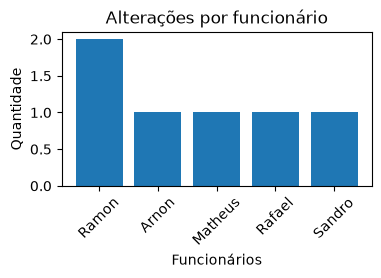

In [28]:
cursor.execute("""
    SELECT f.nome, COUNT(a.id) AS qtd
    FROM funcionarios f
    LEFT JOIN auditoria_salarios a ON a.funcionario_id = f.id
    GROUP BY f.id, f.nome
    ORDER BY qtd DESC, f.nome
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['nome','qtd'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['nome'], df_qtd['qtd'])
plt.title('Alterações por funcionário')
plt.xlabel('Funcionários')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

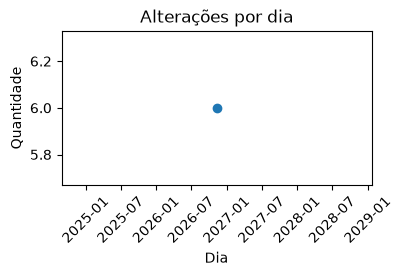

In [29]:
cursor.execute("""
    SELECT DATE(data_alteracao) AS dia, COUNT(*) AS qtd
    FROM auditoria_salarios
    GROUP BY DATE(data_alteracao)
    ORDER BY dia
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['dia','qtd'])

plt.figure(figsize=(4,2))
plt.plot(df_qtd['dia'], df_qtd['qtd'], marker = 'o')
plt.title('Alterações por dia')
plt.xlabel('Dia')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

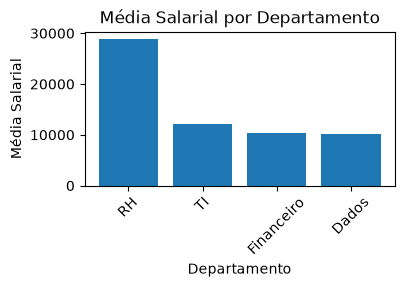

In [30]:
cursor.execute("""
    SELECT d.nome AS departamento, ROUND(AVG(f.salario),2) AS media
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    GROUP BY d.id, d.nome
    ORDER BY media DESC
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['departamento','media'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['departamento'], df_qtd['media'])
plt.title('Média Salarial por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Média Salarial')
plt.xticks(rotation = 45)
plt.show()


## 11) Exercícios propostos
1. **Procedure** `add_funcionario(IN p_nome, IN p_salario, IN p_dept)` que insere e emite `SELECT LAST_INSERT_ID()` para retornar o novo `id` ao Python.  
2. **Function** `calc_imposto(p_salario)` (10%) e consulta com salário líquido.  
3. **Trigger** que bloqueia **redução** maior que 30% do salário.  
4. **Relatório**: `nome, departamento, salario, bonus, faixa` ordenado por `bonus` (use as funções).


### Exercício 1 — Procedure add_funcionario

Crie uma procedure chamada add_funcionario que receba como entrada:
- `p_nome` (nome do funcionário)
- `p_salario` (valor do salário)
- `p_dept` (departamento)

E retorne via **OUT** o `ID` do **funcionário recém-inserido**.

In [31]:
cursor.execute('DROP PROCEDURE IF EXISTS add_funcionario')
cursor.execute("""
CREATE PROCEDURE add_funcionario(
    IN p_nome VARCHAR(100),
    IN p_salario DECIMAL(10,2),
    IN p_dept INT
)
BEGIN
    INSERT INTO funcionarios (nome, salario, dept_id)
    VALUES (p_nome, p_salario, p_dept);
    
    SELECT LAST_INSERT_ID() AS novo_id;
END
""")
conn.commit()

In [32]:
args = ["Samanta", 15000, 2]
cursor.callproc('add_funcionario',args)
conn.commit()
cursor.fetchone()

(6,)

In [33]:
cursor.execute("""
SELECT id, nome, salario, dept_id
FROM funcionarios
WHERE nome = %s
ORDER BY id DESC
LIMIT 1;
""", (args[0],))
pd.DataFrame(cursor.fetchall(), columns=["id", "Nome", "Salário", "dept_id"])


,id,Nome,Salário,dept_id
0,6,Samanta,15000.00,2


### Exercício 2 — Function calc_imposto

Crie uma função chamada `calc_imposto(p_salario)` que retorne o valor do **salário líquido**, descontando **10% de imposto**.

In [34]:
cursor.execute("DROP FUNCTION IF EXISTS calc_imposto;")
cursor.execute("""
CREATE FUNCTION calc_imposto(p_salario DECIMAL(10,2))
RETURNS DECIMAL(10,2)
DETERMINISTIC
BEGIN
    RETURN ROUND(p_salario * 0.90, 2);
END;
""")
conn.commit()


In [35]:
cursor.execute("""
SELECT nome, salario, calc_imposto(salario) AS salario_liquido
FROM funcionarios
ORDER BY id;
""")
pd.DataFrame(cursor.fetchall(), columns=["Nome", "Salário bruto", "Salário líquido"])


,Nome,Salário bruto,Salário líquido
0,Sandro,17325.00,15592.50
1,Ramon,12127.50,10914.75
2,Matheus,10395.00,9355.50
3,Rafael,2887.50,2598.75
4,Arnon,28875.00,25987.50
5,Samanta,15000.00,13500.00


### Exercício 3 — Trigger trg_validar_reducao

Crie uma trigger chamada `trg_validar_reducao` que impede reduções maiores que 30% no salário de um funcionário.

In [36]:
cursor.execute("DROP TRIGGER IF EXISTS trg_validar_reducao;")
cursor.execute("""
CREATE TRIGGER trg_validar_reducao
BEFORE UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF NEW.salario < OLD.salario * 0.70 THEN
        SIGNAL SQLSTATE '45000'
            SET MESSAGE_TEXT = 'Redução salarial maior que 30% não permitida';
    END IF;
END;
""")
conn.commit()


In [37]:
try:
    cursor.execute("UPDATE funcionarios SET salario = salario * 0.50 WHERE id = 2;")
    conn.commit()
except pymysql.MySQLError as e:
    conn.rollback()
    print("Redução bloqueada pela trigger:", e)


Redução bloqueada pela trigger: (1644, 'Redução salarial maior que 30% não permitida')


### Exercício 4 — Relatório combinado

Crie uma consulta que mostre:
- `nome`, `departamento`, `salario`,
- `bonus` (usando `calcular_bonus`),
- `faixa` (usando `classificar_salario`),
- `salario_liquido` (usando `calc_imposto`)

In [38]:
cursor.execute("""
SELECT f.nome,
       d.nome AS departamento,
       f.salario,
       calcular_bonus(f.salario) AS bonus,
       classificar_salario(f.salario) AS faixa,
       calc_imposto(f.salario) AS salario_liquido
FROM funcionarios f
LEFT JOIN departamentos d ON d.id = f.dept_id
ORDER BY bonus DESC, f.nome;
""")
pd.DataFrame(cursor.fetchall(), columns=[
    "Nome", "Departamento", "Salário", "Bônus", "Faixa", "Salário líquido"
])


,Nome,Departamento,Salário,Bônus,Faixa,Salário líquido
0,Arnon,RH,28875.00,4331.25,Alto,25987.50
1,Sandro,Dados,17325.00,2598.75,Alto,15592.50
2,Samanta,TI,15000.00,2250.00,Médio,13500.00
3,Ramon,TI,12127.50,1819.13,Médio,10914.75
4,Matheus,Financeiro,10395.00,1559.25,Médio,9355.50
5,Rafael,Dados,2887.50,433.13,Baixo,2598.75



## 12) Encerrar a conexão
**O que faremos agora:**  
- Fechar `cursor` e `conn` ao final do notebook.


In [39]:
cursor.close()
conn.close()
print("Conexão com o MySQL encerrada.")


Conexão com o MySQL encerrada.


## 12 Mysql Grant Revoke

# GRANT e REVOKE
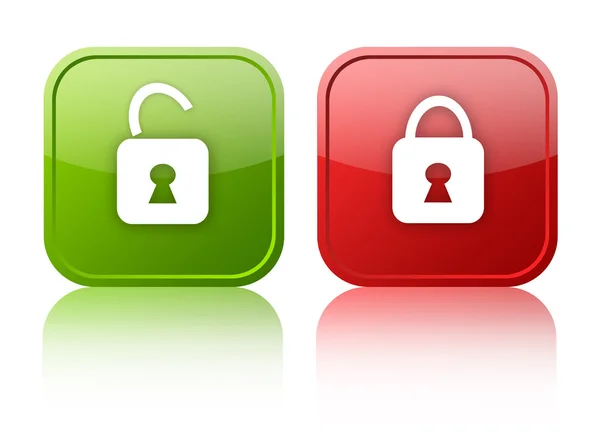

## MySQL: Gerenciamento de Permissões 

Nesta aula, vamos explorar como gerenciar permissões de usuários no MySQL usando Python, focando nas funções GRANT e REVOKE.

#### Passo 1: Instalar bibliotecas

In [1]:
#%pip install mysql
#%pip install --upgrade pandas

#### Passo 2: Importar bibliotecas

In [2]:
import pymysql
import pandas as pd

#### Passo 3: Configurações do banco de dados

In [3]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4: Criar Banco de Dados

In [4]:
cursor.execute("DROP DATABASE IF EXISTS sistema_empresa") # Remove banco de dados da aula passada
cursor.execute("CREATE DATABASE IF NOT EXISTS sistema_empresa")
cursor.execute("USE sistema_empresa")
print('Banco criado com sucesso!')

Banco criado com sucesso!


#### Passo 5: Criar Tabelas

In [5]:
# Tabela 1: Funcionários (dados sensíveis)
cursor.execute("""
CREATE TABLE funcionarios (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    cargo VARCHAR(50),
    salario DECIMAL(10,2),
    data_admissao DATE,
    departamento VARCHAR(50)
)
""")
# Tabela 2: Projetos (dados menos sensíveis)
cursor.execute("""
CREATE TABLE projetos (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome_projeto VARCHAR(100) NOT NULL,
    descricao TEXT,
    orcamento DECIMAL(12,2),
    data_inicio DATE,
    data_termino DATE,
    status VARCHAR(20)
)
""")
        
# Tabela 3: Departamentos (dados públicos)
cursor.execute("""
    CREATE TABLE departamentos (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome_departamento VARCHAR(100) NOT NULL,
    gerente VARCHAR(100),
    orcamento_anual DECIMAL(12,2),
    telefone VARCHAR(20)
)
""")

print("Tabelas criadas com sucesso")

Tabelas criadas com sucesso


#### Passo 6: Inserir dados

In [6]:
# Funcionários
funcionarios = [
    ('João Silva', 'joao.silva@empresa.com', 'Gerente de TI', 15000.00, '2020-01-15', 'TI'),
    ('Maria Santos', 'maria.santos@empresa.com', 'Analista RH', 8000.00, '2021-03-20', 'RH'),
    ('Pedro Oliveira', 'pedro.oliveira@empresa.com', 'Desenvolvedor', 12000.00, '2019-11-10', 'TI'),
    ('Ana Costa', 'ana.costa@empresa.com', 'Assistente Admin', 4500.00, '2022-06-01', 'Administrativo')
]
        
cursor.executemany(""" INSERT INTO funcionarios (nome, email, cargo, salario, data_admissao, departamento) 
VALUES (%s, %s, %s, %s, %s, %s)""", funcionarios)
        
# Projetos
projetos = [
    ('Sistema ERP', 'Desenvolvimento do sistema integrado', 500000.00, '2023-01-01', '2024-12-31', 'Em Andamento'),
    ('Site Corporativo', 'Redesign do site da empresa', 120000.00, '2023-03-15', '2023-09-30', 'Concluído'),
    ('App Mobile', 'Desenvolvimento do aplicativo', 300000.00, '2023-06-01', '2024-06-30', 'Planejamento')
]
        
cursor.executemany(""" INSERT INTO projetos (nome_projeto, descricao, orcamento, data_inicio, data_termino, status)
VALUES (%s, %s, %s, %s, %s, %s)""", projetos)
        
# Departamentos
departamentos = [
    ('TI', 'João Silva', 1000000.00, '(11) 9999-8888'),
    ('RH', 'Maria Santos', 500000.00, '(11) 9999-7777'),
    ('Administrativo', 'Carlos Souza', 300000.00, '(11) 9999-6666')
]

cursor.executemany(""" INSERT INTO departamentos (nome_departamento, gerente, orcamento_anual, telefone)
VALUES (%s, %s, %s, %s)""", departamentos)

conn.commit()

print('Dados inseridos com sucesso!')

Dados inseridos com sucesso!


#### Passo 7: Visualizar dados

In [7]:
cursor.execute('SELECT * FROM funcionarios;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome,email,cargo,salario,data_admissao,departamento
0,1,João Silva,joao.silva@empresa.com,Gerente de TI,15000.00,2020-01-15,TI
1,2,Maria Santos,maria.santos@empresa.com,Analista RH,8000.00,2021-03-20,RH
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,Desenvolvedor,12000.00,2019-11-10,TI
3,4,Ana Costa,ana.costa@empresa.com,Assistente Admin,4500.00,2022-06-01,Administrativo


In [8]:
cursor.execute('SELECT * FROM departamentos;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


In [9]:
cursor.execute('SELECT * FROM projetos;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


#### Passo 8: Criando Usuários

In [10]:
# Perfil 1: Administrador (acesso total)

# Usuário e senha
adm = ("admin_empresa", "admin123")

cursor.execute(f"DROP USER IF EXISTS '{adm[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{adm[0]}'@'localhost' IDENTIFIED BY '{adm[1]}'")

print("Administrador criado")

Administrador criado


In [11]:
# Perfil 2: Gerente (acesso a quase tudo, exceto salários)

# Usuário e senha
ger = ('gerente_geral','gerente123')

cursor.execute(f"DROP USER IF EXISTS '{ger[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{ger[0]}'@'localhost' IDENTIFIED BY '{ger[1]}'")

print("Gerente criado")

Gerente criado


In [12]:
# Perfil 3: Analista de RH (acesso limitado a funcionários)

# Usuário e senha
rh = ('analista_rh','rh123')

cursor.execute(f"DROP USER IF EXISTS '{rh[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{rh[0]}'@'localhost' IDENTIFIED BY '{rh[1]}'")

print("Analista RH criado")

Analista RH criado


In [13]:
# Perfil 4: Desenvolvedor (acesso apenas a projetos)

# Usuário e senha
dev = ('dev_ti','dev123')

cursor.execute(f"DROP USER IF EXISTS '{dev[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{dev[0]}'@'localhost' IDENTIFIED BY '{dev[1]}'")

print("Desenvolvedor criado")

Desenvolvedor criado


In [14]:
# Perfil 5: Estagiário (apenas leitura em dados não sensíveis)

# Usuário e senha
est = ('estagiario','estagio123')

cursor.execute(f"DROP USER IF EXISTS '{est[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{est[0]}'@'localhost' IDENTIFIED BY '{est[1]}'")

print("Estagiário criado")

Estagiário criado


In [15]:
# Verifica todos os perfis criados
cursor.execute("SELECT user, host FROM mysql.user WHERE user NOT LIKE 'mysql%'")
cursor.fetchall()

(('admin_empresa', 'localhost'),
 ('analista_rh', 'localhost'),
 ('dev_ti', 'localhost'),
 ('estagiario', 'localhost'),
 ('gerente_geral', 'localhost'),
 ('root', 'localhost'))

#### Passo 9: GRANT - Concedendo permissões

In [16]:
# Perfil 1: Administrador (acesso total)
cursor.execute(f"GRANT ALL PRIVILEGES ON sistema_empresa.* TO '{adm[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [17]:
# Perfil 2: Gerente (acesso a quase tudo, exceto salários)
# Permissões para gerente
cursor.execute(f"GRANT SELECT, INSERT, UPDATE, DELETE ON sistema_empresa.projetos TO '{ger[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT, INSERT, UPDATE, DELETE ON sistema_empresa.departamentos TO '{ger[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT (id, nome, email, cargo, data_admissao, departamento) ON sistema_empresa.funcionarios TO '{ger[0]}'@'localhost'")

print('Permissão configurada')

Permissão configurada


In [18]:
# Perfil 3: Analista de RH (acesso limitado a funcionários)
# Permissões para rh
cursor.execute(f"GRANT SELECT (id, nome, email, cargo, data_admissao, departamento) ON sistema_empresa.funcionarios TO '{rh[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT ON sistema_empresa.departamentos TO '{rh[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [19]:
# Perfil 4: Desenvolvedor (acesso apenas a projetos)
cursor.execute(f"GRANT SELECT ON sistema_empresa.projetos TO '{dev[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [20]:
# Perfil 5: Estagiário (apenas leitura em dados não sensíveis)
cursor.execute(f"GRANT SELECT ON sistema_empresa.departamentos TO '{est[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT (nome_projeto, descricao, status) ON sistema_empresa.projetos TO '{est[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [21]:
# Aplicar todas as permissões
cursor.execute("FLUSH PRIVILEGES")
print('Permissões aplicadas com sucesso')

Permissões aplicadas com sucesso


#### Passo 10: Testando as permissões de cada usuário

In [22]:
# Encerrar conexão com banco de dados
conn.close()

In [23]:
def conectar_usuario(usuario, senha, banco='sistema_empresa'):
    conn = pymysql.connect(
        host="localhost",
        user=usuario,
        password=senha,
        database=banco
    )
    cursor = conn.cursor()
    print(f"Conectado como: {usuario}")
    return conn, cursor

In [24]:
usuario = ger
conn, cursor = conectar_usuario(*(usuario))

Conectado como: gerente_geral


In [25]:
# Tentar SELECT básico
cursor.execute("SELECT DATABASE(), USER()")
cursor.fetchone()

('sistema_empresa', 'gerente_geral@localhost')

#### Teste: CRUD (Create, Read, Upadate, Delete)
- **SELECT:** Responsabilidade nível 1
- **INSERT:** Responsabilidade nível 2
- **UPDATE:** Responsabilidade nível 3
- **DELETE:** Responsabilidade nível 4

In [26]:
try:
    cursor.execute(f"DESCRIBE funcionarios")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM funcionarios;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela funcionarios')

,id,nome,email,cargo,data_admissao,departamento
0,1,João Silva,joao.silva@empresa.com,Gerente de TI,2020-01-15,TI
1,2,Maria Santos,maria.santos@empresa.com,Analista RH,2021-03-20,RH
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,Desenvolvedor,2019-11-10,TI
3,4,Ana Costa,ana.costa@empresa.com,Assistente Admin,2022-06-01,Administrativo


In [27]:
try:
    dados = ('Rafael Orsi', 'rafael.orsi@empresa.com', 'Desenvolvedor', 12000, '2025-01-01', 'TI')
    cursor.execute(""" INSERT INTO funcionarios (nome, email, cargo, salario, data_admissao, departamento) 
    VALUES (%s, %s, %s, %s, %s, %s)""", dados)
    print('Novo registro')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para inserir dados da tabela funcionarios


In [28]:
try:
    cursor.execute("UPDATE funcionarios SET email = %s WHERE nome = %s", ('rafael.orsi25@empresa.com', 'Rafael Orsi'))
    print('Registro modificado')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para modificar dados da tabela funcionarios


In [29]:
try:
    cursor.execute("UPDATE funcionarios SET email = %s WHERE nome = %s", ('rafael.orsi25@empresa.com', 'Rafael Orsi'))
    print('Registro modificado')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para modificar dados da tabela funcionarios


In [30]:
try:
    cursor.execute("DELETE FROM funcionarios WHERE nome = %s", 'Rafael Orsi')
    print('Registro excluído')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para excluir dados da tabela funcionarios


C:\Users\41228408807\AppData\Local\Temp\ipykernel_32948\3170298994.py:2: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM funcionarios WHERE nome = %s", 'Rafael Orsi')


#### Faça o mesmo pra as tabelas projetos e departamentos

In [31]:
try:
    cursor.execute(f"DESCRIBE projetos")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM projetos;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    try:
        dados = ('Banco de Dados', 'Modelagem', 15000.00, '2025-01-01', '2026-12-31', 'Em Andamento')
        cursor.execute(""" INSERT INTO projetos (nome_projeto, descricao, orcamento, data_inicio, data_termino, status) 
        VALUES (%s, %s, %s, %s, %s, %s)""", dados)
        print('Novo registro')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela projetos')
    try:
        cursor.execute("UPDATE projetos SET nome_projeto = %s WHERE nome_projeto = %s", ('Cloud', 'Banco de Dados'))
        print('Registro modificado')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela projetos')
    try:
        cursor.execute("DELETE FROM projetos WHERE nome_projeto = %s", 'Cloud')
        print('Registro excluído')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela projetos')
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela projetos')

,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


Novo registro


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento
3,4,Banco de Dados,Modelagem,15000.00,2025-01-01,2026-12-31,Em Andamento


Registro modificado


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento
3,4,Cloud,Modelagem,15000.00,2025-01-01,2026-12-31,Em Andamento


Registro excluído


C:\Users\41228408807\AppData\Local\Temp\ipykernel_32948\2712152683.py:23: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM projetos WHERE nome_projeto = %s", 'Cloud')


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


In [32]:
try:
    cursor.execute(f"DESCRIBE departamentos")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM departamentos;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    try:
        dados = ('Vendas', 'Miguel', 1500000, '(11) 9111-1111')
        cursor.execute(""" INSERT INTO departamentos (nome_departamento, gerente, orcamento_anual, telefone) 
        VALUES (%s, %s, %s, %s)""", dados)
        print('Novo registro')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela departamentos')
    try:
        cursor.execute("UPDATE departamentos SET nome_departamento = %s WHERE nome_departamento = %s", ('Manutenção', 'Vendas'))
        print('Registro modificado')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela departamentos')
    try:
        cursor.execute("DELETE FROM departamentos WHERE nome_departamento = %s", 'Manutenção')
        print('Registro excluído')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela departamentos')
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela departamentos')

,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


Novo registro


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666
3,4,Vendas,Miguel,1500000.00,(11) 9111-1111


Registro modificado


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666
3,4,Manutenção,Miguel,1500000.00,(11) 9111-1111


Registro excluído


C:\Users\41228408807\AppData\Local\Temp\ipykernel_32948\1518540012.py:23: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM departamentos WHERE nome_departamento = %s", 'Manutenção')


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


#### Passo 11: REVOKE - Revogando permissões
- A função REVOKE só pode ser utilizada pelo super usuário (root)
- A função REVOKE deve ser utilizada para remover a permissão da tabela inteira.
- Caso queira remover a permissão em apenas uma coluna, deverá fazer o REVOKE da tabela inteira e depois fazer o GRANT explícito das colunas com permissão.

Sintaxe: `cursor.execute("REVOKE privilegios ON database.tabela FROM 'usuario'@'host'")`

In [33]:
# Cria conexão com banco de dados usando o super usuário
conn, cursor = conectar_usuario('root','root')

Conectado como: root


In [34]:
# Remover multiplos privilégios
cursor.execute("REVOKE UPDATE, DELETE ON sistema_empresa.funcionarios FROM 'gerente_geral'@'localhost'")
cursor.execute("FLUSH PRIVILEGES")
print('Privilégios Revogados')

Privilégios Revogados


In [35]:
# Remover todos os privilégios (recomendado
cursor.execute("REVOKE ALL PRIVILEGES ON sistema_empresa.funcionarios FROM 'gerente_geral'@'localhost'")
cursor.execute("FLUSH PRIVILEGES")
print('Privilégios revogados')

Privilégios revogados


#### Passo 12: Mostrar Privilégios

In [36]:
cursor.execute("SHOW GRANTS FOR 'gerente_geral'@'localhost'")
cursor.fetchall()

(('GRANT USAGE ON *.* TO `gerente_geral`@`localhost`',),
 ('GRANT SELECT, INSERT, UPDATE, DELETE ON `sistema_empresa`.`departamentos` TO `gerente_geral`@`localhost`',),
 ('GRANT SELECT, INSERT, UPDATE, DELETE ON `sistema_empresa`.`projetos` TO `gerente_geral`@`localhost`',))

In [37]:
cursor.execute("SELECT user, host FROM mysql.user WHERE user NOT LIKE 'mysql%'")

print('====== PRIVILÉGIOS DOS USUÁRIOS =======')
for user, host in cursor.fetchall():
    print(f"\n Usuário: {user}@{host}")
        
    # Ver privilégios globais
    cursor.execute(f"SHOW GRANTS FOR '{user}'@'{host}'")       
    for grant in cursor.fetchall():
        print(f"{grant[0]}")

====== PRIVILÉGIOS DOS USUÁRIOS =======

 Usuário: admin_empresa@localhost
GRANT USAGE ON *.* TO `admin_empresa`@`localhost`
GRANT ALL PRIVILEGES ON `sistema_empresa`.* TO `admin_empresa`@`localhost`

 Usuário: analista_rh@localhost
GRANT USAGE ON *.* TO `analista_rh`@`localhost`
GRANT SELECT ON `sistema_empresa`.`departamentos` TO `analista_rh`@`localhost`
GRANT SELECT (`cargo`, `data_admissao`, `departamento`, `email`, `id`, `nome`) ON `sistema_empresa`.`funcionarios` TO `analista_rh`@`localhost`

 Usuário: dev_ti@localhost
GRANT USAGE ON *.* TO `dev_ti`@`localhost`
GRANT SELECT ON `sistema_empresa`.`projetos` TO `dev_ti`@`localhost`

 Usuário: estagiario@localhost
GRANT USAGE ON *.* TO `estagiario`@`localhost`
GRANT SELECT ON `sistema_empresa`.`departamentos` TO `estagiario`@`localhost`
GRANT SELECT (`descricao`, `nome_projeto`, `status`) ON `sistema_empresa`.`projetos` TO `estagiario`@`localhost`

 Usuário: gerente_geral@localhost
GRANT USAGE ON *.* TO `gerente_geral`@`localhost`
G

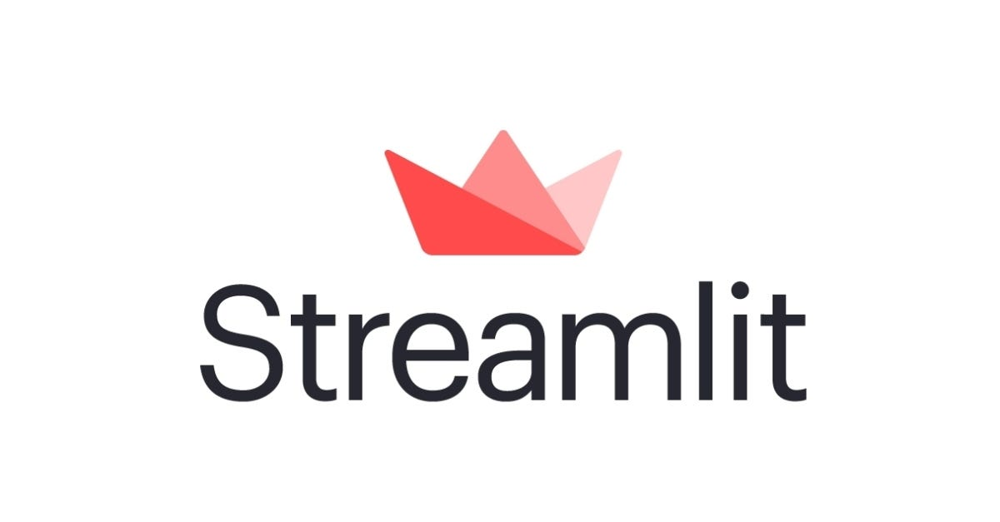
## Interface WEb para Demonstrar GRANT e REVOKE

Nesta seção, vamos construir uma interface web em **Python (Streamlit)** que permitirá:

1. Fazer **login** no banco com diferentes usuários.
2. Executar comandos SQL (SELECT, INSERT, UPDATE, DELETE).
3. Visualizar os resultados em uma tabela.
4. Demonstrar na prática as permissões concedidas ou revogadas com **GRANT** e **REVOKE**.

#### Passo a passo (resumido) para criar uma interface web com Streamlit
1. Crie o arquivo .py
2. Escrever o código com elementos do Streamlit
3. Salve o arquivo
4. Execute no terminal: streamlit run seu_arquivo.py
5. Acesse no navegador: http://localhost:8501

In [38]:
%pip install streamlit

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   -------- ------------------------------- 2.4/11.2 MB 11.7 MB/s eta 0:00:01
   ---------------- ----------------------- 4.7/11.2 MB 11.7 MB/s eta 0:00:01
   ------------------------- -------------- 7.1/11.2 MB 11.7 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.2 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 11.2 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 6.7 MB/s  0:00:00
   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   --- ------------------------------------ 2.4/29.8 MB 11.7 MB/s eta 0:00:03
   ------ --------------------------------- 4.7/29.8 MB 11.8 MB/s eta 0:00:03
   --------- ------------------------------ 7.1/29.8 MB 11.7 MB/s eta 0:00:02
   ------------ --------------------------- 9.4/29.8 MB 11.8 MB/s eta 0:00:02
   ---------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
def gerar_codigo_streamlit():
    import streamlit as st
    import pymysql
    import pandas as pd
    import time

    st.set_page_config(page_title="GRANT / REVOKE", layout="centered")
    st.title("GRANT / REVOKE - Banco de Dados")

    # Função de conexão
    def conectar(usuario, senha):
        try:
            conn = pymysql.connect(
                host="localhost",
                user=usuario,
                password=senha,
                database="sistema_empresa"  # ajuste conforme seu banco
            )
            return conn
        except pymysql.MySQLError as err:
            st.error(f"Erro de conexão: {err}")
            return None

    # Estado da sessão
    if "logged_in" not in st.session_state:
        st.session_state.logged_in = False
    if "conn" not in st.session_state:
        st.session_state.conn = None
    if "user" not in st.session_state:
        st.session_state.user = None

    # Interface de Login
    if not st.session_state.logged_in:
        user = st.text_input("Usuário")
        password = st.text_input("Senha", type="password")

        if st.button("Entrar"):
            conn = conectar(user, password)
            if conn:
                st.session_state.logged_in = True
                st.session_state.conn = conn
                st.session_state.user = user
                st.success(f"Usuário {user} conectado com sucesso!")
                time.sleep(1.5)
                st.rerun() 

    # Interface principal
    else:
        st.write(f"Usuário conectado: **{st.session_state.user}**")

        query = st.text_area("Digite um comando SQL:")

        if st.button("Executar Query"):
            try:
                cursor = st.session_state.conn.cursor()
                cursor.execute(query)

                if query.strip().lower().startswith("select"):
                    rows = cursor.fetchall()
                    cols = [desc[0] for desc in cursor.description]
                    df = pd.DataFrame(rows, columns=cols)
                    st.dataframe(df)
                else:
                    st.session_state.conn.commit()
                    st.success("Operação realizada com sucesso!")
                cursor.close()
            except pymysql.MySQLError as err:
                st.error(f"Erro SQL: {err}")

        if st.button("Sair"):
            if st.session_state.conn:
                st.session_state.conn.close()
            st.session_state.logged_in = False
            st.session_state.conn = None
            st.success("Logout realizado com sucesso.")

In [40]:
import inspect, textwrap

# Extrai o código da função e salva no arquivo .py 
codigo_streamlit = textwrap.dedent(inspect.getsource(gerar_codigo_streamlit))

# remove a primeira linha "def gerar_codigo_streamlit():" e o recuo
codigo_streamlit = "\n".join(codigo_streamlit.splitlines()[1:])
codigo_streamlit = textwrap.dedent(codigo_streamlit)

# Mostra o código que será salvo como .py
codigo_streamlit

'import streamlit as st\nimport pymysql\nimport pandas as pd\nimport time\n\nst.set_page_config(page_title="GRANT / REVOKE", layout="centered")\nst.title("GRANT / REVOKE - Banco de Dados")\n\n# Função de conexão\ndef conectar(usuario, senha):\n    try:\n        conn = pymysql.connect(\n            host="localhost",\n            user=usuario,\n            password=senha,\n            database="sistema_empresa"  # ajuste conforme seu banco\n        )\n        return conn\n    except pymysql.MySQLError as err:\n        st.error(f"Erro de conexão: {err}")\n        return None\n\n# Estado da sessão\nif "logged_in" not in st.session_state:\n    st.session_state.logged_in = False\nif "conn" not in st.session_state:\n    st.session_state.conn = None\nif "user" not in st.session_state:\n    st.session_state.user = None\n\n# Interface de Login\nif not st.session_state.logged_in:\n    user = st.text_input("Usuário")\n    password = st.text_input("Senha", type="password")\n\n    if st.button("Entr

In [41]:
with open("app_streamlit.py", "w", encoding="utf-8") as f:
    f.write(codigo_streamlit)

print("Arquivo 'app_streamlit.py' criado com sucesso!")

Arquivo 'app_streamlit.py' criado com sucesso!


### Execute o seu app_streamlit a partir do Jupyter

In [42]:
!streamlit run app_streamlit.py

^C


### Execute o seu app_streamlit como subprocess controlado

In [43]:
import subprocess
process = subprocess.Popen(["streamlit", "run", "app_streamlit.py"]) # Inicia o Streamlit como processo separado

In [44]:
process.terminate() # Encerra o processo

### Você tambám pode executar o app_streamlit informando o local onde está armazenado
- O comando abaixo pode ser executar aqui no Jupyter ou via terminal (cmd)

In [45]:
!cd /d seu_diretorio && streamlit run app_streamlit.py

O sistema n�o pode encontrar o caminho especificado.


## 13 Mysql Views

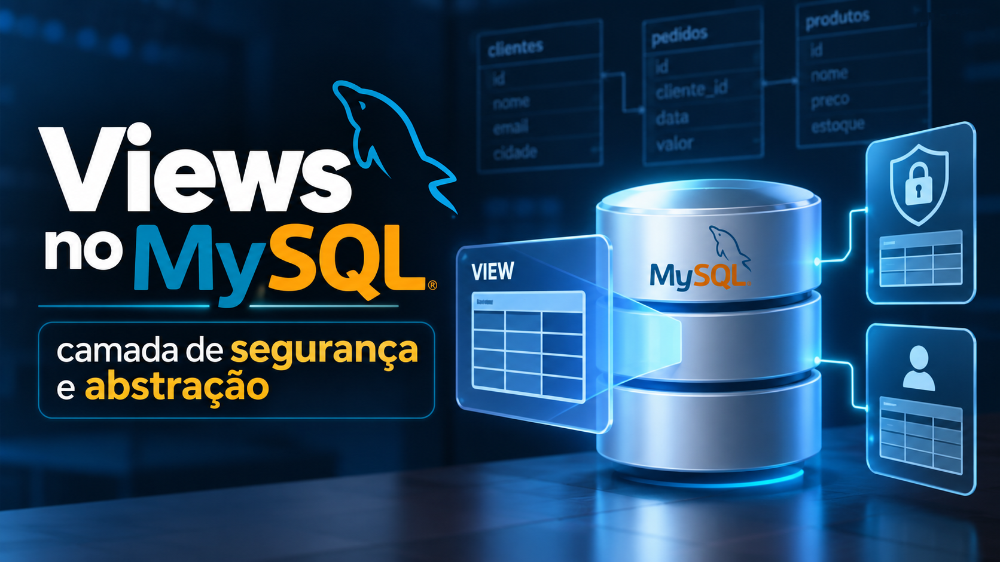

Nas aulas anteriores aprendemos a criar bancos e tabelas, a automatizar regras com **procedures, functions e triggers** e a controlar o acesso com **GRANT e REVOKE**.

Na aula 12 vimos que é possível liberar colunas específicas para um usuário (`GRANT SELECT (nome, email) ON ...`). Isso funciona, mas tem limites: não dá para esconder **linhas**, não dá para **mascarar** um dado e não dá para entregar um **resultado já calculado**.

Nesta aula vamos conhecer as **Views**, uma das ferramentas mais usadas no dia a dia para resolver exatamente esses problemas.

## O que é uma View?

Uma **View** (visão) é uma **consulta `SELECT` salva no banco de dados com um nome**.

Depois de criada, ela pode ser consultada como se fosse uma tabela:

```sql
SELECT * FROM nome_da_view;
```

Mas atenção: **a view não guarda dados**. Cada vez que você consulta a view, o MySQL executa o `SELECT` que está por trás dela e busca os dados nas tabelas originais. Por isso dizemos que a view é uma **tabela virtual**.

| | Tabela | View |
|---|---|---|
| Guarda dados? | Sim | Não, guarda apenas a consulta |
| Ocupa espaço com registros? | Sim | Não |
| Fica atualizada sozinha? | É a própria fonte | Sim, sempre reflete as tabelas |
| Pode receber `GRANT`? | Sim | Sim |

### Para que servem as views?

- **Segurança**: mostrar só algumas colunas ou linhas de uma tabela
- **Abstração**: esconder um `JOIN` complicado atrás de um nome simples
- **Padronização**: todos usam o mesmo cálculo (exemplo: média salarial por departamento)
- **Proteção contra mudanças**: se a tabela mudar, ajustamos só a view e os sistemas continuam funcionando

### Sintaxe básica

```sql
CREATE VIEW nome_da_view AS
SELECT colunas
FROM tabela
WHERE condicao;
```

## Preparando o ambiente

Vamos começar como nas aulas anteriores: importar as bibliotecas, conectar como `root` e criar o banco de dados que usaremos durante a aula.

#### Passo 1: Importar as bibliotecas

In [82]:
import os
import pymysql
import pandas as pd

#### Passo 2: Conectar ao MySQL como administrador

**O que faremos agora:** abrir uma conexão com o usuário `root`. Ele é o administrador e será o responsável por criar as tabelas, as views e os usuários.

In [83]:
conn = pymysql.connect(host="localhost", user="root", password="root")
cursor = conn.cursor()

#### Passo 3: Criar o banco de dados

In [84]:
cursor.execute("DROP DATABASE IF EXISTS sistema_empresa")
cursor.execute("CREATE DATABASE sistema_empresa")
cursor.execute("USE sistema_empresa")

0

#### Passo 4: Criar a tabela `departamentos`

**O que faremos agora:** criar a tabela de departamentos. Cada departamento tem um nome e um orçamento anual.

In [85]:
cursor.execute("""
CREATE TABLE departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(50) NOT NULL,
    orcamento DECIMAL(12,2)
)
""")

0

#### Passo 5: Criar a tabela `funcionarios`

**O que faremos agora:** criar a tabela de funcionários. Repare que ela tem **dados sensíveis**: `cpf` e `salario`. Esses são os dados que vamos proteger com as views.

A coluna `departamento_id` é uma **chave estrangeira** que liga o funcionário ao seu departamento.

In [86]:
cursor.execute("""
CREATE TABLE funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    cpf CHAR(11),
    cargo VARCHAR(50),
    salario DECIMAL(10,2),
    data_admissao DATE,
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 6: Criar a tabela `projetos`

**O que faremos agora:** criar a tabela de projetos. Cada projeto pertence a um departamento e tem um orçamento e um status.

In [87]:
cursor.execute("""
CREATE TABLE projetos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    orcamento DECIMAL(12,2),
    status VARCHAR(20),
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 7: Inserir os departamentos

**O que faremos agora:** cadastrar três departamentos. Usamos `executemany` para inserir várias linhas com um único comando.

In [88]:
departamentos = [
    ("TI", 500000.00),
    ("RH", 200000.00),
    ("Administrativo", 300000.00)
]

cursor.executemany("INSERT INTO departamentos (nome, orcamento) VALUES (%s, %s)",departamentos)

3

#### Passo 8: Inserir os funcionários

**O que faremos agora:** cadastrar os funcionários. Os quatro primeiros são os mesmos da aula 12; adicionamos mais alguns para que os resultados agrupados fiquem mais interessantes.

Lembre-se: `departamento_id` 1 = TI, 2 = RH, 3 = Administrativo.

In [89]:
funcionarios = [
    ("João Silva",     "joao.silva@empresa.com",     "12345678901", "Desenvolvedor",  8500.00, "2020-03-15", 1),
    ("Maria Santos",   "maria.santos@empresa.com",   "23456789012", "Analista de RH", 6200.00, "2019-07-01", 2),
    ("Pedro Oliveira", "pedro.oliveira@empresa.com", "34567890123", "Gerente",       12000.00, "2018-01-10", 3),
    ("Ana Costa",      "ana.costa@empresa.com",      "45678901234", "Desenvolvedora", 9100.00, "2021-05-20", 1),
    ("Lucas Pereira",  "lucas.pereira@empresa.com",  "56789012345", "Suporte",        4300.00, "2022-02-01", 1),
    ("Carla Mendes",   "carla.mendes@empresa.com",   "67890123456", "Recrutadora",    5100.00, "2021-09-13", 2),
]

cursor.executemany(
    """INSERT INTO funcionarios
       (nome, email, cpf, cargo, salario, data_admissao, departamento_id)
       VALUES (%s, %s, %s, %s, %s, %s, %s)""",
    funcionarios
)

6

#### Passo 9: Inserir os projetos

**O que faremos agora:** cadastrar os projetos da empresa.

In [90]:
projetos = [
    ("Sistema ERP",         250000.00, "Em andamento", 1),
    ("Site Corporativo",     40000.00, "Concluído",    1),
    ("App Mobile",          120000.00, "Em andamento", 1),
    ("Programa de Trainee",  30000.00, "Planejado",    2),
]

cursor.executemany(
    "INSERT INTO projetos (nome, orcamento, status, departamento_id) VALUES (%s, %s, %s, %s)", projetos)

conn.commit()

#### Passo 10: Conferir a tabela `funcionarios`

**O que faremos agora:** olhar a tabela completa. Para exibir o resultado em forma de tabela, usamos o mesmo padrão das aulas anteriores:

- `cursor.fetchall()` traz todas as linhas do resultado
- `cursor.description` guarda os nomes das colunas, que usamos como cabeçalho do DataFrame

Repare que **qualquer pessoa** com acesso a essa tabela consegue ver CPF e salário de todos. Esse é o problema que vamos resolver.

In [91]:
cursor.execute("SELECT * FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,1,João Silva,joao.silva@empresa.com,12345678901,Desenvolvedor,8500.00,2020-03-15,1
1,2,Maria Santos,maria.santos@empresa.com,23456789012,Analista de RH,6200.00,2019-07-01,2
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,34567890123,Gerente,12000.00,2018-01-10,3
3,4,Ana Costa,ana.costa@empresa.com,45678901234,Desenvolvedora,9100.00,2021-05-20,1
4,5,Lucas Pereira,lucas.pereira@empresa.com,56789012345,Suporte,4300.00,2022-02-01,1
5,6,Carla Mendes,carla.mendes@empresa.com,67890123456,Recrutadora,5100.00,2021-09-13,2


## Parte 1: Criando a primeira View

Imagine que o time de comunicação precisa de uma lista de funcionários para montar o organograma da empresa. Eles precisam de **nome, cargo e e-mail**, mas **não** devem ver CPF nem salário.

Em vez de dar acesso à tabela inteira, vamos criar uma view só com as colunas necessárias.

#### Passo 11: Escrever o SELECT que a view vai guardar

**O que faremos agora:** antes de criar uma view, é uma boa prática **testar a consulta** sozinha. Se o `SELECT` funcionar, a view também vai funcionar.

In [92]:
cursor.execute("SELECT id, nome, cargo, email FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 12: Transformar o SELECT em uma View

**O que faremos agora:** basta colocar `CREATE VIEW nome AS` na frente da consulta que acabamos de testar.

Por convenção, vamos usar o prefixo `vw_` no nome das views. Assim fica fácil diferenciar uma view de uma tabela.

In [93]:
cursor.execute("CREATE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email FROM funcionarios")

0

#### Passo 13: Consultar a View

**O que faremos agora:** consultar a view exatamente como consultamos uma tabela. Note que **não aparecem** as colunas `cpf` e `salario`.

In [94]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 14: Usar WHERE e ORDER BY na View

**O que faremos agora:** mostrar que a view aceita os mesmos recursos de uma tabela. Vamos filtrar só os desenvolvedores e ordenar por nome.

In [95]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_publico WHERE cargo LIKE 'Desenvolvedor%' ORDER BY nome")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,Ana Costa,Desenvolvedora
1,João Silva,Desenvolvedor


#### Passo 15: Provar que a View não guarda dados

**O que faremos agora:** vamos alterar o cargo do Lucas **na tabela original** e depois consultar a **view**. Se a view guardasse uma cópia dos dados, a mudança não apareceria.

In [96]:
cursor.execute("UPDATE funcionarios SET cargo = 'Analista de Suporte' WHERE nome = 'Lucas Pereira'")
conn.commit()

In [97]:
cursor.execute("SELECT * FROM vw_funcionarios_publico WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com


> A view mostrou o cargo novo imediatamente. Isso confirma que ela **executa a consulta toda vez** que é chamada, buscando os dados direto da tabela `funcionarios`.

## Parte 2: Onde as Views ficam guardadas?

As views são objetos do banco, assim como as tabelas. Vamos aprender a listá-las e ver como foram criadas.

#### Passo 17: Listar tabelas e views juntas

**O que faremos agora:** o comando `SHOW FULL TABLES` lista tudo o que existe no banco e informa o tipo de cada objeto na coluna `Table_type`:

- `BASE TABLE` = tabela de verdade
- `VIEW` = view

In [98]:
cursor.execute("SHOW FULL TABLES")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,departamentos,BASE TABLE
1,funcionarios,BASE TABLE
2,projetos,BASE TABLE
3,vw_funcionarios_publico,VIEW


#### Passo 18: Listar somente as views

**O que faremos agora:** filtrar o resultado para mostrar apenas os objetos do tipo `VIEW`.

In [99]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 19: Ver o código de uma View

**O que faremos agora:** o comando `SHOW CREATE VIEW` mostra o SQL completo que o MySQL guardou para a view. Isso é útil quando você encontra uma view criada por outra pessoa e quer entender o que ela faz.

In [100]:
cursor.execute("SHOW CREATE VIEW vw_funcionarios_publico")
resultado = cursor.fetchone()
print(resultado[1])

CREATE ALGORITHM=UNDEFINED DEFINER=`root`@`localhost` SQL SECURITY DEFINER VIEW `vw_funcionarios_publico` AS select `funcionarios`.`id` AS `id`,`funcionarios`.`nome` AS `nome`,`funcionarios`.`cargo` AS `cargo`,`funcionarios`.`email` AS `email` from `funcionarios`


> Repare em dois detalhes que o MySQL acrescentou sozinho:
> - `DEFINER=root@localhost`: quem criou a view
> - `SQL SECURITY DEFINER`: a view roda **com as permissões de quem a criou**. Vamos ver por que isso é tão importante na parte de segurança.

#### Passo 20: Consultar o dicionário de dados

**O que faremos agora:** o MySQL guarda informações sobre todas as views na tabela `information_schema.VIEWS`. Vamos consultar algumas colunas dela.

In [101]:
cursor.execute("""
SELECT TABLE_NAME, DEFINER, SECURITY_TYPE, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,DEFINER,SECURITY_TYPE,IS_UPDATABLE
0,vw_funcionarios_publico,root@localhost,DEFINER,YES


## Parte 3: Views para simplificar consultas (abstração)

Agora vamos usar views para **esconder a complexidade**. Uma consulta com `JOIN` pode ser difícil para quem está começando ou para um analista que só quer gerar um relatório. Com uma view, essa pessoa só precisa saber o nome da view.

#### Passo 21: Lembrando o problema

**O que faremos agora:** a tabela `funcionarios` só guarda o **número** do departamento (`departamento_id`). Para ver o **nome** do departamento, precisamos de um `JOIN`. Veja primeiro como a tabela aparece sem ele.

In [102]:
cursor.execute("SELECT nome, cargo, departamento_id FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento_id
0,João Silva,Desenvolvedor,1
1,Maria Santos,Analista de RH,2
2,Pedro Oliveira,Gerente,3
3,Ana Costa,Desenvolvedora,1
4,Lucas Pereira,Analista de Suporte,1
5,Carla Mendes,Recrutadora,2


#### Passo 22: Testar a consulta com JOIN

**O que faremos agora:** juntar `funcionarios` com `departamentos` para trazer o nome do departamento. Usamos apelidos (`f` e `d`) para deixar o código mais curto.

In [103]:
cursor.execute("""
SELECT f.nome, f.cargo, d.nome AS departamento
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento
0,João Silva,Desenvolvedor,TI
1,Ana Costa,Desenvolvedora,TI
2,Lucas Pereira,Analista de Suporte,TI
3,Maria Santos,Analista de RH,RH
4,Carla Mendes,Recrutadora,RH
5,Pedro Oliveira,Gerente,Administrativo


#### Passo 23: Guardar o JOIN em uma View

**O que faremos agora:** criar a view `vw_funcionarios_departamento`. Também vamos incluir a data de admissão, mas **sem o salário e sem o CPF**.

In [104]:
cursor.execute("""
CREATE VIEW vw_funcionarios_departamento AS
SELECT f.id,
       f.nome,
       f.cargo,
       d.nome AS departamento,
       f.data_admissao
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")

0

#### Passo 24: Consultar a View com JOIN

**O que faremos agora:** quem usar essa view não precisa saber nada de `JOIN`. É só um `SELECT` simples.

In [105]:
cursor.execute("SELECT * FROM vw_funcionarios_departamento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,departamento,data_admissao
0,1,João Silva,Desenvolvedor,TI,2020-03-15
1,4,Ana Costa,Desenvolvedora,TI,2021-05-20
2,5,Lucas Pereira,Analista de Suporte,TI,2022-02-01
3,2,Maria Santos,Analista de RH,RH,2019-07-01
4,6,Carla Mendes,Recrutadora,RH,2021-09-13
5,3,Pedro Oliveira,Gerente,Administrativo,2018-01-10


#### Passo 25: Filtrar pela coluna que veio do JOIN

**O que faremos agora:** filtrar pelos funcionários de TI usando o **nome** do departamento, algo que não era possível direto na tabela `funcionarios`.

In [106]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_departamento WHERE departamento = 'TI'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,João Silva,Desenvolvedor
1,Ana Costa,Desenvolvedora
2,Lucas Pereira,Analista de Suporte


#### Passo 26: Testar uma consulta com agregação

**O que faremos agora:** a diretoria quer um resumo por departamento: **quantidade de funcionários**, **média salarial** e **soma da folha de pagamento**. Ela **não** quer (e não deve) ver o salário de cada pessoa individualmente.

Vamos testar a consulta com `COUNT`, `AVG`, `SUM` e `GROUP BY`.

In [107]:
cursor.execute("""
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 27: Criar a View de resumo

**O que faremos agora:** guardar essa consulta como a view `vw_resumo_departamentos`.

Isso também resolve um problema de **padronização**: se cada analista escrevesse a própria consulta, alguém poderia esquecer o `ROUND` ou calcular a média de outro jeito. Com a view, todos usam o mesmo cálculo.

In [108]:
cursor.execute("""
CREATE VIEW vw_resumo_departamentos AS
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")

0

#### Passo 28: Consultar a View de resumo

**O que faremos agora:** consultar a view ordenando pela folha de pagamento, do maior para o menor.

In [109]:
cursor.execute("SELECT * FROM vw_resumo_departamentos ORDER BY folha_total DESC")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,Administrativo,1,12000.00,12000.00
2,RH,2,5650.00,11300.00


#### Passo 29: Uma View que usa outra View

**O que faremos agora:** uma view pode ser construída em cima de outra view. Vamos criar `vw_departamentos_acima_media`, que mostra apenas os departamentos com média salarial acima de R$ 7.000, usando a view do passo anterior.

In [110]:
cursor.execute("""
CREATE VIEW vw_departamentos_acima_media AS
SELECT departamento, media_salarial
FROM vw_resumo_departamentos
WHERE media_salarial > 7000
""")

0

In [111]:
cursor.execute("SELECT * FROM vw_departamentos_acima_media")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,media_salarial
0,TI,7300.00
1,Administrativo,12000.00


> **Cuidado:** empilhar muitas views (view de view de view) deixa o sistema difícil de entender e pode deixar as consultas mais lentas. Use com moderação.

## Parte 4: Mascaramento de dados

Às vezes um usuário precisa **saber que o dado existe**, mas não precisa vê-lo inteiro. Um exemplo comum é o atendimento: o atendente confirma "seu e-mail é jo\*\*\*@empresa.com?" sem enxergar o endereço completo.

O `GRANT` por coluna (aula 12) **não consegue fazer isso**: ou o usuário vê a coluna inteira, ou não vê nada. Com uma view, podemos **transformar** o dado antes de entregá-lo.

#### Passo 30: Conhecer as funções de texto que vamos usar

**O que faremos agora:** testar as funções que vão montar a máscara:

- `LEFT(texto, n)`: pega os `n` primeiros caracteres
- `RIGHT(texto, n)`: pega os `n` últimos caracteres
- `LOCATE('@', texto)`: diz em qual posição está o `@`
- `SUBSTRING(texto, posicao)`: pega o texto a partir de uma posição
- `CONCAT(...)`: junta vários textos

In [112]:
cursor.execute("""
SELECT email,
       LEFT(email, 2)                      AS dois_primeiros,
       LOCATE('@', email)                  AS posicao_arroba,
       SUBSTRING(email, LOCATE('@', email)) AS dominio
FROM funcionarios
LIMIT 2
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,dois_primeiros,posicao_arroba,dominio
0,joao.silva@empresa.com,jo,11,@empresa.com
1,maria.santos@empresa.com,ma,13,@empresa.com


#### Passo 31: Montar o e-mail mascarado

**O que faremos agora:** juntar as partes: dois primeiros caracteres + `***` + domínio.

In [113]:
cursor.execute("SELECT email, CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,email_mascarado
0,joao.silva@empresa.com,jo***@empresa.com
1,maria.santos@empresa.com,ma***@empresa.com
2,pedro.oliveira@empresa.com,pe***@empresa.com
3,ana.costa@empresa.com,an***@empresa.com
4,lucas.pereira@empresa.com,lu***@empresa.com
5,carla.mendes@empresa.com,ca***@empresa.com


#### Passo 32: Montar o CPF mascarado

**O que faremos agora:** fazer o mesmo com o CPF, mostrando apenas os **dois últimos dígitos**. É o formato que muitos sistemas usam: `***.***.***-01`.

In [114]:
cursor.execute("SELECT cpf, CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,cpf,cpf_mascarado
0,12345678901,***.***.***-01
1,23456789012,***.***.***-12
2,34567890123,***.***.***-23
3,45678901234,***.***.***-34
4,56789012345,***.***.***-45
5,67890123456,***.***.***-56


#### Passo 33: Criar a View de atendimento com dados mascarados

**O que faremos agora:** criar a view `vw_funcionarios_atendimento`, que entrega nome, e-mail mascarado e CPF mascarado.

In [115]:
cursor.execute("""
CREATE VIEW vw_funcionarios_atendimento AS
SELECT nome,
       CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email,
       CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf
FROM funcionarios
""")

0

In [116]:
cursor.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56


> Repare que na view as colunas mascaradas continuam com os nomes `email` e `cpf`. Para quem consulta, parece uma tabela normal, mas o dado real nunca sai do banco.

## Parte 5: Alterando e removendo Views

Requisitos mudam. Vamos ver como ajustar uma view que já existe.

#### Passo 34: Tentar criar uma View que já existe

**O que faremos agora:** a equipe pediu para incluir a **data de admissão** na `vw_funcionarios_publico`. Se usarmos `CREATE VIEW` de novo, o MySQL vai reclamar que a view já existe. Vamos ver o erro usando `try/except`.

In [117]:
try:
    cursor.execute("""
    CREATE VIEW vw_funcionarios_publico AS
    SELECT id, nome, cargo, email, data_admissao
    FROM funcionarios
    """)
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1050, "Table 'vw_funcionarios_publico' already exists")


#### Passo 35: Usar CREATE OR REPLACE VIEW

**O que faremos agora:** o comando `CREATE OR REPLACE VIEW` cria a view se ela não existir ou **substitui** a definição se ela já existir. É a forma mais comum de alterar uma view.

> Existe também o comando `ALTER VIEW`, que tem o mesmo efeito, mas só funciona se a view já existir.

In [118]:
cursor.execute("CREATE OR REPLACE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email, data_admissao FROM funcionarios")

0

In [119]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13


#### Passo 36: Remover uma View

**O que faremos agora:** a view `vw_departamentos_acima_media` não será mais usada. Vamos removê-la com `DROP VIEW IF EXISTS`.

> **Importante:** remover uma view **não apaga nenhum dado**, porque a view não guarda dados. As tabelas continuam intactas.

In [120]:
cursor.execute("DROP VIEW IF EXISTS vw_departamentos_acima_media")

0

In [121]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_atendimento,VIEW
1,vw_funcionarios_departamento,VIEW
2,vw_funcionarios_publico,VIEW
3,vw_resumo_departamentos,VIEW


## Parte 6: Views atualizáveis e WITH CHECK OPTION

Até aqui só fizemos `SELECT` nas views. Mas em alguns casos é possível fazer `INSERT`, `UPDATE` e `DELETE` **através de uma view**, e a alteração vai parar na tabela original.

Uma view é **atualizável** quando o MySQL consegue saber exatamente qual linha da tabela original corresponde a cada linha da view. Por isso, a view **não** pode ter:

- Funções de agregação (`SUM`, `AVG`, `COUNT`...)
- `GROUP BY` ou `HAVING`
- `DISTINCT`
- `UNION`
- Subconsultas no `SELECT`

#### Passo 37: Verificar quais views são atualizáveis

**O que faremos agora:** consultar de novo a coluna `IS_UPDATABLE` do `information_schema`. Repare que a view de resumo (que tem `GROUP BY`) **não** é atualizável.

In [122]:
cursor.execute("""
SELECT TABLE_NAME, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,IS_UPDATABLE
0,vw_funcionarios_atendimento,YES
1,vw_funcionarios_departamento,YES
2,vw_funcionarios_publico,YES
3,vw_resumo_departamentos,NO


#### Passo 38: Criar uma View para o departamento de TI

**O que faremos agora:** criar a view `vw_funcionarios_ti`, que mostra apenas os funcionários do departamento 1 (TI). Ela é simples, sem agregação, então será atualizável.

In [123]:
cursor.execute("""
CREATE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
""")

0

In [124]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1
2,5,Lucas Pereira,Analista de Suporte,4300.00,1


#### Passo 39: Fazer um UPDATE através da View

**O que faremos agora:** dar um aumento para o Lucas **usando a view**. Depois vamos conferir na **tabela original**.

In [125]:
cursor.execute("UPDATE vw_funcionarios_ti SET salario = 4800.00 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [126]:
cursor.execute("SELECT nome, salario FROM funcionarios WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,salario
0,Lucas Pereira,4800.00


> O salário mudou na tabela `funcionarios`. A view funcionou como uma "janela" para a tabela original.

#### Passo 40: Tentar fazer UPDATE em uma View não atualizável

**O que faremos agora:** tentar alterar a `vw_resumo_departamentos`. Como ela tem `GROUP BY` e `AVG`, o MySQL não sabe qual salário mudar e vai recusar.

In [127]:
try:
    cursor.execute("UPDATE vw_resumo_departamentos SET media_salarial = 10000 WHERE departamento = 'TI'")
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1288, 'The target table vw_resumo_departamentos of the UPDATE is not updatable')


#### Passo 41: O problema da linha que "some"

**O que faremos agora:** a view `vw_funcionarios_ti` deveria mostrar só gente de TI. Mas veja o que acontece se, **através dela**, mudarmos o departamento de alguém para RH (`departamento_id = 2`).

In [128]:
cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [129]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1


> O Lucas **sumiu** da view! O MySQL aceitou a alteração, mas o registro saiu do filtro `WHERE departamento_id = 1`.
>
> Imagine que essa view fosse usada pelo gerente de TI: ele conseguiria "transferir" funcionários para outros departamentos, mesmo que só devesse enxergar o próprio time. Isso é uma **falha de segurança**.

#### Passo 42: Desfazer a alteração

**O que faremos agora:** devolver o Lucas para o departamento de TI, agora direto na tabela original.

In [130]:
cursor.execute("UPDATE funcionarios SET departamento_id = 1 WHERE nome = 'Lucas Pereira'")
conn.commit()

#### Passo 43: Recriar a View com WITH CHECK OPTION

**O que faremos agora:** a cláusula `WITH CHECK OPTION` diz ao MySQL: **"só aceite `INSERT` ou `UPDATE` se a linha continuar visível na view depois da alteração"**.

Vamos recriar a view com essa proteção.

In [131]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
WITH CHECK OPTION
""")

0

#### Passo 44: Tentar mover alguém para fora da View

**O que faremos agora:** repetir a mesma alteração do passo 41. Agora o MySQL deve **bloquear**.

In [132]:
try:
    cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresa.vw_funcionarios_ti'")


#### Passo 45: Tentar inserir alguém de outro departamento pela View

**O que faremos agora:** o `WITH CHECK OPTION` também vale para `INSERT`. Vamos tentar cadastrar uma pessoa do Administrativo (`departamento_id = 3`) usando a view de TI.

In [133]:
try:
    cursor.execute("""
    INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
    VALUES ('Rafael Lima', 'Assistente', 3500.00, 3)
    """)
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresa.vw_funcionarios_ti'")


#### Passo 46: Inserir alguém de TI pela View

**O que faremos agora:** agora um cadastro válido, com `departamento_id = 1`. O MySQL deve aceitar.

> As colunas que não estão na view (`email`, `cpf`, `data_admissao`) ficarão como `NULL` na tabela.

In [134]:
cursor.execute("""
INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
VALUES ('Rafael Lima', 'Estagiário de TI', 2000.00, 1)
""")
conn.commit()

In [135]:
cursor.execute("SELECT * FROM funcionarios WHERE nome = 'Rafael Lima'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,7,Rafael Lima,None,None,Estagiário de TI,2000.00,None,1


## Parte 7: Views + GRANT = segurança de verdade

Agora vamos juntar o que aprendemos nesta aula com o que vimos na aula 12.

A ideia é simples:

1. O `root` cria as views
2. Cada usuário recebe `GRANT SELECT` **somente na view** que precisa
3. O usuário **não** recebe nenhuma permissão nas tabelas originais

### Mas como o usuário lê a view sem ter acesso à tabela?

Lembra do `SQL SECURITY DEFINER` que apareceu no `SHOW CREATE VIEW`? Ele significa que a view é executada **com as permissões de quem a criou** (o `root`), e não de quem está consultando.

Então o usuário só precisa de permissão na **view**. A view, por sua vez, "pega emprestada" a permissão do `root` para ler a tabela.

| Usuário | Precisa de | Vai acessar |
|---|---|---|
| `comunicacao` | Lista de funcionários sem dados sensíveis | `vw_funcionarios_publico` |
| `diretoria` | Números agregados por departamento | `vw_resumo_departamentos` |
| `atendente` | Confirmar e-mail e CPF sem ver o dado completo | `vw_funcionarios_atendimento` |

#### Passo 47: Criar os usuários

**O que faremos agora:** criar os três usuários. Assim como na aula 12, primeiro removemos o usuário caso ele já exista.

In [136]:
usuarios = [
    ("comunicacao", "senha_com123"),
    ("diretoria",   "senha_dir123"),
    ("atendente",   "senha_ate123"),
]

for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")
    cursor.execute(f"CREATE USER '{u[0]}'@'localhost' IDENTIFIED BY '{u[1]}'")

#### Passo 48: Dar permissão ao usuário `comunicacao`

**O que faremos agora:** liberar `SELECT` **apenas** na view `vw_funcionarios_publico`. Repare que o comando é igual ao `GRANT` de uma tabela: para o MySQL, a view é um objeto como outro qualquer.

In [137]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_funcionarios_publico TO 'comunicacao'@'localhost'")

0

#### Passo 49: Dar permissão ao usuário `diretoria`

**O que faremos agora:** liberar `SELECT` apenas na view de resumo.

In [138]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_resumo_departamentos TO 'diretoria'@'localhost'")

0

#### Passo 50: Dar permissão ao usuário `atendente`

**O que faremos agora:** liberar `SELECT` apenas na view com dados mascarados.

In [139]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_funcionarios_atendimento TO 'atendente'@'localhost'")

0

#### Passo 51: Aplicar as permissões

**O que faremos agora:** recarregar as permissões com `FLUSH PRIVILEGES`.

In [140]:
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 52: Conferir as permissões de cada usuário

**O que faremos agora:** usar `SHOW GRANTS` para confirmar que cada usuário tem acesso **somente** à sua view.

> A linha `GRANT USAGE ON *.*` significa apenas "pode se conectar". Ela não dá acesso a nenhum dado.

In [141]:
for u in usuarios:
    cursor.execute(f"SHOW GRANTS FOR '{u[0]}'@'localhost'")
    print(f"\n\033[1m{u[0]}\033[0m")
    for g in cursor.fetchall():
        print("  ", g[0])


comunicacao
   GRANT USAGE ON *.* TO `comunicacao`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_funcionarios_publico` TO `comunicacao`@`localhost`

diretoria
   GRANT USAGE ON *.* TO `diretoria`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_resumo_departamentos` TO `diretoria`@`localhost`

atendente
   GRANT USAGE ON *.* TO `atendente`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_funcionarios_atendimento` TO `atendente`@`localhost`


#### Passo 53: Criar a função para conectar como outro usuário

**O que faremos agora:** reaproveitar a função da aula 12 que abre uma conexão com um usuário específico. Ela devolve a conexão e o cursor.

In [142]:
def conectar_usuario(usuario, senha, banco='sistema_empresa'):
    conn = pymysql.connect(host="localhost", user=usuario, password=senha, database=banco)
    cursor = conn.cursor()
    return conn, cursor

### Testando o usuário `comunicacao`

#### Passo 54: Conectar como `comunicacao`

**O que faremos agora:** abrir uma conexão com o usuário `comunicacao`.

In [143]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

#### Passo 55: Consultar a View liberada

**O que faremos agora:** consultar a view. Deve funcionar normalmente.

In [144]:
cursor_com.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13
6,7,Rafael Lima,Estagiário de TI,NaN,None


#### Passo 56: Tentar acessar a tabela original

**O que faremos agora:** tentar ler direto da tabela `funcionarios`. Como o usuário não tem permissão nela, o MySQL deve recusar.

In [145]:
try:
    cursor_com.execute("SELECT nome, salario FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'comunicacao'@'localhost' for table 'funcionarios'")


#### Passo 57: Ver o que o usuário enxerga no banco

**O que faremos agora:** listar os objetos do banco **com a conexão do usuário**. Ele só enxerga aquilo em que tem permissão: as tabelas originais nem aparecem.

In [146]:
cursor_com.execute("SHOW FULL TABLES")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 58: Tentar alterar dados pela View

**O que faremos agora:** a view `vw_funcionarios_publico` é atualizável, mas o usuário só recebeu `SELECT`. Então um `UPDATE` deve ser bloqueado.

> Isso mostra que **o GRANT continua valendo**: a view não dá mais poder ao usuário do que aquilo que foi liberado para ele.

In [147]:
try:
    cursor_com.execute("UPDATE vw_funcionarios_publico SET cargo = 'Diretor' WHERE nome = 'João Silva'")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para alterar a view.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para alterar a view.
Erro: (1142, "UPDATE command denied to user 'comunicacao'@'localhost' for table 'vw_funcionarios_publico'")


#### Passo 59: Encerrar a conexão do usuário `comunicacao`

In [148]:
cursor_com.close()
conn_com.close()

### Testando o usuário `diretoria`

#### Passo 60: Conectar como `diretoria` e consultar o resumo

**O que faremos agora:** conectar com o usuário `diretoria` e consultar a view de resumo. Ele vê os totais, mas não o salário individual de ninguém.

In [149]:
conn_dir, cursor_dir = conectar_usuario("diretoria", "senha_dir123")
cursor_dir.execute("SELECT * FROM vw_resumo_departamentos")
pd.DataFrame(cursor_dir.fetchall(), columns=[desc[0] for desc in cursor_dir.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,4,6100.00,24400.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 61: Tentar acessar uma View que não foi liberada

**O que faremos agora:** a diretoria tem acesso à view de resumo, mas **não** à `vw_funcionarios_ti` (que mostra salários individuais). Vamos confirmar que o acesso é negado.

In [150]:
try:
    cursor_dir.execute("SELECT * FROM vw_funcionarios_ti")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mdiretoria\033[0m não tem permissão para acessar vw_funcionarios_ti.")
    print("Erro:", e)

Usuário diretoria não tem permissão para acessar vw_funcionarios_ti.
Erro: (1142, "SELECT command denied to user 'diretoria'@'localhost' for table 'vw_funcionarios_ti'")


In [151]:
cursor_dir.close()
conn_dir.close()

### Testando o usuário `atendente`

#### Passo 62: Conectar como `atendente` e consultar os dados mascarados

**O que faremos agora:** o atendente vê o nome, o e-mail e o CPF mascarados. Não existe nenhuma forma de ele descobrir o dado completo, porque o dado real nunca sai do banco.

In [152]:
conn_ate, cursor_ate = conectar_usuario("atendente", "senha_ate123")
cursor_ate.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor_ate.fetchall(), columns=[desc[0] for desc in cursor_ate.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56
6,Rafael Lima,NaN,NaN


#### Passo 63: Tentar descobrir o e-mail completo

**O que faremos agora:** o atendente tenta ler o e-mail direto na tabela. Deve ser bloqueado.

In [153]:
try:
    cursor_ate.execute("SELECT nome, email, cpf FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1matendente\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário atendente não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'atendente'@'localhost' for table 'funcionarios'")


In [154]:
cursor_ate.close()
conn_ate.close()

## Parte 8: SQL SECURITY DEFINER x INVOKER

Vimos que, por padrão, a view roda com as permissões de quem a **criou** (`DEFINER`). Existe outra opção: `SQL SECURITY INVOKER`, em que a view roda com as permissões de quem a está **chamando**.

| Opção | A view roda com permissão de... | Quando usar |
|---|---|---|
| `SQL SECURITY DEFINER` (padrão) | Quem criou a view | Quando a view é a "porta de entrada" segura para os dados |
| `SQL SECURITY INVOKER` | Quem está consultando | Quando a view serve só para simplificar e o usuário já deveria ter acesso às tabelas |

Vamos ver a diferença na prática.

#### Passo 64: Criar uma View com SQL SECURITY INVOKER

**O que faremos agora:** criar a view `vw_publico_invoker`, igual à `vw_funcionarios_publico`, mas com `SQL SECURITY INVOKER`.

In [155]:
cursor.execute("""
CREATE SQL SECURITY INVOKER VIEW vw_publico_invoker AS
SELECT id, nome, cargo, email
FROM funcionarios
""")

0

#### Passo 65: Liberar a nova View para o usuário `comunicacao`

**O que faremos agora:** dar `SELECT` na view para o mesmo usuário `comunicacao`, que **não** tem acesso à tabela `funcionarios`.

In [156]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_publico_invoker TO 'comunicacao'@'localhost'")
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 66: Testar a View INVOKER com o usuário `comunicacao`

**O que faremos agora:** consultar a view. Como agora a view roda com as permissões do **usuário** (que não pode ler `funcionarios`), a consulta deve falhar.

In [157]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

try:
    cursor_com.execute("SELECT * FROM vw_publico_invoker")
except pymysql.MySQLError as e:
    print("A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.")
    print("Erro:", e)

A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.
Erro: (1356, "View 'sistema_empresa.vw_publico_invoker' references invalid table(s) or column(s) or function(s) or definer/invoker of view lack rights to use them")


In [158]:
cursor_com.close()
conn_com.close()

> **Conclusão:** para usar a view como **camada de segurança**, ela precisa ser `SQL SECURITY DEFINER` (o padrão). Com `INVOKER`, a view serve apenas para simplificar consultas de quem já tem acesso às tabelas.

#### Passo 67: Remover a View INVOKER

**O que faremos agora:** essa view foi só para demonstração. Vamos removê-la.

In [159]:
cursor.execute("DROP VIEW IF EXISTS vw_publico_invoker")

0

## Parte 9: GRANT por coluna x View

Na aula 12 protegemos colunas assim:

```sql
GRANT SELECT (nome, email) ON sistema_empresa.funcionarios TO 'usuario'@'localhost';
```

Agora conhecemos uma segunda forma. Qual usar?

| Necessidade | GRANT por coluna | View |
|---|---|---|
| Esconder colunas | Sim | Sim |
| Esconder linhas (ex.: só funcionários de TI) | Não | Sim |
| Mascarar dados (ex.: `jo***@empresa.com`) | Não | Sim |
| Entregar dados já calculados (média, soma) | Não | Sim |
| Juntar várias tabelas em um só objeto | Não | Sim |
| `SELECT *` funciona para o usuário | Não (dá erro) | Sim |
| Não criar nenhum objeto novo no banco | Sim | Não |

**Resumo:** o GRANT por coluna é rápido para casos simples. A view é mais flexível e é a escolha mais comum em sistemas reais.

## Boas práticas com Views

1. **Use um prefixo** como `vw_` para identificar views facilmente.
2. **Teste o SELECT antes** de transformá-lo em view.
3. **Evite `SELECT *` dentro da view.** Liste as colunas: assim, se alguém adicionar uma coluna sensível na tabela, ela não aparece na view sem querer.
4. **Use `WITH CHECK OPTION`** em views com `WHERE` que permitem alterações.
5. **Dê GRANT na view, nunca na tabela**, para usuários que só precisam de parte dos dados.
6. **Não empilhe views demais.** View de view de view fica difícil de manter.
7. **Lembre que a view não deixa nada mais rápido**: ela executa a consulta toda vez. Para desempenho, o caminho são os índices (tema de uma próxima aula).

## Limpeza do ambiente

#### Passo 68: Remover os usuários criados na aula

**O que faremos agora:** apagar os usuários de teste para não deixar contas sobrando no servidor.

In [160]:
for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")

#### Passo 69: Encerrar a conexão do administrador

**O que faremos agora:** manter a conexão do `root` aberta para executar os exercícios abaixo. Ela será encerrada ao final do notebook.

> O banco `sistema_empresa` e as views continuam existindo. Você vai usá-los nos exercícios abaixo; para isso, rode novamente os Passos 1 e 2 para reconectar.

In [161]:
# A conexão será encerrada após a conclusão dos exercícios.

# Exercícios de fixação

A conexão de administrador permanece aberta nesta etapa. Se você executou a célula de encerramento da versão anterior, rode novamente os Passos 1 e 2 e selecione o banco `sistema_empresa` antes de continuar.

## Exercício 1:

**Objetivo:** Criar uma view chamada `vw_projetos_ativos` que mostre **nome do projeto**, **status** e **nome do departamento** responsável, apenas para os projetos com status `'Em andamento'`.

*Dica: você vai precisar de um `JOIN` entre `projetos` e `departamentos`.*

In [162]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_projetos_ativos AS
SELECT p.nome AS projeto, p.status, d.nome AS departamento
FROM projetos p
JOIN departamentos d ON d.id = p.departamento_id
WHERE p.status = 'Em andamento';
""")
cursor.execute("SELECT * FROM vw_projetos_ativos ORDER BY projeto;")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])


,projeto,status,departamento
0,App Mobile,Em andamento,TI
1,Sistema ERP,Em andamento,TI


## Exercício 2:

**Objetivo:** Criar uma view chamada `vw_tempo_empresa` que mostre o **nome** do funcionário, a **data de admissão** e há **quantos anos** ele está na empresa.

*Dica: use `TIMESTAMPDIFF(YEAR, data_admissao, CURDATE())`.*

In [163]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_tempo_empresa AS
SELECT nome,
       data_admissao,
       TIMESTAMPDIFF(YEAR, data_admissao, CURDATE()) AS anos_na_empresa
FROM funcionarios;
""")
cursor.execute("SELECT * FROM vw_tempo_empresa ORDER BY anos_na_empresa DESC, nome;")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])


,nome,data_admissao,anos_na_empresa
0,Pedro Oliveira,2018-01-10,8.0
1,Maria Santos,2019-07-01,7.0
2,João Silva,2020-03-15,6.0
3,Ana Costa,2021-05-20,5.0
4,Carla Mendes,2021-09-13,5.0
5,Lucas Pereira,2022-02-01,4.0
6,Rafael Lima,None,NaN


## Exercício 3:

**Objetivo:** Criar uma view chamada `vw_funcionarios_rh` que mostre apenas os funcionários do departamento de RH (`departamento_id = 2`) **com** `WITH CHECK OPTION`. Depois:

1. Faça um `UPDATE` válido pela view (exemplo: mudar o cargo da Carla)
2. Tente mover alguém para outro departamento pela view e mostre o erro com `try/except`

In [164]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_funcionarios_rh AS
SELECT id, nome, cargo, departamento_id
FROM funcionarios
WHERE departamento_id = 2
WITH CHECK OPTION;
""")
cursor.execute("UPDATE vw_funcionarios_rh SET cargo = 'Analista de RH' WHERE nome = 'Carla Mendes';")
conn.commit()

try:
    cursor.execute("UPDATE vw_funcionarios_rh SET departamento_id = 1 WHERE nome = 'Carla Mendes';")
    conn.commit()
except pymysql.MySQLError as e:
    conn.rollback()
    print("A alteração de departamento foi bloqueada pelo WITH CHECK OPTION:", e)

cursor.execute("SELECT * FROM vw_funcionarios_rh ORDER BY nome;")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])


A alteração de departamento foi bloqueada pelo WITH CHECK OPTION: (1369, "CHECK OPTION failed 'sistema_empresa.vw_funcionarios_rh'")


,id,nome,cargo,departamento_id
0,6,Carla Mendes,Analista de RH,2
1,2,Maria Santos,Analista de RH,2


## Exercício 4:

**Objetivo:** Criar uma view chamada `vw_faixa_salarial` que **não mostre o salário**, mas sim uma classificação:

- `'Até 5 mil'` para salários até 5000
- `'De 5 a 10 mil'` para salários entre 5000,01 e 10000
- `'Acima de 10 mil'` para salários maiores que 10000

*Dica: use `CASE WHEN ... THEN ... ELSE ... END`.*

In [165]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_faixa_salarial AS
SELECT nome,
       CASE
           WHEN salario <= 5000 THEN 'Até 5 mil'
           WHEN salario <= 10000 THEN 'De 5 a 10 mil'
           ELSE 'Acima de 10 mil'
       END AS faixa_salarial
FROM funcionarios;
""")
cursor.execute("SELECT * FROM vw_faixa_salarial ORDER BY nome;")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])


,nome,faixa_salarial
0,Ana Costa,De 5 a 10 mil
1,Carla Mendes,De 5 a 10 mil
2,João Silva,De 5 a 10 mil
3,Lucas Pereira,Até 5 mil
4,Maria Santos,De 5 a 10 mil
5,Pedro Oliveira,Acima de 10 mil
6,Rafael Lima,Até 5 mil


## Exercício 5:

**Objetivo:** Criar um usuário `analista_projetos` com senha `senha_proj123` e dar a ele acesso **somente** à view `vw_projetos_ativos` (Exercício 1). Depois, conecte com esse usuário e mostre que:

1. Ele consegue consultar a view
2. Ele **não** consegue consultar a tabela `projetos`
3. Ele **não** consegue consultar a tabela `departamentos`

In [166]:
cursor.execute("DROP USER IF EXISTS 'analista_projetos'@'localhost';")
cursor.execute("CREATE USER 'analista_projetos'@'localhost' IDENTIFIED BY 'senha_proj123';")
cursor.execute("GRANT SELECT ON sistema_empresa.vw_projetos_ativos TO 'analista_projetos'@'localhost';")
cursor.execute("FLUSH PRIVILEGES;")

conn_analista, cursor_analista = conectar_usuario("analista_projetos", "senha_proj123")
cursor_analista.execute("SELECT * FROM vw_projetos_ativos ORDER BY projeto;")
pd.DataFrame(cursor_analista.fetchall(), columns=[desc[0] for desc in cursor_analista.description])

for tabela in ("projetos", "departamentos"):
    try:
        cursor_analista.execute(f"SELECT * FROM {tabela};")
        print(f"O usuário consegue acessar {tabela}.")
    except pymysql.MySQLError as e:
        print(f"Acesso à tabela {tabela} negado, como esperado:", e)
        conn_analista.rollback()

cursor_analista.close()
conn_analista.close()
cursor.execute("DROP USER IF EXISTS 'analista_projetos'@'localhost';")
cursor.execute("FLUSH PRIVILEGES;")

cursor.close()
conn.close()
print("Conexão de administrador encerrada.")


Acesso à tabela projetos negado, como esperado: (1142, "SELECT command denied to user 'analista_projetos'@'localhost' for table 'projetos'")
Acesso à tabela departamentos negado, como esperado: (1142, "SELECT command denied to user 'analista_projetos'@'localhost' for table 'departamentos'")
Conexão de administrador encerrada.


## Desafio final

**Objetivo:** A empresa vai contratar uma consultoria externa para analisar a distribuição de custos. A consultoria **não** pode ver nomes, CPFs, e-mails ou salários individuais de ninguém.

Crie uma solução completa que:

1. Tenha uma view `vw_custos_departamento` com, para cada departamento: **nome do departamento**, **orçamento do departamento**, **folha salarial total**, **soma do orçamento dos projetos** e **percentual do orçamento comprometido com a folha** (`folha / orçamento * 100`, arredondado com 2 casas)
2. Crie o usuário `consultoria` com acesso **apenas** a essa view
3. Teste com `conectar_usuario` mostrando o que a consultoria consegue e o que não consegue acessar
4. Ao final, remova o usuário `consultoria`

*Dica: cuidado ao juntar funcionários e projetos no mesmo `JOIN`, pois as linhas se multiplicam e a soma sai errada. Uma saída é calcular cada soma em uma subconsulta ou em views separadas e depois juntar.*

In [168]:
conn.ping(reconnect=True)
cursor = conn.cursor()
cursor.execute("USE sistema_empresa;")

cursor.execute("""
CREATE OR REPLACE VIEW vw_custos_departamento AS
SELECT d.nome AS departamento,
       d.orcamento AS orcamento_departamento,
       COALESCE(f.folha_total, 0) AS folha_salarial_total,
       COALESCE(p.orcamento_projetos, 0) AS orcamento_total_projetos,
       ROUND(COALESCE(f.folha_total, 0) / NULLIF(d.orcamento, 0) * 100, 2)
           AS percentual_orcamento_folha
FROM departamentos d
LEFT JOIN (
    SELECT departamento_id, SUM(salario) AS folha_total
    FROM funcionarios
    GROUP BY departamento_id
) f ON f.departamento_id = d.id
LEFT JOIN (
    SELECT departamento_id, SUM(orcamento) AS orcamento_projetos
    FROM projetos
    GROUP BY departamento_id
) p ON p.departamento_id = d.id;
""")

cursor.execute("DROP USER IF EXISTS 'consultoria'@'localhost';")
cursor.execute("CREATE USER 'consultoria'@'localhost' IDENTIFIED BY 'senha_consultoria123';")
cursor.execute("GRANT SELECT ON sistema_empresa.vw_custos_departamento TO 'consultoria'@'localhost';")
cursor.execute("FLUSH PRIVILEGES;")

conn_consultoria, cursor_consultoria = conectar_usuario("consultoria", "senha_consultoria123")
cursor_consultoria.execute("SELECT * FROM vw_custos_departamento ORDER BY departamento;")
pd.DataFrame(cursor_consultoria.fetchall(), columns=[desc[0] for desc in cursor_consultoria.description])

for tabela in ("funcionarios", "projetos", "departamentos"):
    try:
        cursor_consultoria.execute(f"SELECT * FROM {tabela};")
        print(f"O usuário consegue acessar {tabela}.")
    except pymysql.MySQLError as e:
        print(f"Acesso à tabela {tabela} negado, como esperado:", e)
        conn_consultoria.rollback()

cursor_consultoria.close()
conn_consultoria.close()
cursor.execute("DROP USER IF EXISTS 'consultoria'@'localhost';")
cursor.execute("FLUSH PRIVILEGES;")


Acesso à tabela funcionarios negado, como esperado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'funcionarios'")
Acesso à tabela projetos negado, como esperado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'projetos'")
Acesso à tabela departamentos negado, como esperado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'departamentos'")


C:\Users\41228408807\AppData\Local\Temp\ipykernel_28856\3203087756.py:1: DeprecationWarning: The 'reconnect' argument is deprecated. Create a new connection if you want to reconnect.
  conn.ping(reconnect=True)


0